In [1]:

from pathlib import Path
import torch
import shutil
import os

# 1. Check GPU
print("=" * 60)
print("1. GPU CHECK")
print("=" * 60)
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")
else:
    print("No CUDA GPU detected. Training may be very slow.")

# 2. Check persistent storage
print("\n" + "=" * 60)
print("2. PERSISTENT STORAGE CHECK")
print("=" * 60)

ROOT = Path("/workspace")
print(f"Workspace path: {ROOT}")
print(f"Workspace accessible: {ROOT.exists()}")

if ROOT.exists():
    usage = shutil.disk_usage(ROOT)
    print(f"Reported total space: {usage.total / 1024**3:.2f} GiB")
    print(f"Reported free space: {usage.free / 1024**3:.2f} GiB")
    print("Note: network-volume capacity figures may not reflect its actual quota.")

    print("\nTop-level workspace contents:")
    for item in sorted(ROOT.iterdir()):
        kind = "Directory" if item.is_dir() else "File"
        size = ""
        if item.is_file():
            size = f" ({item.stat().st_size / 1024**3:.2f} GiB)"
        print(f"  {kind}: {item.name}{size}")

# 3. Check likely dataset locations
print("\n" + "=" * 60)
print("3. DATASET CHECK")
print("=" * 60)

search_roots = [
    ROOT / "datasets",
    ROOT / "runpod_upload",
    ROOT / "experiments",
    ROOT / "backups",
]

dataset_markers = {
    "leftImg8bit",
    "leftImg8bit_foggy",
    "gtFine",
    "gtCoarse",
    "cityscapes",
    "foggy_cityscapes",
}

found_datasets = []

for base in search_roots:
    if not base.exists():
        print(f"Not found: {base}")
        continue

    print(f"Searching likely dataset location: {base}")

    for current, dirs, files in os.walk(base):
        current_path = Path(current)
        depth = len(current_path.relative_to(base).parts)

        if depth >= 6:
            dirs[:] = []

        for name in dirs:
            if name in dataset_markers:
                path = current_path / name
                found_datasets.append(path)
                print(f"  Found possible dataset folder: {path}")

if not found_datasets:
    print("No standard Cityscapes/Foggy Cityscapes folders found in these locations.")

# 4. Check archive files
print("\n" + "=" * 60)
print("4. DATASET ARCHIVE CHECK")
print("=" * 60)

archives = list(ROOT.glob("*.tar")) + list(ROOT.glob("*.tar.*"))

if archives:
    for archive in sorted(archives):
        size_gib = archive.stat().st_size / 1024**3
        print(f"Found archive: {archive.name} | Size: {size_gib:.2f} GiB")
else:
    print("No matching dataset archives found directly under /workspace.")

# 5. Check project and Adaptive Teacher code
print("\n" + "=" * 60)
print("5. PROJECT AND ADAPTIVE TEACHER CHECK")
print("=" * 60)

project_markers = {
    "milestone2",
    "adaptive_teacher",
}

config_markers = {
    "baseline_config.yaml",
    "train_net.py",
    "requirements.txt",
    "environment.yml",
}

found_project_items = []

for base in search_roots:
    if not base.exists():
        continue

    for current, dirs, files in os.walk(base):
        current_path = Path(current)
        depth = len(current_path.relative_to(base).parts)

        if depth >= 6:
            dirs[:] = []

        for name in dirs:
            if name in project_markers:
                found_project_items.append(current_path / name)
                print(f"Found project/code folder: {current_path / name}")

        for name in files:
            if name in config_markers:
                found_project_items.append(current_path / name)
                print(f"Found project/config file: {current_path / name}")

if not found_project_items:
    print("No recognized project/config files found in the searched locations.")

# 6. Summary
print("\n" + "=" * 60)
print("6. SUMMARY")
print("=" * 60)
print(f"Workspace accessible: {ROOT.exists()}")
print(f"CUDA GPU available: {torch.cuda.is_available()}")
print(f"Possible dataset folders found: {len(found_datasets)}")
print(f"Possible project/code items found: {len(found_project_items)}")
print(f"Archive files found at workspace root: {len(archives)}")
print("\nThis cell only inspected files; it did not extract, install, or modify anything.")

1. GPU CHECK
PyTorch version: 2.8.0+cu128
CUDA available: True
GPU name: NVIDIA RTX PRO 4000 Blackwell

2. PERSISTENT STORAGE CHECK
Workspace path: /workspace
Workspace accessible: True
Reported total space: 1048576.00 GiB
Reported free space: 1048576.00 GiB
Note: network-volume capacity figures may not reflect its actual quota.

Top-level workspace contents:
  Directory: .ipynb_checkpoints
  Directory: adaptive_teacher_recovered
  Directory: backups
  File: cityscapes.tar.part.aa (2.00 GiB)
  File: cityscapes.tar.part.ab (2.00 GiB)
  File: cityscapes.tar.part.ac (2.00 GiB)
  File: cityscapes.tar.part.ad (2.00 GiB)
  File: cityscapes.tar.part.ae (2.00 GiB)
  File: cityscapes.tar.part.af (2.00 GiB)
  File: cityscapes.tar.part.ag (2.00 GiB)
  File: cityscapes.tar.part.ah (2.00 GiB)
  File: cityscapes.tar.part.ai (2.00 GiB)
  File: cityscapes.tar.part.aj (2.00 GiB)
  File: cityscapes.tar.part.ak (2.00 GiB)
  File: cityscapes.tar.part.al (2.00 GiB)
  File: cityscapes.tar.part.am (2.00 GiB)

In [2]:

from pathlib import Path
from collections import Counter
import os

ROOT = Path("/workspace/datasets")

print("=" * 65)
print("1. CITYSCAPES AND FOGGY CITYSCAPES FOLDER STRUCTURE")
print("=" * 65)

dataset_roots = [
    ROOT / "cityscapes",
    ROOT / "cityscapes_foggy",
]

image_exts = {".png", ".jpg", ".jpeg"}
annotation_keywords = ("_gtFine_", "_gtCoarse_", "_labelIds", "_labelTrainIds")

for dataset in dataset_roots:
    print(f"\nDataset: {dataset}")
    print(f"Folder exists: {dataset.is_dir()}")

    if not dataset.is_dir():
        continue

    # Show the top-level structure
    print("Top-level folders:")
    for item in sorted(dataset.iterdir()):
        print(f"  {'[DIR] ' if item.is_dir() else '[FILE]'} {item.name}")

    # Inspect standard dataset folders without scanning unrelated directories
    for subname in ("leftImg8bit", "leftImg8bit_foggy", "gtFine", "gtCoarse"):
        subdir = dataset / subname
        if not subdir.is_dir():
            continue

        print(f"\n  Folder: {subdir}")
        children = sorted(subdir.iterdir())
        print("  Immediate contents:")
        for child in children[:8]:
            print(f"    {child.name}{'/' if child.is_dir() else ''}")
        if len(children) > 8:
            print(f"    ... and {len(children) - 8} more entries")

        # Count image files by split (train, val, test) or other immediate subfolder
        counts = Counter()
        examples = []
        fog_tokens = Counter()

        for current, dirs, files in os.walk(subdir):
            # Avoid unexpectedly deep or unrelated traversal
            current_path = Path(current)
            depth = len(current_path.relative_to(subdir).parts)
            if depth > 5:
                dirs[:] = []
                continue

            for filename in files:
                file_path = Path(filename)
                if file_path.suffix.lower() not in image_exts:
                    continue

                relative = current_path.relative_to(subdir)
                split = relative.parts[0] if relative.parts else "(root)"
                counts[split] += 1

                if len(examples) < 5:
                    examples.append(str(relative / filename))

                # Foggy Cityscapes commonly encodes fog density in filenames
                if "foggy" in filename.lower():
                    for token in ("beta_0.005", "beta_0.01", "beta_0.02"):
                        if token in filename:
                            fog_tokens[token] += 1

        print("  Image counts by first-level folder:")
        if counts:
            for split, count in sorted(counts.items()):
                print(f"    {split}: {count:,}")
        else:
            print("    No PNG/JPG images found.")

        if examples:
            print("  Example filenames:")
            for example in examples:
                print(f"    {example}")

        if fog_tokens:
            print("  Fog-severity filename counts:")
            for token, count in sorted(fog_tokens.items()):
                print(f"    {token}: {count:,}")

print("\n" + "=" * 65)
print("2. INITIAL INTERPRETATION")
print("=" * 65)
print("We need source images, source annotations, and foggy target images.")
print("Fog severity must be confirmed from actual filenames or folder names.")
print("This cell only inspected existing files; it did not modify anything.")

1. CITYSCAPES AND FOGGY CITYSCAPES FOLDER STRUCTURE

Dataset: /workspace/datasets/cityscapes
Folder exists: True
Top-level folders:
  [DIR]  gtFine
  [DIR]  leftImg8bit

  Folder: /workspace/datasets/cityscapes/leftImg8bit
  Immediate contents:
    train/
    val/
  Image counts by first-level folder:
    train: 2,975
    val: 500
  Example filenames:
    train/aachen/aachen_000000_000019_leftImg8bit.png
    train/aachen/aachen_000001_000019_leftImg8bit.png
    train/aachen/aachen_000002_000019_leftImg8bit.png
    train/aachen/aachen_000003_000019_leftImg8bit.png
    train/aachen/aachen_000004_000019_leftImg8bit.png

  Folder: /workspace/datasets/cityscapes/gtFine
  Immediate contents:
    train/
    val/
  Image counts by first-level folder:
    train: 8,925
    val: 1,500
  Example filenames:
    train/aachen/aachen_000000_000019_gtFine_color.png
    train/aachen/aachen_000000_000019_gtFine_instanceIds.png
    train/aachen/aachen_000000_000019_gtFine_labelIds.png
    train/aachen/aac

In [3]:

from pathlib import Path
from collections import Counter
from PIL import Image

# ------------------------------------------------------------
# 1. Dataset locations
# ------------------------------------------------------------
ROOT = Path("/workspace/datasets")
CLEAR = ROOT / "cityscapes"
FOGGY = ROOT / "cityscapes_foggy"

SEVERITIES = ["0.005", "0.01", "0.02"]
SPLITS = ["train", "val"]

print("=" * 68)
print("CITYSCAPES / FOGGY CITYSCAPES PAIRING VALIDATION")
print("=" * 68)

def index_images(folder, suffix):
    """Index images by their Cityscapes image ID, excluding the suffix."""
    result = {}
    duplicates = []

    if not folder.exists():
        return result, duplicates

    for path in folder.rglob("*.png"):
        if path.name.endswith(suffix):
            image_id = path.name[:-len(suffix)]
            if image_id in result:
                duplicates.append(image_id)
            else:
                result[image_id] = path

    return result, duplicates

overall_ok = True

for split in SPLITS:
    print(f"\n{'-' * 68}\nSPLIT: {split.upper()}\n{'-' * 68}")

    clear_dir = CLEAR / "leftImg8bit" / split
    label_dir = CLEAR / "gtFine" / split
    fog_dir = FOGGY / "leftImg8bit" / split

    # Clear image IDs: remove the standard Cityscapes suffix.
    clear, clear_dupes = index_images(clear_dir, "_leftImg8bit.png")

    # Use semantic labelIds, not color or instanceIds, for label checks.
    labels, label_dupes = index_images(label_dir, "_gtFine_labelIds.png")

    print(f"Clear images:              {len(clear):,}")
    print(f"Semantic label maps:       {len(labels):,}")
    print(f"Duplicate clear IDs:       {len(clear_dupes)}")
    print(f"Duplicate label IDs:       {len(label_dupes)}")

    missing_labels = sorted(set(clear) - set(labels))
    labels_without_images = sorted(set(labels) - set(clear))

    print(f"Clear images missing labels: {len(missing_labels)}")
    print(f"Labels without clear images: {len(labels_without_images)}")

    if missing_labels:
        print("Examples missing labels:", missing_labels[:3])
    if labels_without_images:
        print("Examples labels without images:", labels_without_images[:3])

    # Index foggy images separately for each severity.
    fog_indices = {}
    for severity in SEVERITIES:
        suffix = f"_leftImg8bit_foggy_beta_{severity}.png"
        fog_indices[severity], dupes = index_images(fog_dir, suffix)

        fog_ids = set(fog_indices[severity])
        clear_ids = set(clear)

        missing_fog = sorted(clear_ids - fog_ids)
        extra_fog = sorted(fog_ids - clear_ids)

        print(
            f"Fog beta={severity}: {len(fog_ids):,} images | "
            f"missing versions: {len(missing_fog)} | "
            f"unmatched versions: {len(extra_fog)} | "
            f"duplicate IDs: {len(dupes)}"
        )

        if missing_fog:
            print("  Missing examples:", missing_fog[:3])
        if extra_fog:
            print("  Unmatched examples:", extra_fog[:3])

        if missing_fog or extra_fog or dupes:
            overall_ok = False

    if missing_labels or labels_without_images or clear_dupes or label_dupes:
        overall_ok = False

    # Compare dimensions for a few matched clear/foggy/label examples.
    common_ids = sorted(set(clear) & set(labels))
    print("\nSample image-dimension checks:")

    for image_id in common_ids[:3]:
        clear_path = clear[image_id]
        label_path = labels[image_id]

        with Image.open(clear_path) as im:
            clear_size = im.size
        with Image.open(label_path) as im:
            label_size = im.size

        fog_sizes = {}
        for severity in SEVERITIES:
            fog_path = fog_indices[severity].get(image_id)
            if fog_path:
                with Image.open(fog_path) as im:
                    fog_sizes[severity] = im.size

        dimensions_ok = (
            clear_size == label_size
            and all(size == clear_size for size in fog_sizes.values())
        )

        print(
            f"  {image_id}: clear={clear_size}, labels={label_size}, "
            f"fog={fog_sizes}, match={dimensions_ok}"
        )

        if not dimensions_ok:
            overall_ok = False

print("\n" + "=" * 68)
print("VALIDATION SUMMARY")
print("=" * 68)
print("PASS: all checked pairings are consistent" if overall_ok
      else "CHECK REQUIRED: inspect the mismatches reported above")
print("No files were modified.")

CITYSCAPES / FOGGY CITYSCAPES PAIRING VALIDATION

--------------------------------------------------------------------
SPLIT: TRAIN
--------------------------------------------------------------------
Clear images:              2,975
Semantic label maps:       2,975
Duplicate clear IDs:       0
Duplicate label IDs:       0
Clear images missing labels: 0
Labels without clear images: 0
Fog beta=0.005: 2,975 images | missing versions: 0 | unmatched versions: 0 | duplicate IDs: 0
Fog beta=0.01: 2,975 images | missing versions: 0 | unmatched versions: 0 | duplicate IDs: 0
Fog beta=0.02: 2,975 images | missing versions: 0 | unmatched versions: 0 | duplicate IDs: 0

Sample image-dimension checks:
  aachen_000000_000019: clear=(2048, 1024), labels=(2048, 1024), fog={'0.005': (2048, 1024), '0.01': (2048, 1024), '0.02': (2048, 1024)}, match=True
  aachen_000001_000019: clear=(2048, 1024), labels=(2048, 1024), fog={'0.005': (2048, 1024), '0.01': (2048, 1024), '0.02': (2048, 1024)}, match=True
  a

In [4]:

from pathlib import Path
import importlib.util
import torch
import torchvision

ROOT = Path("/workspace")
CITY = ROOT / "datasets" / "cityscapes"

print("=" * 65)
print("1. GPU AND DETECTOR LIBRARIES")
print("=" * 65)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for package in ["detectron2", "pycocotools", "cv2", "PIL", "yaml"]:
    print(f"{package}:",
          "INSTALLED" if importlib.util.find_spec(package) else "NOT INSTALLED")

print("\n" + "=" * 65)
print("2. CITYSCAPES ANNOTATION TYPES")
print("=" * 65)

for split in ["train", "val"]:
    folder = CITY / "gtFine" / split
    print(f"\n{split.upper()}:")

    for suffix in [
        "_gtFine_labelIds.png",
        "_gtFine_instanceIds.png",
        "_gtFine_color.png",
        "_gtFine_polygons.json",
    ]:
        matches = list(folder.rglob(f"*{suffix}"))
        print(f"  {suffix}: {len(matches):,} files")
        if matches:
            print("    Example:", matches[0].relative_to(CITY))

print("\n" + "=" * 65)
print("3. SEARCH FOR EXISTING TRAINING CODE / ANNOTATION CONVERTERS")
print("=" * 65)

search_roots = [
    ROOT / "experiments",
    ROOT / "runpod_upload",
    ROOT / "backups",
    ROOT / "external",
    ROOT / "src",
]

found = 0
wanted = {
    "train_net.py",
    "trainer.py",
    "baseline_config.yaml",
    "environment.yml",
    "requirements.txt",
    "instancesonly_gtFine_train.json",
    "instancesonly_gtFine_val.json",
}

for base in search_roots:
    if not base.exists():
        continue

    for path in base.rglob("*"):
        if path.is_file() and (
            path.name in wanted
            or ("cityscapes" in path.name.lower()
                and path.suffix.lower() in {".json", ".yaml", ".yml"})
        ):
            print(path)
            found += 1
            if found >= 80:
                print("Stopped listing after 80 matches.")
                break
    if found >= 80:
        break

if found == 0:
    print("No matching training/configuration/conversion files found in searched folders.")

print("\nInspection complete. No files were modified.")

1. GPU AND DETECTOR LIBRARIES
PyTorch: 2.8.0+cu128
Torchvision: 0.23.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 4000 Blackwell
detectron2: NOT INSTALLED
pycocotools: NOT INSTALLED
cv2: NOT INSTALLED
PIL: INSTALLED
yaml: INSTALLED

2. CITYSCAPES ANNOTATION TYPES

TRAIN:
  _gtFine_labelIds.png: 2,975 files
    Example: gtFine/train/aachen/aachen_000000_000019_gtFine_labelIds.png
  _gtFine_instanceIds.png: 2,975 files
    Example: gtFine/train/aachen/aachen_000000_000019_gtFine_instanceIds.png
  _gtFine_color.png: 2,975 files
    Example: gtFine/train/aachen/aachen_000000_000019_gtFine_color.png
  _gtFine_polygons.json: 2,975 files
    Example: gtFine/train/aachen/aachen_000000_000019_gtFine_polygons.json

VAL:
  _gtFine_labelIds.png: 500 files
    Example: gtFine/val/frankfurt/frankfurt_000000_000294_gtFine_labelIds.png
  _gtFine_instanceIds.png: 500 files
    Example: gtFine/val/frankfurt/frankfurt_000000_000294_gtFine_instanceIds.png
  _gtFine_color.png: 500 files
    Example: gt

In [5]:

from pathlib import Path
import json
from datetime import datetime

BASE = Path("/workspace/experiments/cityscapes_to_foggy")

print("=" * 72)
print("EXISTING EXPERIMENT AUDIT")
print("=" * 72)
print("Root:", BASE)
print("Exists:", BASE.exists())

if not BASE.exists():
    print("Experiment directory not found.")
else:
    # 1. List files in the experiment tree, excluding large datasets.
    print("\n1. FILE INVENTORY")
    print("-" * 72)

    files = sorted(p for p in BASE.rglob("*") if p.is_file())
    print("Total files:", len(files))

    for p in files[:250]:
        size_mb = p.stat().st_size / (1024 * 1024)
        modified = datetime.fromtimestamp(p.stat().st_mtime).strftime(
            "%Y-%m-%d %H:%M"
        )
        print(f"{p.relative_to(BASE)} | {size_mb:.2f} MB | modified {modified}")

    if len(files) > 250:
        print(f"... {len(files) - 250} more files omitted")

    # 2. Highlight checkpoints, logs, predictions, and metrics.
    print("\n2. TRAINING / EVALUATION EVIDENCE")
    print("-" * 72)

    keywords = (
        "model", "checkpoint", "weight", "metrics", "result",
        "log", "events", "eval", "inference", "prediction",
        "summary", "stdout", "stderr"
    )
    matches = [
        p for p in files
        if any(word in p.name.lower() for word in keywords)
        or p.suffix.lower() in {".pth", ".pt", ".pkl", ".log", ".out"}
    ]

    if matches:
        for p in matches[:150]:
            print(f"{p.relative_to(BASE)} ({p.stat().st_size / (1024*1024):.2f} MB)")
    else:
        print("No obvious checkpoints, logs, or metric files found.")

    # 3. Read small JSON config/metadata files to identify prior work.
    print("\n3. JSON CONFIGURATION / METADATA")
    print("-" * 72)

    json_files = [
        p for p in files
        if p.suffix.lower() == ".json" and p.stat().st_size < 2_000_000
    ]

    for p in json_files[:30]:
        print(f"\nFILE: {p.relative_to(BASE)}")
        try:
            with p.open("r", encoding="utf-8") as f:
                obj = json.load(f)

            if isinstance(obj, dict):
                print("Top-level keys:", list(obj.keys())[:40])

                # Show small configuration values, not large prediction arrays.
                for key, value in list(obj.items())[:20]:
                    if isinstance(value, (str, int, float, bool)) or value is None:
                        print(f"  {key}: {value}")
                    elif isinstance(value, list):
                        print(f"  {key}: list with {len(value)} items")
                    elif isinstance(value, dict):
                        print(f"  {key}: dict with {len(value)} keys")
            elif isinstance(obj, list):
                print("List length:", len(obj))
                if obj:
                    print("First item:", str(obj[0])[:500])
            else:
                print("JSON type:", type(obj).__name__)
        except Exception as e:
            print("Could not read:", repr(e))

    # 4. Check whether the experiment folders contain any real model weights.
    print("\n4. CHECKPOINT SUMMARY")
    print("-" * 72)

    checkpoints = [
        p for p in files
        if p.suffix.lower() in {".pth", ".pt", ".pkl"}
        or "checkpoint" in p.name.lower()
    ]

    if checkpoints:
        for p in checkpoints:
            print(f"{p.relative_to(BASE)} | {p.stat().st_size / (1024*1024):.2f} MB")
    else:
        print("No model checkpoint files found in this experiment tree.")

print("\nAudit complete. No files were modified.")

EXISTING EXPERIMENT AUDIT
Root: /workspace/experiments/cityscapes_to_foggy
Exists: True

1. FILE INVENTORY
------------------------------------------------------------------------
Total files: 46
reproducibility/EXPERIMENT_LOG.md | 0.00 MB | modified 2026-10-09 12:16
reproducibility/configs/cityscapes_100_seed.json | 0.02 MB | modified 2026-10-09 12:14
reproducibility/configs/source_only_benchmark.yaml | 0.00 MB | modified 2026-10-09 12:14
reproducibility/configs/source_only_resume_test.yaml | 0.00 MB | modified 2026-10-09 12:14
reproducibility/configs/source_only_smoke.yaml | 0.00 MB | modified 2026-10-09 12:14
reproducibility/source_only_scheduler_fix.patch | 0.00 MB | modified 2026-10-09 12:14
source_only/benchmark/config.yaml | 0.01 MB | modified 2026-10-09 11:33
source_only/benchmark/events.out.tfevents.1791545646.3fa32a8c2abc.66947.0 | 0.01 MB | modified 2026-10-09 11:42
source_only/benchmark/inference/cityscapes_foggy_val_coco_format.json | 15.04 MB | modified 2026-10-09 11:38
s

In [6]:

from pathlib import Path
import json

BASE = Path("/workspace/experiments/cityscapes_to_foggy")

print("=" * 72)
print("SOURCE-ONLY RUN RESULTS: EVIDENCE CHECK")
print("=" * 72)

def print_tail(path, n=22):
    path = Path(path)
    print(f"\n--- {path.relative_to(BASE)} ---")
    if not path.exists():
        print("File not found")
        return
    lines = path.read_text(errors="replace").splitlines()
    print(f"Total lines: {len(lines)}")
    for line in lines[-n:]:
        print(line[:350])

# 1. What the training logs say
for rel in [
    "source_only/smoke_run_04.log",
    "source_only/benchmark_100.log",
    "source_only/resume_test.log",
    "source_only/smoke/log.txt",
    "source_only/benchmark/log.txt",
    "source_only/resume_test/log.txt",
]:
    print_tail(BASE / rel)

# 2. Parse metrics.json as JSON Lines (one JSON record per line)
print("\n" + "=" * 72)
print("METRIC RECORDS")
print("=" * 72)

for run in ["smoke", "benchmark", "resume_test"]:
    path = BASE / "source_only" / run / "metrics.json"
    print(f"\n--- {run}: {path.name} ---")

    if not path.exists():
        print("Missing metrics file")
        continue

    records = []
    for line_no, line in enumerate(
        path.read_text(errors="replace").splitlines(), start=1
    ):
        if not line.strip():
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError as exc:
            print(f"Could not parse line {line_no}: {exc}")

    print("Parsed records:", len(records))
    for record in records[-5:]:
        # Keep output compact; show iteration, losses and evaluation metrics.
        print({
            key: value
            for key, value in record.items()
            if any(term in key.lower() for term in [
                "iter", "loss", "lr", "ap", "bbox", "time", "data"
            ])
        })

# 3. Training configuration
print("\n" + "=" * 72)
print("BENCHMARK CONFIGURATION")
print("=" * 72)

for rel in [
    "source_only/benchmark/config.yaml",
    "source_only/resume_test/config.yaml",
    "source_only/configs/source_only_smoke.yaml",
    "reproducibility/configs/source_only_benchmark.yaml",
    "reproducibility/configs/source_only_resume_test.yaml",
    "reproducibility/EXPERIMENT_LOG.md",
]:
    path = BASE / rel
    print(f"\n--- {rel} ---")
    if path.exists():
        content = path.read_text(errors="replace").splitlines()
        for line in content[:100]:
            print(line[:300])
        if len(content) > 100:
            print(f"... {len(content) - 100} additional lines")
    else:
        print("File not found")

print("\nAudit complete. No files were modified.")

SOURCE-ONLY RUN RESULTS: EVIDENCE CHECK

--- source_only/smoke_run_04.log ---
Total lines: 531
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
COCOeval_opt.evaluate() finished in 1.18 seconds.
Accumulating evaluation results...
COCOeval_opt.accumulate() finished in 0.25 seconds.
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=

In [7]:

from pathlib import Path
import json
from collections import Counter

BASE = Path("/workspace/experiments/cityscapes_to_foggy")
RUN = BASE / "source_only" / "benchmark"

print("=" * 72)
print("DIAGNOSTIC 1: GROUND-TRUTH CATEGORY MAPPING")
print("=" * 72)

gt_path = RUN / "inference" / "cityscapes_foggy_val_coco_format.json"
pred_path = RUN / "inference" / "coco_instances_results.json"
config_path = RUN / "config.yaml"
log_path = RUN / "log.txt"

gt = json.loads(gt_path.read_text())
print("Ground-truth JSON type:", type(gt).__name__)

if isinstance(gt, dict):
    print("Top-level keys:", list(gt.keys()))
    categories = gt.get("categories", [])
    annotations = gt.get("annotations", [])
    images = gt.get("images", [])
    print("Images:", len(images))
    print("Annotations:", len(annotations))
    print("Ground-truth categories:")
    for cat in categories:
        print(" ", cat)

    gt_counts = Counter(a.get("category_id") for a in annotations)
    print("\nGround-truth annotation counts by category_id:")
    print(dict(sorted(gt_counts.items(), key=lambda x: str(x[0]))))
else:
    categories = []
    annotations = []
    print("Unexpected ground-truth structure; inspect JSON format.")

print("\n" + "=" * 72)
print("DIAGNOSTIC 2: PREDICTED CATEGORY MAPPING")
print("=" * 72)

preds = json.loads(pred_path.read_text())
print("Prediction records:", len(preds))

pred_counts = Counter(p.get("category_id") for p in preds)
print("Predictions by category_id:")
print(dict(sorted(pred_counts.items(), key=lambda x: str(x[0]))))

if isinstance(gt, dict):
    gt_ids = {c.get("id") for c in categories}
    pred_ids = set(pred_counts)
    print("Ground-truth category IDs:", sorted(gt_ids, key=str))
    print("Predicted category IDs:", sorted(pred_ids, key=str))
    print("Prediction IDs absent from ground truth:", sorted(pred_ids - gt_ids, key=str))
    print("Ground-truth IDs never predicted:", sorted(gt_ids - pred_ids, key=str))

print("\nFirst 3 predictions:")
for p in preds[:3]:
    print(p)

print("\n" + "=" * 72)
print("DIAGNOSTIC 3: MODEL CONFIGURATION")
print("=" * 72)

if config_path.exists():
    lines = config_path.read_text(errors="replace").splitlines()
    terms = [
        "WEIGHTS:", "NUM_CLASSES:", "ROI_HEADS:", "ROI_BOX_HEAD:",
        "CHECKPOINT", "PRETRAIN", "BASE_LR:", "MAX_ITER:",
        "TRAIN:", "TEST:", "BACKBONE:"
    ]
    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            print(f"{i+1}: {line}")
            # Print a few indented lines for context around key sections.
            if any(term in line for term in ["ROI_HEADS:", "ROI_BOX_HEAD:", "BACKBONE:"]):
                for extra in lines[i+1:i+5]:
                    print("   ", extra)

print("\n" + "=" * 72)
print("DIAGNOSTIC 4: TRAINING / EVALUATION WARNINGS")
print("=" * 72)

if log_path.exists():
    lines = log_path.read_text(errors="replace").splitlines()
    terms = [
        "Loading weights", "checkpoint", "pretrained", "incompatible",
        "missing keys", "unexpected keys", "WARNING", "WARNING",
        "thing_classes", "category_id", "not found", "AP,AP50"
    ]
    found = 0
    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in terms):
            print(f"{i+1}: {line[:350]}")
            found += 1
            if found >= 70:
                print("Stopped after 70 matching log lines.")
                break
    if found == 0:
        print("No matching lines found.")
else:
    print("Training log not found.")

print("\nDiagnostics complete. No files were modified.")

DIAGNOSTIC 1: GROUND-TRUTH CATEGORY MAPPING
Ground-truth JSON type: dict
Top-level keys: ['info', 'images', 'categories', 'licenses', 'annotations']
Images: 1500
Annotations: 31236
Ground-truth categories:
  {'id': 0, 'name': 'person'}
  {'id': 1, 'name': 'rider'}
  {'id': 2, 'name': 'car'}
  {'id': 3, 'name': 'truck'}
  {'id': 4, 'name': 'bus'}
  {'id': 5, 'name': 'train'}
  {'id': 6, 'name': 'motorcycle'}
  {'id': 7, 'name': 'bicycle'}

Ground-truth annotation counts by category_id:
{0: 10368, 1: 1632, 2: 14292, 3: 279, 4: 294, 5: 69, 6: 447, 7: 3855}

DIAGNOSTIC 2: PREDICTED CATEGORY MAPPING
Prediction records: 37236
Predictions by category_id:
{0: 565, 2: 36671}
Ground-truth category IDs: [0, 1, 2, 3, 4, 5, 6, 7]
Predicted category IDs: [0, 2]
Prediction IDs absent from ground truth: []
Ground-truth IDs never predicted: [1, 3, 4, 5, 6, 7]

First 3 predictions:
{'image_id': 'frankfurt_000000_000294_leftImg8bit_foggy_beta_0.005.png', 'category_id': 2, 'bbox': [1507.6490478515625, 471

In [8]:

from pathlib import Path
from collections import Counter
import os

ROOT = Path("/workspace/experiments/cityscapes_to_foggy")
REPO = Path("/workspace")

print("=" * 70)
print("1. CHECK CONFIGURATION AND INITIALIZATION")
print("=" * 70)

config_path = ROOT / "source_only/benchmark/config.yaml"

if config_path.exists():
    text = config_path.read_text(errors="replace")
    lines = text.splitlines()

    for i, line in enumerate(lines):
        if any(key in line for key in [
            "_BASE_", "WEIGHTS:", "NUM_CLASSES:",
            "NAME: build_vgg_backbone", "DATASETS:",
            "TRAIN:", "TEST:", "PIXEL_MEAN:", "PIXEL_STD:"
        ]):
            print(f"{i + 1}: {line}")
else:
    print("Config not found:", config_path)

print("\n" + "=" * 70)
print("2. FIND THE ORIGINAL ADAPTIVE TEACHER CONFIG")
print("=" * 70)

for base in [REPO / "configs", REPO / "AdaptiveTeacher",
             REPO / "domain-adaptation-object-detection"]:
    if base.exists():
        for p in base.rglob("faster_rcnn_VGG_cross_city.yaml"):
            print("Found:", p)

print("\n" + "=" * 70)
print("3. CHECK REGISTERED SOURCE DATASET METADATA")
print("=" * 70)

try:
    from detectron2.data import DatasetCatalog, MetadataCatalog

    dataset_name = "cityscapes_fine_instance_seg_train"

    print("Registered:", dataset_name in DatasetCatalog.list())

    if dataset_name in DatasetCatalog.list():
        metadata = MetadataCatalog.get(dataset_name)
        print("thing_classes:", getattr(metadata, "thing_classes", None))
        print("thing_dataset_id_to_contiguous_id:",
              getattr(metadata, "thing_dataset_id_to_contiguous_id", None))

        records = DatasetCatalog.get(dataset_name)
        print("Number of source images:", len(records))

        category_counts = Counter()
        for record in records:
            for ann in record.get("annotations", []):
                category_counts[ann.get("category_id")] += 1

        print("Source annotation counts by category_id:")
        print(dict(sorted(category_counts.items(),
                          key=lambda item: str(item[0]))))

        if records:
            print("\nFirst source record:")
            print("Image:", records[0].get("file_name"))
            print("Image dimensions:",
                  records[0].get("width"), "x",
                  records[0].get("height"))
            print("First 5 annotations:",
                  records[0].get("annotations", [])[:5])

except Exception as e:
    print("Dataset metadata inspection failed:",
          type(e).__name__, str(e))

print("\n" + "=" * 70)
print("4. CHECK FOR AVAILABLE INITIALIZATION CHECKPOINTS")
print("=" * 70)

for base in [REPO / "checkpoints", REPO / "models",
             ROOT / "source_only"]:
    if base.exists():
        found = 0
        for p in base.rglob("*.pth"):
            print(f"{p} ({p.stat().st_size / (1024**2):.1f} MB)")
            found += 1
            if found >= 15:
                print("Stopped listing after 15 checkpoints in", base)
                break
        if found == 0:
            print("No .pth files found under", base)

print("\nDiagnostic complete. No files were modified.")

1. CHECK CONFIGURATION AND INITIALIZATION
9:   SAMPLER_TRAIN: TrainingSampler
11: DATASETS:
13:   PRECOMPUTED_PROPOSAL_TOPK_TEST: 1000
14:   PRECOMPUTED_PROPOSAL_TOPK_TRAIN: 2000
15:   PROPOSAL_FILES_TEST: []
16:   PROPOSAL_FILES_TRAIN: []
17:   TEST:
19:   TRAIN:
38:   MAX_SIZE_TEST: 1333
39:   MAX_SIZE_TRAIN: 1333
40:   MIN_SIZE_TEST: 800
41:   MIN_SIZE_TRAIN:
65:     NAME: build_vgg_backbone
83:   PIXEL_MEAN:
87:   PIXEL_STD:
114:     BBOX_REG_WEIGHTS: &id002
134:     NMS_THRESH_TEST: 0.5
136:     NUM_CLASSES: 80
139:     SCORE_THRESH_TEST: 0.05
141:     TOPK_CANDIDATES_TEST: 1000
143:     BBOX_REG_WEIGHTS:
164:     BBOX_REG_WEIGHTS: *id001
188:     NMS_THRESH_TEST: 0.5
189:     NUM_CLASSES: 8
192:     SCORE_THRESH_TEST: 0.05
224:     BBOX_REG_WEIGHTS: *id002
240:     POST_NMS_TOPK_TEST: 1000
241:     POST_NMS_TOPK_TRAIN: 2000
242:     PRE_NMS_TOPK_TEST: 6000
243:     PRE_NMS_TOPK_TRAIN: 12000
258:     NUM_CLASSES: 54
259:   WEIGHTS: ''
312: TEST:

2. FIND THE ORIGINAL ADAPTIVE TEAC

In [9]:

from pathlib import Path
import sys
import subprocess

workspace = Path("/workspace")
experiment = workspace / "experiments/cityscapes_to_foggy"

print("=" * 65)
print("1. CURRENT JUPYTER PYTHON ENVIRONMENT")
print("=" * 65)
print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])

for package in ["torch", "torchvision", "detectron2", "pycocotools"]:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True, text=True
    )
    print(f"\n{package}:")
    print(result.stdout.strip() or "Not installed in this environment")

print("\n" + "=" * 65)
print("2. EXPERIMENT LOG")
print("=" * 65)
log = experiment / "reproducibility/EXPERIMENT_LOG.md"
if log.exists():
    print(log.read_text(errors="replace")[:9000])
else:
    print("Not found:", log)

print("\n" + "=" * 65)
print("3. RELEVANT REPOSITORY FILES")
print("=" * 65)

terms = [
    "train_net.py",
    "faster_rcnn_VGG_cross_city.yaml",
    "requirements.txt",
    "environment.yml",
    "setup.py",
    "pyproject.toml",
]

count = 0
for path in workspace.rglob("*"):
    if not path.is_file():
        continue
    if any(part in {".git", ".cache", "__pycache__"} for part in path.parts):
        continue
    if path.name in terms:
        print(path)
        count += 1
        if count >= 60:
            print("Listing capped at 60 files.")
            break

print("\n" + "=" * 65)
print("4. RECORDED TRAINING COMMANDS")
print("=" * 65)

for folder in [
    experiment / "reproducibility",
    experiment / "source_only/benchmark",
]:
    if folder.exists():
        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in {
                ".sh", ".txt", ".md", ".log"
            }:
                try:
                    content = path.read_text(errors="replace")
                    matches = [
                        line for line in content.splitlines()
                        if any(term in line.lower() for term in [
                            "train_net", "python ", "detectron2",
                            "config-file", "weights"
                        ])
                    ]
                    if matches:
                        print(f"\n--- {path} ---")
                        print("\n".join(matches[:30]))
                except Exception as e:
                    print("Could not read", path, e)

print("\nRead-only diagnostic complete.")

1. CURRENT JUPYTER PYTHON ENVIRONMENT
Python executable: /usr/local/bin/python
Python version: 3.12.3

torch:
Name: torch
Version: 2.8.0+cu128
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org/
Author: PyTorch Team
Author-email: packages@pytorch.org
License: BSD-3-Clause
Location: /usr/local/lib/python3.12/dist-packages
Requires: filelock, fsspec, jinja2, networkx, nvidia-cublas-cu12, nvidia-cuda-cupti-cu12, nvidia-cuda-nvrtc-cu12, nvidia-cuda-runtime-cu12, nvidia-cudnn-cu12, nvidia-cufft-cu12, nvidia-cufile-cu12, nvidia-curand-cu12, nvidia-cusolver-cu12, nvidia-cusparse-cu12, nvidia-cusparselt-cu12, nvidia-nccl-cu12, nvidia-nvjitlink-cu12, nvidia-nvtx-cu12, setuptools, sympy, triton, typing-extensions
Required-by: torchaudio, torchvision

torchvision:
Name: torchvision
Version: 0.23.0+cu128
Summary: image and video datasets and models for torch deep learning
Home-page: https://github.com/pytorch/vision
Author: PyTorch Co

In [10]:

from pathlib import Path
import os

print("Current working directory:", os.getcwd())

print("\n" + "=" * 60)
print("1. WORKSPACE CONTENTS")
print("=" * 60)

for folder in [Path("/workspace"), Path("/workspace/experiments"),
               Path("/root"), Path("/app")]:
    print(f"\n{folder}:")
    if folder.exists():
        for item in list(folder.iterdir())[:35]:
            print(" ", item.name, "/" if item.is_dir() else "")
    else:
        print("  Directory does not exist")

print("\n" + "=" * 60)
print("2. EXPERIMENT FOLDER CONTENTS")
print("=" * 60)

exp = Path("/workspace/experiments/cityscapes_to_foggy")
for folder in [
    exp,
    exp / "reproducibility",
    exp / "reproducibility/configs",
    exp / "source_only",
    Path("/workspace/AdaptiveTeacher"),
    Path("/workspace/adaptive_teacher"),
]:
    print(f"\n{folder}:")
    if folder.exists():
        for item in list(folder.iterdir())[:30]:
            print(" ", item.name, "/" if item.is_dir() else "")
    else:
        print("  Not found")

print("\n" + "=" * 60)
print("3. SEARCH FOR TRAINING ENTRY POINTS")
print("=" * 60)

search_roots = [
    Path("/workspace"),
    Path("/root"),
    Path("/app"),
]

seen = set()
for root in search_roots:
    if not root.exists():
        continue
    for name in ["train_net.py", "faster_rcnn_VGG_cross_city.yaml",
                 "source_only_benchmark.yaml"]:
        try:
            for path in root.rglob(name):
                if str(path) not in seen:
                    print(path)
                    seen.add(str(path))
                if len(seen) >= 80:
                    break
        except (PermissionError, OSError):
            pass
        if len(seen) >= 80:
            break
    if len(seen) >= 80:
        print("Search capped at 80 matches.")
        break

if not seen:
    print("No matching files found in the searched locations.")

print("\nRead-only inspection complete.")

Current working directory: /workspace

1. WORKSPACE CONTENTS

/workspace:
  .ipynb_checkpoints /
  adaptive_teacher_recovered /
  backups /
  cityscapes.tar.part.aa 
  cityscapes.tar.part.ab 
  cityscapes.tar.part.ac 
  cityscapes.tar.part.ad 
  cityscapes.tar.part.ae 
  cityscapes.tar.part.af 
  cityscapes.tar.part.ag 
  cityscapes.tar.part.ah 
  cityscapes.tar.part.ai 
  cityscapes.tar.part.aj 
  cityscapes.tar.part.ak 
  cityscapes.tar.part.al 
  cityscapes.tar.part.am 
  cityscapes.tar.part.an 
  cityscapes.tar.part.ao 
  datasets /
  experiment.ipynb 
  experiments /
  runpod_cityscapes_trainval.tar 
  runpod_upload /

/workspace/experiments:
  cityscapes_to_foggy /

/root:
  .bashrc 
  .profile 
  .ssh /
  .local /
  .ipython /
  .jupyter /
  .nv /
  .launchpadlib /

/app:
  Directory does not exist

2. EXPERIMENT FOLDER CONTENTS

/workspace/experiments/cityscapes_to_foggy:
  pretrained /
  reproducibility /
  source_only /

/workspace/experiments/cityscapes_to_foggy/reproducibil

In [12]:

from pathlib import Path
import tarfile

backup = Path("/workspace/backups/phd_code_backup.tar.gz")

print("=" * 65)
print("1. BACKUP ARCHIVE")
print("=" * 65)

if backup.exists():
    print("Archive size:", round(backup.stat().st_size / (1024**2), 2), "MB")

    with tarfile.open(backup, "r:gz") as tar:
        members = tar.getmembers()
        print("Total archive entries:", len(members))

        keywords = [
            "train_net.py",
            "faster_rcnn_vgg_cross_city.yaml",
            "adaptive_teacher",
            "detectron2",
            "requirements.txt",
            "setup.py",
            "environment.yml",
            "baseline",
            "trainer.py",
            "config"
        ]

        print("\nRelevant archived paths:")
        shown = 0
        for member in members:
            name = member.name
            if any(k in name.lower() for k in keywords):
                print(name)
                shown += 1
                if shown >= 100:
                    print("Listing capped at 100 matches.")
                    break

        if shown == 0:
            print("No matching code/configuration paths found.")
else:
    print("Backup archive not found.")

print("\n" + "=" * 65)
print("2. SAVED ENVIRONMENT INFORMATION")
print("=" * 65)

for name in ["python_version.txt", "python_requirements.txt"]:
    path = Path("/workspace/backups") / name
    print(f"\n--- {name} ---")
    if path.exists():
        print(path.read_text(errors="replace")[:6000])
    else:
        print("Not found.")

print("\nInspection complete. Nothing was extracted or modified.")

1. BACKUP ARCHIVE
Archive size: 0.8 MB
Total archive entries: 393

Relevant archived paths:
adaptive_teacher
adaptive_teacher/.git
adaptive_teacher/.git/branches
adaptive_teacher/.git/hooks
adaptive_teacher/.git/hooks/applypatch-msg.sample
adaptive_teacher/.git/hooks/commit-msg.sample
adaptive_teacher/.git/hooks/fsmonitor-watchman.sample
adaptive_teacher/.git/hooks/post-update.sample
adaptive_teacher/.git/hooks/pre-applypatch.sample
adaptive_teacher/.git/hooks/pre-commit.sample
adaptive_teacher/.git/hooks/pre-push.sample
adaptive_teacher/.git/hooks/pre-rebase.sample
adaptive_teacher/.git/hooks/pre-receive.sample
adaptive_teacher/.git/hooks/prepare-commit-msg.sample
adaptive_teacher/.git/hooks/update.sample
adaptive_teacher/.git/info
adaptive_teacher/.git/info/exclude
adaptive_teacher/.git/description
adaptive_teacher/.git/refs
adaptive_teacher/.git/refs/heads
adaptive_teacher/.git/refs/heads/main
adaptive_teacher/.git/refs/tags
adaptive_teacher/.git/refs/remotes
adaptive_teacher/.git/r

In [13]:

from pathlib import Path
import tarfile

archive = Path("/workspace/backups/phd_code_backup.tar.gz")

with tarfile.open(archive, "r:gz") as tar:
    links = [
        (member.name, member.linkname, member.issym(), member.islnk())
        for member in tar.getmembers()
        if member.issym() or member.islnk()
    ]

print(f"Total symbolic/hard links: {len(links)}")
for name, target, is_symbolic, is_hard in links:
    print(f"\nPath:   {name}")
    print(f"Target: {target}")
    print(f"Type:   {'symbolic' if is_symbolic else 'hard link'}")

Total symbolic/hard links: 4

Path:   adaptive_teacher/datasets/cityscapes/leftImg8bit
Target: /workspace/datasets/cityscapes/leftImg8bit
Type:   symbolic

Path:   adaptive_teacher/datasets/cityscapes/gtFine
Target: /workspace/datasets/cityscapes/gtFine
Type:   symbolic

Path:   adaptive_teacher/datasets/cityscapes_foggy/leftImg8bit
Target: /workspace/datasets/cityscapes_foggy/leftImg8bit
Type:   symbolic

Path:   adaptive_teacher/datasets/cityscapes_foggy/gtFine
Target: /workspace/datasets/cityscapes/gtFine
Type:   symbolic


In [16]:

from pathlib import Path
import tarfile

archive = Path("/workspace/backups/phd_code_backup.tar.gz")
destination = Path("/workspace/adaptive_teacher_recovered")

if destination.exists():
    raise FileExistsError(
        f"{destination} already exists. Please inspect it before continuing."
    )

dataset_links = {
    "adaptive_teacher/datasets/cityscapes/leftImg8bit",
    "adaptive_teacher/datasets/cityscapes/gtFine",
    "adaptive_teacher/datasets/cityscapes_foggy/leftImg8bit",
    "adaptive_teacher/datasets/cityscapes_foggy/gtFine",
}

with tarfile.open(archive, "r:gz") as tar:
    members = tar.getmembers()

    # Validate every archive path before extracting.
    for member in members:
        path = Path(member.name)
        if path.is_absolute() or ".." in path.parts:
            raise ValueError(f"Unsafe archive path: {member.name}")

    # Extract regular files and directories only.
    # Skip all links, including the four known dataset links.
    safe_members = [
        member for member in members
        if member.isdir() or member.isfile()
    ]

    destination.mkdir(parents=True)
    try:
        tar.extractall(
            path=destination,
            members=safe_members,
            filter="data",
        )
    except Exception:
        import shutil
        shutil.rmtree(destination, ignore_errors=True)
        raise

repo = destination / "adaptive_teacher"

print("Repository restored:", repo.is_dir())
print("README exists:", (repo / "README.md").is_file())
print("Trainer exists:", (repo / "adapteacher/engine/trainer.py").is_file())
print("Training script exists:", (repo / "train_net.py").is_file())

print("\nDataset paths remain available:")
for path in [
    Path("/workspace/datasets/cityscapes/leftImg8bit"),
    Path("/workspace/datasets/cityscapes/gtFine"),
    Path("/workspace/datasets/cityscapes_foggy/leftImg8bit"),
    Path("/workspace/datasets/cityscapes_foggy/gtFine"),
]:
    print(f"{path}: {path.exists()}")

print("\nRestoration finished. No training was started.")

In [15]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

print("=" * 60)
print("1. REPOSITORY VERSION")
print("=" * 60)

for name in [".git/HEAD", ".git/refs/heads/main"]:
    path = repo / name
    print(f"{name}:")
    print(path.read_text(errors="replace").strip() if path.is_file()
          else "Not available as a loose Git reference")

print("\n" + "=" * 60)
print("2. RELEVANT CONFIGURATION FILES")
print("=" * 60)

configs = []
for pattern in ["*.yaml", "*.yml"]:
    configs.extend(
        p for p in repo.rglob(pattern)
        if ".git" not in p.parts and "__pycache__" not in p.parts
    )

for path in sorted(configs):
    rel = path.relative_to(repo)
    if any(word in str(rel).lower() for word in [
        "cityscapes", "foggy", "vgg", "faster", "base"
    ]):
        print(rel)

print(f"\nTotal YAML/YML files found: {len(configs)}")

print("\n" + "=" * 60)
print("3. TRAINING AND INSTALLATION INSTRUCTIONS")
print("=" * 60)

readme = repo / "README.md"
if readme.is_file():
    lines = readme.read_text(errors="replace").splitlines()
    keywords = [
        "install", "train", "cityscapes", "foggy",
        "pretrain", "weight", "detectron2", "checkpoint"
    ]
    matches = [
        (i, line) for i, line in enumerate(lines)
        if any(word in line.lower() for word in keywords)
    ]

    for i, line in matches[:35]:
        print(f"{i + 1}: {line[:220]}")
else:
    print("README not found")

print("\n" + "=" * 60)
print("4. POTENTIAL PRETRAINED WEIGHTS")
print("=" * 60)

weight_files = [
    p for p in repo.rglob("*")
    if p.is_file()
    and ".git" not in p.parts
    and p.suffix.lower() in {
        ".pth", ".pkl", ".pt", ".ckpt", ".model"
    }
]

if weight_files:
    for p in weight_files[:40]:
        print(f"{p.relative_to(repo)} ({p.stat().st_size / (1024**2):.1f} MB)")
    if len(weight_files) > 40:
        print(f"... plus {len(weight_files) - 40} more")
else:
    print("No model-weight files found inside the repository.")

print("\n" + "=" * 60)
print("5. DATASET REGISTRATION FILES")
print("=" * 60)

for relative in [
    "adapteacher/data/datasets/builtin.py",
    "adapteacher/data/datasets/cityscapes_foggy.py",
    "adapteacher/config.py",
    "train_net.py",
]:
    path = repo / relative
    print(f"{relative}: {'FOUND' if path.is_file() else 'MISSING'}")

1. REPOSITORY VERSION
.git/HEAD:
ref: refs/heads/main
.git/refs/heads/main:
5256463ad9ec90fd5ba84ebb8d53bed56bd369df

2. RELEVANT CONFIGURATION FILES
configs/Base-RCNN-C4.yaml
configs/faster_rcnn_R101_cross_clipart.yaml
configs/faster_rcnn_R101_cross_clipart_b4.yaml
configs/faster_rcnn_R101_cross_water.yaml
configs/faster_rcnn_VGG_cross_city.yaml
experiments/cityscapes_to_foggy/source_only/source_only_benchmark.yaml
experiments/cityscapes_to_foggy/source_only/source_only_resume_test.yaml
experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml

Total YAML/YML files found: 8

3. TRAINING AND INSTALLATION INSTRUCTIONS
18: # Installation
23: - PyTorch ≥ 1.5 and torchvision that matches the PyTorch installation.
24: - Detectron2 == 0.3 (The version I used to run my code)
31: ## Install python env
33: To install required dependencies on the virtual environment of the python (e.g., virtualenv for python3), please run the following command at the root of this code:
46: ## Build Dete

In [17]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

files_to_inspect = [
    "configs/faster_rcnn_VGG_cross_city.yaml",
    "configs/Base-RCNN-C4.yaml",
    "experiments/cityscapes_to_foggy/source_only/source_only_benchmark.yaml",
    "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml",
    "experiments/cityscapes_to_foggy/source_only/source_only_resume_test.yaml",
]

keywords = (
    "BASE", "WEIGHTS", "MODEL:", "BACKBONE", "VGG",
    "DEVICE", "DATASETS", "TRAIN:", "TEST:", "NUM_CLASSES",
    "BATCH_SIZE", "IMS_PER_BATCH", "MAX_ITER", "BASE_LR",
    "SOLVER:", "STEPS", "WARMUP", "CHECKPOINT", "OUTPUT_DIR",
    "CROSS_DATASET", "SEMISUPNET"
)

for relative in files_to_inspect:
    path = repo / relative
    print("\n" + "=" * 75)
    print(relative, "|", "FOUND" if path.is_file() else "MISSING")
    print("=" * 75)

    if not path.is_file():
        continue

    lines = path.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines, start=1):
        stripped = line.strip()
        if stripped and not stripped.startswith("#"):
            if any(key.lower() in stripped.lower() for key in keywords):
                print(f"{i:4}: {line}")

print("\n" + "=" * 75)
print("README TRAINING / WEIGHT INSTRUCTIONS")
print("=" * 75)

readme_lines = (repo / "README.md").read_text(errors="replace").splitlines()
for start, end in [(90, 155)]:
    for i in range(start, min(end, len(readme_lines)) + 1):
        print(f"{i:4}: {readme_lines[i-1]}")


configs/faster_rcnn_VGG_cross_city.yaml | FOUND
   1: _BASE_: "./Base-RCNN-C4.yaml"
   2: MODEL:
   5:   BACKBONE:
   6:     NAME: "build_vgg_backbone"
  15:     IN_FEATURES: ["vgg4"]
  19:     NUM_CLASSES: 8
  20:     IN_FEATURES: ["vgg4"]
  25: SOLVER:
  26:   LR_SCHEDULER_NAME: "WarmupTwoStageMultiStepLR"
  27:   STEPS: (60000, 80000, 90000, 360000)
  29:   MAX_ITER: 100000
  32:   BASE_LR: 0.04
  35: DATASETS:
  36: DATASETS:
  37:   CROSS_DATASET: True
  40:   TEST: ("cityscapes_foggy_val",)
  41: SEMISUPNET:
  49:   DIS_TYPE: "vgg4" #["concate","p2","multi"]
  50: TEST:

configs/Base-RCNN-C4.yaml | FOUND
   1: MODEL:
   4:     PRE_NMS_TOPK_TEST: 6000
   5:     POST_NMS_TOPK_TEST: 1000
   8: DATASETS:
   9:   TRAIN: ("coco_2017_train",)
  10:   TEST: ("coco_2017_val",)
  11: SOLVER:
  12:   IMS_PER_BATCH: 16
  13:   BASE_LR: 0.02
  14:   STEPS: (60000, 80000)
  15:   MAX_ITER: 90000
  17:   MIN_SIZE_TRAIN: (600,)

experiments/cityscapes_to_foggy/source_only/source_only_benchmark.

In [18]:

from pathlib import Path
import re

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

print("=" * 65)
print("1. COMPLETE CITYSCAPES CONFIGURATION")
print("=" * 65)

config = repo / "configs/faster_rcnn_VGG_cross_city.yaml"
for i, line in enumerate(config.read_text(errors="replace").splitlines(), 1):
    print(f"{i:3}: {line}")

print("\n" + "=" * 65)
print("2. WEIGHT-LOADING LOGIC IN TRAINING CODE")
print("=" * 65)

search_roots = [
    repo / "train_net.py",
    repo / "adapteacher",
]

patterns = re.compile(
    r"MODEL\.WEIGHTS|DetectionCheckpointer|resume_or_load|"
    r"load_state_dict|checkpointer\.load|pretrained",
    re.IGNORECASE,
)

for item in search_roots:
    files = [item] if item.is_file() else list(item.rglob("*.py"))
    for path in files:
        if "__pycache__" in path.parts:
            continue
        lines = path.read_text(errors="replace").splitlines()
        hits = [i for i, line in enumerate(lines) if patterns.search(line)]
        for i in hits[:8]:
            start, end = max(0, i - 2), min(len(lines), i + 3)
            print(f"\n--- {path.relative_to(repo)}:{i+1} ---")
            for j in range(start, end):
                print(f"{j+1:4}: {lines[j]}")
        if hits:
            print()

print("\n" + "=" * 65)
print("3. EXISTING CHECKPOINT FILES")
print("=" * 65)

roots = [
    Path("/workspace/experiments/cityscapes_to_foggy/source_only"),
    Path("/workspace/adaptive_teacher_recovered"),
]

for root in roots:
    print(f"\n{root}")
    if not root.exists():
        print("Directory not found")
        continue
    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".pth", ".pkl", ".pt", ".ckpt"
        }:
            print(f"{path} | {path.stat().st_size / (1024**2):.1f} MB")

1. COMPLETE CITYSCAPES CONFIGURATION
  1: _BASE_: "./Base-RCNN-C4.yaml"
  2: MODEL:
  3:   # META_ARCHITECTURE: "TwoStagePseudoLabGeneralizedRCNN"
  4:   META_ARCHITECTURE: "DAobjTwoStagePseudoLabGeneralizedRCNN"
  5:   BACKBONE:
  6:     NAME: "build_vgg_backbone"
  7:   MASK_ON: False
  8:   RESNETS:
  9:     DEPTH: 101
 10:   PROPOSAL_GENERATOR:
 11:     NAME: "PseudoLabRPN"
 12:   # RPN:
 13:   #   POSITIVE_FRACTION: 0.25
 14:   RPN:
 15:     IN_FEATURES: ["vgg4"]
 16:   ROI_HEADS:
 17:     NAME: "StandardROIHeadsPseudoLab"
 18:     LOSS: "CrossEntropy" # variant: "CrossEntropy"
 19:     NUM_CLASSES: 8
 20:     IN_FEATURES: ["vgg4"]
 21:   ROI_BOX_HEAD:
 22:     NAME: "FastRCNNConvFCHead"
 23:     NUM_FC: 2
 24:     POOLER_RESOLUTION: 7
 25: SOLVER:
 26:   LR_SCHEDULER_NAME: "WarmupTwoStageMultiStepLR"
 27:   STEPS: (60000, 80000, 90000, 360000)
 28:   FACTOR_LIST: (1, 1, 1, 1, 1)
 29:   MAX_ITER: 100000
 30:   IMG_PER_BATCH_LABEL: 16
 31:   IMG_PER_BATCH_UNLABEL: 16
 32:   BASE_LR

In [19]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
experiment = Path("/workspace/experiments/cityscapes_to_foggy/source_only")

def show_context(path, start, end):
    path = Path(path)
    print(f"\n--- {path} (lines {start}-{end}) ---")
    if not path.is_file():
        print("File not found")
        return
    lines = path.read_text(errors="replace").splitlines()
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1:4}: {lines[i]}")

print("=" * 70)
print("1. VGG16 BACKBONE INITIALIZATION")
print("=" * 70)

vgg_files = [
    p for p in (repo / "adapteacher").rglob("*.py")
    if "vgg" in p.name.lower()
]
for path in vgg_files:
    show_context(path, 1, min(180, len(path.read_text(errors="replace").splitlines())))

print("\n" + "=" * 70)
print("2. TRAINER REGISTRATION AND BASELINE IMPLEMENTATION")
print("=" * 70)

trainer_path = repo / "adapteacher/engine/trainer.py"
lines = trainer_path.read_text(errors="replace").splitlines()
for i, line in enumerate(lines):
    if "class Baseline" in line or "class Trainer" in line or '"baseline"' in line.lower():
        start, end = max(0, i - 5), min(len(lines), i + 65)
        print(f"\n--- trainer.py around line {i+1} ---")
        for j in range(start, end):
            print(f"{j+1:4}: {lines[j]}")

print("\n" + "=" * 70)
print("3. EFFECTIVE SOURCE-ONLY CONFIGURATION")
print("=" * 70)

for relative in [
    "configs/faster_rcnn_VGG_cross_city.yaml",
    "configs/Base-RCNN-C4.yaml",
    "experiments/cityscapes_to_foggy/source_only/source_only_benchmark.yaml",
]:
    show_context(repo / relative, 1, 60)

print("\n" + "=" * 70)
print("4. PRIOR RUN: INITIALIZATION AND EVALUATION LOG")
print("=" * 70)

for log in [
    experiment / "benchmark/log.txt",
    experiment / "benchmark/metrics.json",
    Path("/workspace/experiments/cityscapes_to_foggy/reproducibility/EXPERIMENT_LOG.md"),
]:
    if log.is_file():
        print(f"\n--- {log} ---")
        lines = log.read_text(errors="replace").splitlines()
        if log.name == "EXPERIMENT_LOG.md":
            matches = [
                i for i, line in enumerate(lines)
                if any(k in line.lower() for k in [
                    "weight", "scratch", "baseline", "pretrain",
                    "detectron", "source-only", "source only"
                ])
            ]
            selected = sorted({
                j for i in matches[:20]
                for j in range(max(0, i-1), min(len(lines), i+2))
            })
            for j in selected:
                print(f"{j+1:4}: {lines[j]}")
        else:
            for i, line in enumerate(lines[:60], 1):
                print(f"{i:4}: {line}")

1. VGG16 BACKBONE INITIALIZATION

--- /workspace/adaptive_teacher_recovered/adaptive_teacher/adapteacher/modeling/meta_arch/vgg.py (lines 1-150) ---
   1: # Copyright (c) Facebook, Inc. and its affiliates. All Rights Reserved
   2: import torch.nn as nn
   3: import copy
   4: import torch
   5: from typing import Union, List, Dict, Any, cast
   6: from detectron2.modeling.backbone import (
   7:     ResNet,
   8:     Backbone,
   9:     build_resnet_backbone,
  10:     BACKBONE_REGISTRY
  11: )
  12: from detectron2.modeling.backbone.fpn import FPN, LastLevelMaxPool, LastLevelP6P7
  13: 
  14: 
  15: 
  16: def make_layers(cfg: List[Union[str, int]], batch_norm: bool = False) -> nn.Sequential:
  17:     layers: List[nn.Module] = []
  18:     in_channels = 3
  19:     for v in cfg:
  20:         if v == 'M':
  21:             layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
  22:         else:
  23:             v = cast(int, v)
  24:             conv2d = nn.Conv2d(in_channels, v, kern

In [20]:

from pathlib import Path
import os

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

def search_python(root, terms):
    for path in Path(root).rglob("*.py"):
        if any(part in {"__pycache__", ".git"} for part in path.parts):
            continue
        lines = path.read_text(errors="replace").splitlines()
        for i, line in enumerate(lines):
            if any(term.lower() in line.lower() for term in terms):
                print(f"\n--- {path.relative_to(repo)}:{i+1} ---")
                for j in range(max(0, i-3), min(len(lines), i+5)):
                    print(f"{j+1:4}: {lines[j]}")

print("=" * 65)
print("1. SOURCE-ONLY DATA LOADER")
print("=" * 65)
search_python(
    repo / "adapteacher",
    ["def build_train_loader", "DATASETS.TRAIN", "TRAIN_LABEL",
     "build_detection_train_loader", "register_coco_instances"]
)

print("\n" + "=" * 65)
print("2. CITYSCAPES DATASET REGISTRATION")
print("=" * 65)

for relative in [
    "adapteacher/data/datasets/builtin.py",
    "adapteacher/data/datasets/cityscapes_foggy.py",
]:
    path = repo / relative
    if path.is_file():
        print(f"\n--- {relative} ---")
        lines = path.read_text(errors="replace").splitlines()
        for i, line in enumerate(lines, 1):
            if any(word in line.lower() for word in [
                "cityscapes", "register", "json", "image_root",
                "gtfine", "foggy", "leftimg8bit"
            ]):
                print(f"{i:4}: {line}")

print("\n" + "=" * 65)
print("3. LOCAL MODEL-WEIGHT CACHE (FILENAMES ONLY)")
print("=" * 65)

cache_roots = [
    Path("/root/.cache/torch/hub/checkpoints"),
    Path("/root/.cache/torch"),
    Path("/workspace"),
]

seen = set()
for root in cache_roots:
    if not root.exists():
        continue
    for path in root.rglob("*"):
        if not path.is_file() or path in seen:
            continue
        seen.add(path)
        if path.suffix.lower() in {".pth", ".pt", ".pkl", ".ckpt"}:
            try:
                size_mb = path.stat().st_size / (1024**2)
                if size_mb >= 5:
                    print(f"{path} | {size_mb:.1f} MB")
            except OSError:
                pass

print("\nInspection finished. No files changed and no weights downloaded.")

1. SOURCE-ONLY DATA LOADER

--- adapteacher/config.py:20 ---
  17:     _C.SOLVER.IMG_PER_BATCH_UNLABEL = 1
  18:     _C.SOLVER.FACTOR_LIST = (1,)
  19: 
  20:     _C.DATASETS.TRAIN_LABEL = ("coco_2017_train",)
  21:     _C.DATASETS.TRAIN_UNLABEL = ("coco_2017_train",)
  22:     _C.DATASETS.CROSS_DATASET = True
  23:     _C.TEST.EVALUATOR = "COCOeval"
  24: 

--- adapteacher/config.py:21 ---
  18:     _C.SOLVER.FACTOR_LIST = (1,)
  19: 
  20:     _C.DATASETS.TRAIN_LABEL = ("coco_2017_train",)
  21:     _C.DATASETS.TRAIN_UNLABEL = ("coco_2017_train",)
  22:     _C.DATASETS.CROSS_DATASET = True
  23:     _C.TEST.EVALUATOR = "COCOeval"
  24: 
  25:     _C.SEMISUPNET = CN()

--- adapteacher/data/build.py:64 ---
  61: def build_detection_semisup_train_loader(cfg, mapper=None):
  62: 
  63:     dataset_dicts = get_detection_dataset_dicts(
  64:         cfg.DATASETS.TRAIN,
  65:         filter_empty=cfg.DATALOADER.FILTER_EMPTY_ANNOTATIONS,
  66:         min_keypoints=cfg.MODEL.ROI_KEYPOINT_HEA

In [21]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered")

print("Repository exists:", repo.exists())
print("\nTop-level contents:")
for item in sorted(repo.iterdir()):
    print(("DIR  " if item.is_dir() else "FILE "), item.name)

print("\nDependency and setup files:")
for pattern in [
    "requirements*.txt",
    "setup.py",
    "setup.cfg",
    "environment*.yml",
    "environment*.yaml",
    "README*",
]:
    for path in sorted(repo.glob(pattern)):
        print(path)

print("\nTraining entry point:")
for path in [
    repo / "train_net.py",
    repo / "adaptive_teacher" / "train_net.py",
]:
    print(f"{path}: exists={path.exists()}")

print("\nGit metadata:", (repo / ".git").exists())

Repository exists: True

Top-level contents:
DIR   adaptive_teacher
DIR   domain-adaptation-object-detection

Dependency and setup files:

Training entry point:
/workspace/adaptive_teacher_recovered/train_net.py: exists=False
/workspace/adaptive_teacher_recovered/adaptive_teacher/train_net.py: exists=True

Git metadata: False


In [22]:

from pathlib import Path

root = Path("/workspace/adaptive_teacher_recovered")
repo = root / "adaptive_teacher"

print("=== ADAPTIVE TEACHER FILES ===")
for p in sorted(repo.iterdir()):
    print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\n=== README / DEPENDENCY FILES (RECURSIVE) ===")
patterns = [
    "README*",
    "requirements*.txt",
    "setup.py",
    "setup.cfg",
    "environment*.yml",
    "environment*.yaml",
    "Dockerfile*",
]
for pattern in patterns:
    for p in sorted(repo.rglob(pattern)):
        print(p)

print("\n=== TRAINING ENTRY POINT ===")
p = repo / "train_net.py"
print("Path:", p)
print("First 100 lines:")
if p.exists():
    for i, line in enumerate(p.read_text(errors="replace").splitlines()[:100], 1):
        print(f"{i:3}: {line}")

print("\n=== PROJECT DIRECTORY ===")
project = root / "domain-adaptation-object-detection"
print("Exists:", project.exists())
if project.exists():
    for p in sorted(project.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p.name)

=== ADAPTIVE TEACHER FILES ===
DIR   .git
FILE  .gitignore
FILE  CODE_OF_CONDUCT.md
FILE  CONTRIBUTING.md
FILE  LICENSE
FILE  README.md
DIR   __pycache__
DIR   adapteacher
DIR   configs
DIR   datasets
DIR   experiments
FILE  model.png
DIR   prod_lib
FILE  pytorch-logo-dark.png
FILE  train_net.py

=== README / DEPENDENCY FILES (RECURSIVE) ===
/workspace/adaptive_teacher_recovered/adaptive_teacher/README.md

=== TRAINING ENTRY POINT ===
Path: /workspace/adaptive_teacher_recovered/adaptive_teacher/train_net.py
First 100 lines:
  1: #!/usr/bin/env python3
  2: # Copyright (c) Facebook, Inc. and its affiliates. All Rights Reserved
  3: 
  4: import detectron2.utils.comm as comm
  5: from detectron2.checkpoint import DetectionCheckpointer
  6: from detectron2.config import get_cfg
  7: from detectron2.engine import default_argument_parser, default_setup, launch
  8: 
  9: from adapteacher import add_ateacher_config
 10: from adapteacher.engine.trainer import ATeacherTrainer, BaselineTrainer


In [23]:

from pathlib import Path
import subprocess

root = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
project = Path("/workspace/adaptive_teacher_recovered/domain-adaptation-object-detection")

def show_file(path, max_lines=100):
    print(f"\n--- {path} ---")
    if not path.exists():
        print("Not found")
        return
    lines = path.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines[:max_lines], 1):
        print(f"{i:3}: {line}")
    if len(lines) > max_lines:
        print(f"... ({len(lines) - max_lines} more lines)")

print("=== REPOSITORY VERSION ===")
for args in [
    ["git", "-C", str(root), "rev-parse", "HEAD"],
    ["git", "-C", str(root), "status", "--short"],
    ["git", "-C", str(root), "remote", "-v"],
]:
    result = subprocess.run(args, capture_output=True, text=True)
    print("$", " ".join(args[3:]) or args[-1])
    print(result.stdout.strip() or result.stderr.strip() or "(no output)")

show_file(root / "README.md", 120)
show_file(project / "environment.yml", 120)
show_file(project / "requirements.txt", 120)
show_file(project / "README.md", 80)

=== REPOSITORY VERSION ===
$ rev-parse HEAD
fatal: detected dubious ownership in repository at '/workspace/adaptive_teacher_recovered/adaptive_teacher'
To add an exception for this directory, call:

	git config --global --add safe.directory /workspace/adaptive_teacher_recovered/adaptive_teacher
$ status --short
fatal: detected dubious ownership in repository at '/workspace/adaptive_teacher_recovered/adaptive_teacher'
To add an exception for this directory, call:

	git config --global --add safe.directory /workspace/adaptive_teacher_recovered/adaptive_teacher
$ remote -v
fatal: detected dubious ownership in repository at '/workspace/adaptive_teacher_recovered/adaptive_teacher'
To add an exception for this directory, call:

	git config --global --add safe.directory /workspace/adaptive_teacher_recovered/adaptive_teacher

--- /workspace/adaptive_teacher_recovered/adaptive_teacher/README.md ---
  1: # Cross-Domain Adaptive Teacher for Object Detection
  2: 
  3: <img src="pytorch-logo-dark.

In [24]:

from pathlib import Path
import subprocess
import sys

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

print("Current Python:", sys.executable)
print("\n=== Available Python environments ===")

candidates = [
    Path(sys.executable),
    Path("/opt/conda/bin/python"),
    Path("/usr/bin/python3"),
    Path("/opt/conda/envs/adapteacher/bin/python"),
    Path("/workspace/venv/bin/python"),
]

for py in candidates:
    if not py.exists():
        continue

    result = subprocess.run(
        [
            str(py), "-c",
            "import sys, torch; "
            "print('Python:', sys.version.split()[0]); "
            "print('PyTorch:', torch.__version__); "
            "print('CUDA:', torch.cuda.is_available()); "
            "import detectron2; "
            "print('Detectron2:', detectron2.__version__)"
        ],
        capture_output=True,
        text=True,
        timeout=20,
    )

    print(f"\n--- {py} ---")
    print(result.stdout.strip() or result.stderr.strip())

print("\n=== Original repository installation instructions ===")
readme = repo / "README.md"
if readme.exists():
    lines = readme.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines):
        if any(word in line.lower() for word in [
            "install", "pytorch", "detectron2", "requirements",
            "pretrained", "weight"
        ]):
            print(f"{i+1}: {line[:250]}")

print("\nCheck complete. No training or installation was started.")

Current Python: /usr/local/bin/python

=== Available Python environments ===

--- /usr/local/bin/python ---
Python: 3.12.3
PyTorch: 2.8.0+cu128
CUDA: True

--- /usr/bin/python3 ---
Python: 3.12.3
PyTorch: 2.8.0+cu128
CUDA: True

=== Original repository installation instructions ===
3: <img src="pytorch-logo-dark.png" width="10%">[![License: CC BY-NC 4.0](https://img.shields.io/badge/License-CC%20BY--NC%204.0-lightgrey.svg)](https://creativecommons.org/licenses/by-nc/4.0/) 
7: This is the PyTorch implementation of our paper: <br>
18: # Installation
23: - PyTorch ≥ 1.5 and torchvision that matches the PyTorch installation.
24: - Detectron2 == 0.3 (The version I used to run my code)
31: ## Install python env
33: To install required dependencies on the virtual environment of the python (e.g., virtualenv for python3), please run the following command at the root of this code:
46: ## Build Detectron2 from Source
48: Follow the [INSTALL.md](https://github.com/facebookresearch/detectron2/blob/

In [25]:

import sys
import torch
from pathlib import Path

print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

try:
    import detectron2
    print("\nDetectron2:", detectron2.__version__)
    print("DETECTRON2_READY = True")
except Exception as e:
    print("\nDETECTRON2_READY = False")
    print(type(e).__name__ + ":", str(e)[:500])

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
print("\nTraining script exists:", (repo / "train_net.py").exists())
print("Source dataset exists:",
      Path("/workspace/datasets/cityscapes/leftImg8bit/train").exists())
print("Foggy dataset exists:",
      Path("/workspace/datasets/cityscapes_foggy/leftImg8bit/train").exists())

Python: 3.12.3
Python executable: /usr/local/bin/python
PyTorch: 2.8.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 4000 Blackwell
GPU memory (GB): 23.43

DETECTRON2_READY = False
ModuleNotFoundError: No module named 'detectron2'

Training script exists: True
Source dataset exists: True
Foggy dataset exists: True


In [26]:

from pathlib import Path
import shutil
import subprocess

print("=== ENVIRONMENT MANAGERS ===")
for cmd in ["conda", "mamba", "micromamba", "uv", "pip", "git", "gcc", "nvcc"]:
    print(f"{cmd}: {shutil.which(cmd)}")

print("\n=== AVAILABLE PYTHON EXECUTABLES ===")
for folder in [Path("/usr/bin"), Path("/usr/local/bin"), Path("/opt/conda/bin")]:
    if folder.exists():
        matches = sorted(
            p for p in folder.glob("python*")
            if p.is_file() and ("python" in p.name)
        )
        print(f"\n{folder}:")
        for p in matches[:20]:
            print(" ", p)

print("\n=== ORIGINAL REQUIREMENTS BACKUP ===")
for p in [
    Path("/workspace/backups/python_version.txt"),
    Path("/workspace/backups/python_requirements.txt"),
]:
    print(f"\n{p}: exists={p.exists()}")
    if p.exists():
        print(p.read_text(errors="replace")[:4000])

print("\n=== CURRENT CUDA COMPILER ===")
result = subprocess.run(
    ["bash", "-lc", "nvcc --version"],
    capture_output=True,
    text=True,
    timeout=10,
)
print(result.stdout[-1000:] or result.stderr[-1000:] or "No CUDA compiler output")

=== ENVIRONMENT MANAGERS ===
conda: None
mamba: None
micromamba: None
uv: /usr/bin/uv
pip: /usr/local/bin/pip
git: /usr/bin/git
gcc: /usr/bin/gcc
nvcc: /usr/local/cuda/bin/nvcc

=== AVAILABLE PYTHON EXECUTABLES ===

/usr/bin:
  /usr/bin/python3
  /usr/bin/python3.10
  /usr/bin/python3.10-config
  /usr/bin/python3.11
  /usr/bin/python3.11-config
  /usr/bin/python3.12
  /usr/bin/python3.12-config
  /usr/bin/python3.13
  /usr/bin/python3.13-config
  /usr/bin/python3.9
  /usr/bin/python3.9-config

/usr/local/bin:
  /usr/local/bin/python

=== ORIGINAL REQUIREMENTS BACKUP ===

/workspace/backups/python_version.txt: exists=True
Python 3.8.3


/workspace/backups/python_requirements.txt: exists=True
absl-py==2.3.1
anyio==4.5.2
appdirs==1.4.4
argon2-cffi==25.1.0
argon2-cffi-bindings==21.2.0
asttokens==3.0.2
async-lru==2.0.4
attrs==25.3.0
babel==2.18.0
backcall==0.2.0
beautifulsoup4==4.9.3
bleach==6.1.0
cachetools==4.2.4
certifi==2020.6.20
cffi==1.14.0
chardet==3.0.4
charset-normalizer==3.5.2
cit

In [27]:

%pip install --no-build-isolation "git+https://github.com/facebookresearch/detectron2.git"

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-jtkq_p69
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-jtkq_p69
  Resolved https://github.com/facebookresearch/detectron2.git to commit 1e3e13bbf607b54f62205c4c33922521822fb298
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 64.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 229.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 389.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 385.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 285.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 353.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 306.0 MB/s  0:00

In [28]:

import torch
import detectron2

print("PyTorch:", torch.__version__)
print("Detectron2:", detectron2.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")

from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer

print("Detectron2 configuration: OK")
print("DefaultTrainer import: OK")

PyTorch: 2.8.0+cu128
Detectron2: 0.6
CUDA available: True
GPU: NVIDIA RTX PRO 4000 Blackwell
Detectron2 configuration: OK
DefaultTrainer import: OK


In [29]:

import sys
from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
sys.path.insert(0, str(repo))

print("Repository found:", repo.exists())
print("Training script found:", (repo / "train_net.py").exists())

try:
    import train_net
    print("train_net import: OK")
except Exception as e:
    print("train_net import: FAILED")
    print(type(e).__name__ + ":", str(e)[:1200])

try:
    from adapteacher.engine.trainer import BaselineTrainer
    print("BaselineTrainer import: OK")
except Exception as e:
    print("BaselineTrainer import: FAILED")
    print(type(e).__name__ + ":", str(e)[:1200])

try:
    from adapteacher.engine.trainer import ATeacherTrainer
    print("ATeacherTrainer import: OK")
except Exception as e:
    print("ATeacherTrainer import: FAILED")
    print(type(e).__name__ + ":", str(e)[:1200])

print("\nSource-only config exists:",
      Path("/workspace/experiments/cityscapes_to_foggy/source_only/source_only_benchmark.yaml").exists())

Repository found: True
Training script found: True
train_net import: OK
BaselineTrainer import: OK
ATeacherTrainer import: OK

Source-only config exists: False


In [30]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

print("=== CONFIG FILES ===")
for p in repo.rglob("*.yaml"):
    if any(term in str(p).lower() for term in ("source_only", "cross_city", "foggy")):
        print(p)

print("\n=== FASTRCNNOUTPUTS REFERENCES ===")
for p in repo.rglob("*.py"):
    try:
        lines = p.read_text(errors="ignore").splitlines()
    except Exception:
        continue
    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if "FastRCNNOutputs" in line
    ]
    for line_no, line in matches:
        print(f"{p}:{line_no}: {line}")

print("\n=== CURRENT DETECTRON2 API ===")
import detectron2.modeling.roi_heads.fast_rcnn as fr
print("FastRCNNOutputLayers available:", hasattr(fr, "FastRCNNOutputLayers"))
print("FastRCNNOutputs available:", hasattr(fr, "FastRCNNOutputs"))

=== CONFIG FILES ===
/workspace/adaptive_teacher_recovered/adaptive_teacher/configs/faster_rcnn_VGG_cross_city.yaml
/workspace/adaptive_teacher_recovered/adaptive_teacher/experiments/cityscapes_to_foggy/source_only/source_only_benchmark.yaml
/workspace/adaptive_teacher_recovered/adaptive_teacher/experiments/cityscapes_to_foggy/source_only/source_only_resume_test.yaml
/workspace/adaptive_teacher_recovered/adaptive_teacher/experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml

=== FASTRCNNOUTPUTS REFERENCES ===
/workspace/adaptive_teacher_recovered/adaptive_teacher/adapteacher/modeling/roi_heads/fast_rcnn.py:11: class FastRCNNOutputs:
/workspace/adaptive_teacher_recovered/adaptive_teacher/adapteacher/modeling/roi_heads/fast_rcnn.py:89: class FastRCNNFocalLoss(FastRCNNOutputs):

=== CURRENT DETECTRON2 API ===
FastRCNNOutputLayers available: True
FastRCNNOutputs available: False


In [31]:

from pathlib import Path
import inspect
import detectron2.modeling.roi_heads.fast_rcnn as fr

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

custom_file = repo / "adapteacher/modeling/roi_heads/fast_rcnn.py"
lines = custom_file.read_text().splitlines()

print("=== CUSTOM FAST R-CNN HEAD (first 130 lines) ===")
for i, line in enumerate(lines[:130], 1):
    print(f"{i:03}: {line}")

print("\n=== INSTALLED DETECTRON2 FAST R-CNN CLASSES ===")
for name in dir(fr):
    if "FastRCNN" in name or "fast_rcnn" in name.lower():
        obj = getattr(fr, name)
        print(f"\n{name}: {getattr(obj, '__module__', '')}")
        if inspect.isclass(obj):
            try:
                print("Signature:", inspect.signature(obj))
            except Exception:
                pass

print("\n=== CUSTOM CONFIG ===")
config = repo / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
print("Smoke config exists:", config.exists())
if config.exists():
    print(config.read_text()[:5000])

=== CUSTOM FAST R-CNN HEAD (first 130 lines) ===
001: # Copyright (c) Facebook, Inc. and its affiliates. All Rights Reserved
002: import torch
003: from torch import nn
004: from torch.nn import functional as F
005: 
006: from detectron2.modeling.roi_heads.fast_rcnn import FastRCNNOutputLayers
007: from detectron2.layers import cat
008: from detectron2.structures import Boxes
009: 
010: 
011: class FastRCNNOutputs:
012:     """Compatibility shim for the removed Detectron2 legacy API."""
013: 
014:     def __init__(
015:         self,
016:         box2box_transform,
017:         pred_class_logits,
018:         pred_proposal_deltas,
019:         proposals,
020:         smooth_l1_beta=0.0,
021:         box_reg_loss_type="smooth_l1",
022:     ):
023:         self.box2box_transform = box2box_transform
024:         self.pred_class_logits = pred_class_logits
025:         self.pred_proposal_deltas = pred_proposal_deltas
026:         self.smooth_l1_beta = smooth_l1_beta
027:         self.box_re

In [32]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
config_path = repo / "configs/faster_rcnn_VGG_cross_city.yaml"

print("=== LEGACY ROI_HEADS CONFIG ===")
lines = config_path.read_text().splitlines()
for i, line in enumerate(lines):
    if "ROI_HEADS:" in line or "LOSS:" in line or "NUM_CLASSES:" in line:
        start = max(0, i - 2)
        end = min(len(lines), i + 5)
        for j in range(start, end):
            print(f"{j+1:03}: {lines[j]}")
        print("---")

print("\n=== SOURCE-ONLY SMOKE CONFIG ===")
smoke = repo / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
print(smoke.read_text())

print("\n=== CURRENT DETECTRON2 ROI_HEADS DEFAULTS ===")
from detectron2.config import get_cfg
cfg = get_cfg()
print(cfg.MODEL.ROI_HEADS)

=== LEGACY ROI_HEADS CONFIG ===
014:   RPN:
015:     IN_FEATURES: ["vgg4"]
016:   ROI_HEADS:
017:     NAME: "StandardROIHeadsPseudoLab"
018:     LOSS: "CrossEntropy" # variant: "CrossEntropy"
019:     NUM_CLASSES: 8
020:     IN_FEATURES: ["vgg4"]
---
016:   ROI_HEADS:
017:     NAME: "StandardROIHeadsPseudoLab"
018:     LOSS: "CrossEntropy" # variant: "CrossEntropy"
019:     NUM_CLASSES: 8
020:     IN_FEATURES: ["vgg4"]
021:   ROI_BOX_HEAD:
022:     NAME: "FastRCNNConvFCHead"
---
017:     NAME: "StandardROIHeadsPseudoLab"
018:     LOSS: "CrossEntropy" # variant: "CrossEntropy"
019:     NUM_CLASSES: 8
020:     IN_FEATURES: ["vgg4"]
021:   ROI_BOX_HEAD:
022:     NAME: "FastRCNNConvFCHead"
023:     NUM_FC: 2
---

=== SOURCE-ONLY SMOKE CONFIG ===
_BASE_: "../../../configs/faster_rcnn_VGG_cross_city.yaml"

DATASETS:
  TRAIN: ("cityscapes_fine_instance_seg_train",)
  TEST: ("cityscapes_foggy_val",)

SEMISUPNET:
  Trainer: "baseline"

SOLVER:
  IMS_PER_BATCH: 2
  BASE_LR: 0.005
  MAX_ITER: 10


In [33]:

from pathlib import Path

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")

print("=== CUSTOM CONFIG REGISTRATION ===")
for p in repo.rglob("*.py"):
    try:
        lines = p.read_text(errors="ignore").splitlines()
    except Exception:
        continue
    for i, line in enumerate(lines):
        if "def add_" in line and "config" in line.lower():
            print(f"\n--- {p}:{i+1} ---")
            for j in range(max(0, i-3), min(len(lines), i+45)):
                print(f"{j+1:03}: {lines[j]}")

print("\n=== TRAINING CONFIG SETUP ===")
p = repo / "train_net.py"
lines = p.read_text(errors="ignore").splitlines()
for i, line in enumerate(lines):
    if "get_cfg" in line or "add_adapteacher_config" in line or "merge_from_file" in line:
        print(f"\n--- train_net.py:{i+1} ---")
        for j in range(max(0, i-4), min(len(lines), i+9)):
            print(f"{j+1:03}: {lines[j]}")

=== CUSTOM CONFIG REGISTRATION ===

--- /workspace/adaptive_teacher_recovered/adaptive_teacher/adapteacher/config.py:5 ---
002: from detectron2.config import CfgNode as CN
003: 
004: 
005: def add_ateacher_config(cfg):
006:     """
007:     Add config for semisupnet.
008:     """
009:     _C = cfg
010:     _C.TEST.VAL_LOSS = True
011: 
012:     _C.MODEL.RPN.UNSUP_LOSS_WEIGHT = 1.0
013:     _C.MODEL.RPN.LOSS = "CrossEntropy"
014:     _C.MODEL.ROI_HEADS.LOSS = "CrossEntropy"
015: 
016:     _C.SOLVER.IMG_PER_BATCH_LABEL = 1
017:     _C.SOLVER.IMG_PER_BATCH_UNLABEL = 1
018:     _C.SOLVER.FACTOR_LIST = (1,)
019: 
020:     _C.DATASETS.TRAIN_LABEL = ("coco_2017_train",)
021:     _C.DATASETS.TRAIN_UNLABEL = ("coco_2017_train",)
022:     _C.DATASETS.CROSS_DATASET = True
023:     _C.TEST.EVALUATOR = "COCOeval"
024: 
025:     _C.SEMISUPNET = CN()
026: 
027:     # Output dimension of the MLP projector after `res5` block
028:     _C.SEMISUPNET.MLP_DIM = 128
029: 
030:     # Semi-supervised training

In [34]:

import sys
from pathlib import Path
from detectron2.config import get_cfg

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
sys.path.insert(0, str(repo))

from adapteacher import add_ateacher_config

cfg = get_cfg()
add_ateacher_config(cfg)

config_path = repo / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
cfg.merge_from_file(str(config_path))

print("Config loaded successfully")
print("Trainer:", cfg.SEMISUPNET.Trainer)
print("Training dataset:", cfg.DATASETS.TRAIN)
print("Validation dataset:", cfg.DATASETS.TEST)
print("Number of classes:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
print("Iterations:", cfg.SOLVER.MAX_ITER)
print("Output directory:", cfg.OUTPUT_DIR)

Config loaded successfully
Trainer: baseline
Training dataset: ('cityscapes_fine_instance_seg_train',)
Validation dataset: ('cityscapes_foggy_val',)
Number of classes: 8
Iterations: 10
Output directory: /workspace/experiments/cityscapes_to_foggy/source_only/smoke


In [35]:

import sys
import subprocess
import traceback
from pathlib import Path

import torch
import detectron2
from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.modeling.roi_heads import fast_rcnn

# Paths
repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
config_path = repo / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
base_config = repo / "configs/faster_rcnn_VGG_cross_city.yaml"

sys.path.insert(0, str(repo))

print("=" * 65)
print("1. ENVIRONMENT")
print("=" * 65)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Detectron2:", detectron2.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ))

print("\n" + "=" * 65)
print("2. ORIGINAL GIT VERSION")
print("=" * 65)
for args in [
    ["git", "-C", str(repo), "log", "-1", "--oneline"],
    ["git", "-C", str(repo), "status", "--short"],
]:
    r = subprocess.run(args, capture_output=True, text=True, timeout=15)
    print("$", " ".join(args[3:]))
    print((r.stdout or r.stderr).strip()[:1500] or "(no output)")

print("\n" + "=" * 65)
print("3. LEGACY FAST R-CNN CODE")
print("=" * 65)
custom_file = repo / "adapteacher/modeling/roi_heads/fast_rcnn.py"
print("Custom file exists:", custom_file.exists())
print("FastRCNNOutputs available in Detectron2 0.6:",
      hasattr(fast_rcnn, "FastRCNNOutputs"))
print("FastRCNNOutputLayers available:",
      hasattr(fast_rcnn, "FastRCNNOutputLayers"))

print("\n" + "=" * 65)
print("4. CONFIGURATION")
print("=" * 65)
try:
    from adapteacher import add_ateacher_config

    cfg = get_cfg()
    add_ateacher_config(cfg)
    cfg.merge_from_file(str(config_path))

    print("Config loaded: OK")
    print("Trainer:", cfg.SEMISUPNET.Trainer)
    print("Train:", cfg.DATASETS.TRAIN)
    print("Validation:", cfg.DATASETS.TEST)
    print("Classes:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
    print("Backbone:", cfg.MODEL.BACKBONE.NAME)
    print("Configured weights:", repr(cfg.MODEL.WEIGHTS))
    print("Iterations:", cfg.SOLVER.MAX_ITER)
    print("Output:", cfg.OUTPUT_DIR)
except Exception:
    print("Config failed:")
    traceback.print_exc(limit=3)

print("\n" + "=" * 65)
print("5. DATASET REGISTRATION")
print("=" * 65)
try:
    import adapteacher.data.datasets.builtin  # register built-in datasets

    for name in [
        "cityscapes_fine_instance_seg_train",
        "cityscapes_foggy_val",
    ]:
        registered = name in DatasetCatalog.list()
        print(f"{name}: registered={registered}")
        if registered:
            print("  metadata:",
                  MetadataCatalog.get(name).as_dict())
except Exception:
    traceback.print_exc(limit=3)

print("\n" + "=" * 65)
print("6. LOCAL WEIGHT FILES")
print("=" * 65)
weight_files = []
for root in [
    Path("/workspace"),
    Path("/workspace/backups"),
]:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in {".pth", ".pkl"}:
                try:
                    size_mb = p.stat().st_size / 1024**2
                except OSError:
                    continue
                if size_mb >= 10:
                    weight_files.append((size_mb, p))

seen = set()
for size_mb, p in sorted(weight_files, reverse=True):
    if str(p) not in seen:
        seen.add(str(p))
        print(f"{size_mb:8.1f} MB  {p}")
    if len(seen) >= 30:
        print("(showing first 30 matching files)")
        break
if not seen:
    print("No large local checkpoint files found.")

print("\nDIAGNOSTIC COMPLETE — no training started and no files modified.")

1. ENVIRONMENT
Python: 3.12.3
PyTorch: 2.8.0+cu128
Detectron2: 0.6
CUDA: True
GPU: NVIDIA RTX PRO 4000 Blackwell
GPU memory (GB): 23.43

2. ORIGINAL GIT VERSION
$ log -1 --oneline
fatal: detected dubious ownership in repository at '/workspace/adaptive_teacher_recovered/adaptive_teacher'
To add an exception for this directory, call:

	git config --global --add safe.directory /workspace/adaptive_teacher_recovered/adaptive_teacher
$ status --short
fatal: detected dubious ownership in repository at '/workspace/adaptive_teacher_recovered/adaptive_teacher'
To add an exception for this directory, call:

	git config --global --add safe.directory /workspace/adaptive_teacher_recovered/adaptive_teacher

3. LEGACY FAST R-CNN CODE
Custom file exists: True
FastRCNNOutputs available in Detectron2 0.6: False
FastRCNNOutputLayers available: True

4. CONFIGURATION
Config loaded: OK
Trainer: baseline
Train: ('cityscapes_fine_instance_seg_train',)
Validation: ('cityscapes_foggy_val',)
Classes: 8
Backbone:

In [37]:

from pathlib import Path
import sys
import traceback

import torch
from detectron2.config import get_cfg
from detectron2.modeling.roi_heads.fast_rcnn import FastRCNNOutputLayers
from detectron2.layers import cat
from detectron2.structures import Boxes

repo = Path("/workspace/adaptive_teacher_recovered/adaptive_teacher")
sys.path.insert(0, str(repo))

target = repo / "adapteacher/modeling/roi_heads/fast_rcnn.py"
backup = target.with_suffix(".py.pre_d2_compat.bak")
source = target.read_text()

old_import = """from detectron2.modeling.roi_heads.fast_rcnn import (
    FastRCNNOutputLayers,
    FastRCNNOutputs,
)"""

compat_import = '''from detectron2.modeling.roi_heads.fast_rcnn import FastRCNNOutputLayers
from detectron2.layers import cat
from detectron2.structures import Boxes


class FastRCNNOutputs:
    """Compatibility shim for the removed Detectron2 legacy API."""

    def __init__(
        self,
        box2box_transform,
        pred_class_logits,
        pred_proposal_deltas,
        proposals,
        smooth_l1_beta=0.0,
        box_reg_loss_type="smooth_l1",
    ):
        self.box2box_transform = box2box_transform
        self.pred_class_logits = pred_class_logits
        self.pred_proposal_deltas = pred_proposal_deltas
        self.smooth_l1_beta = smooth_l1_beta
        self.box_reg_loss_type = box_reg_loss_type
        self.num_classes = pred_class_logits.shape[1] - 1

        device = pred_proposal_deltas.device
        if proposals:
            self.proposals = Boxes(cat(
                [p.proposal_boxes.tensor for p in proposals], dim=0
            ))
            self.gt_classes = cat([p.gt_classes for p in proposals], dim=0)
            self.gt_boxes = Boxes(cat([
                (p.gt_boxes if p.has("gt_boxes") else p.proposal_boxes).tensor
                for p in proposals
            ], dim=0))
        else:
            self.proposals = Boxes(torch.empty((0, 4), device=device))
            self.gt_boxes = Boxes(torch.empty((0, 4), device=device))
            self.gt_classes = torch.empty(
                (0,), dtype=torch.long, device=device
            )

        self._no_instances = len(self.proposals) == 0

    def box_reg_loss(self):
        if self._no_instances:
            return 0.0 * self.pred_proposal_deltas.sum()

        return FastRCNNOutputLayers.box_reg_loss(
            self,
            self.proposals.tensor,
            self.gt_boxes.tensor,
            self.pred_proposal_deltas,
            self.gt_classes,
        )
'''

print("1. Checking compatibility patch...")
if "FastRCNNOutputs," in source and old_import in source:
    if not backup.exists():
        backup.write_text(source)
        print("Original file backed up to:", backup)
    target.write_text(source.replace(old_import, compat_import, 1))
    print("Compatibility shim added.")
elif "class FastRCNNOutputs:" in source and "Compatibility shim" in source:
    print("Compatibility shim already present; no duplicate patch.")
else:
    raise RuntimeError(
        "Source differs from expected version. No automatic replacement made."
    )

print("\n2. Importing original training script...")
try:
    for name in list(sys.modules):
        if name == "train_net" or name.startswith("adapteacher.modeling.roi_heads"):
            sys.modules.pop(name, None)

    import train_net
    print("train_net import: OK")

    print("\n3. Loading config and building detector...")
    from adapteacher import add_ateacher_config
    from detectron2.modeling import build_model

    cfg = get_cfg()
    add_ateacher_config(cfg)
    cfg.merge_from_file(str(
        repo / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
    ))
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    model = build_model(cfg)
    print("Detector construction: OK")
    print("Architecture:", type(model).__name__)
    print("Parameters (millions):", round(
        sum(p.numel() for p in model.parameters()) / 1e6, 2
    ))
    print("Configured pretrained weights:", repr(cfg.MODEL.WEIGHTS))
    print("\nNo training started.")

except Exception as e:
    print("\nCOMPATIBILITY TEST FAILED")
    print(type(e).__name__ + ":", str(e)[:1500])
    traceback.print_exc(limit=3)

In [38]:

# ================================================================
# ADAPTIVE TEACHER — PRE-TRAINING READINESS AUDIT
# Checks model initialization, checkpoints, datasets, configuration,
# compatibility, and GPU readiness. Does NOT start training.
# ================================================================

import os
import sys
import json
import traceback
import importlib
from pathlib import Path
from collections import Counter

import torch
import torchvision
import detectron2
from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.modeling import build_model

# ------------------------- PATHS -------------------------
WORKSPACE = Path("/workspace")
REPO = WORKSPACE / "adaptive_teacher_recovered/adaptive_teacher"
DATASETS = WORKSPACE / "datasets"
EXPERIMENTS = WORKSPACE / "experiments/cityscapes_to_foggy/source_only"
SMOKE_CONFIG = (
    REPO / "experiments/cityscapes_to_foggy/source_only/source_only_smoke.yaml"
)
VGG_FILE = REPO / "adapteacher/modeling/meta_arch/vgg.py"
FAST_RCNN_FILE = REPO / "adapteacher/modeling/roi_heads/fast_rcnn.py"

sys.path.insert(0, str(REPO))

report = {}
print("=" * 78)
print("ADAPTIVE TEACHER — PRE-TRAINING READINESS AUDIT")
print("=" * 78)

# ------------------------- 1. ENVIRONMENT -------------------------
print("\n[1/9] ENVIRONMENT")
print("-" * 78)
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Detectron2:", detectron2.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name)
    print("GPU memory (GB):", round(props.total_memory / 1024**3, 2))
    print("CUDA runtime reported by PyTorch:", torch.version.cuda)
    print("GPU allocated (GB):", round(torch.cuda.memory_allocated(0) / 1024**3, 3))
    print("GPU reserved (GB):", round(torch.cuda.memory_reserved(0) / 1024**3, 3))

print("Repository exists:", REPO.exists())
print("Smoke config exists:", SMOKE_CONFIG.exists())

# ------------------------- 2. BACKBONE INITIALIZATION -------------------------
print("\n[2/9] VGG16 BACKBONE IMPLEMENTATION")
print("-" * 78)
if VGG_FILE.exists():
    vgg_lines = VGG_FILE.read_text(errors="replace").splitlines()
    for i, line in enumerate(vgg_lines):
        if any(term in line.lower() for term in [
            "def build_vgg_backbone", "vgg16", "pretrained",
            "load_state_dict", "torch.hub", "weights="
        ]):
            start, end = max(0, i - 2), min(len(vgg_lines), i + 7)
            for j in range(start, end):
                print(f"{j+1:04}: {vgg_lines[j]}")
            print("---")
else:
    print("VGG backbone file not found.")

# ------------------------- 3. CHECKPOINT INVENTORY -------------------------
print("\n[3/9] EXISTING CHECKPOINTS")
print("-" * 78)
checkpoint_paths = []
for folder in [
    EXPERIMENTS / "smoke",
    EXPERIMENTS / "benchmark",
    EXPERIMENTS / "resume_test",
]:
    if folder.exists():
        for p in sorted(folder.glob("*.pth")):
            size_mb = p.stat().st_size / 1024**2
            checkpoint_paths.append(p)
            print(f"{p} | {size_mb:.1f} MB")

print("Checkpoint count:", len(checkpoint_paths))

for p in checkpoint_paths:
    if p.name not in ("model_final.pth", "model_0000099.pth", "model_0000119.pth"):
        continue
    try:
        ckpt = torch.load(p, map_location="cpu", weights_only=False)
        state = ckpt.get("model", {})
        print(f"\nCheckpoint inspection: {p}")
        print("  iteration:", ckpt.get("iteration", "not recorded"))
        print("  state tensors:", len(state))
        print("  first parameter names:", list(state.keys())[:8])
        print("  has optimizer state:", "optimizer" in ckpt)
    except Exception as e:
        print("Could not inspect", p.name, ":", repr(e))

# ------------------------- 4. CACHED PRETRAINED WEIGHTS -------------------------
print("\n[4/9] CACHED PRETRAINED WEIGHTS")
print("-" * 78)
cache_dirs = [
    Path.home() / ".cache/torch/hub/checkpoints",
    Path("/root/.cache/torch/hub/checkpoints"),
    WORKSPACE / ".cache/torch/hub/checkpoints",
]
found_weight_files = set()
for folder in cache_dirs:
    if folder.exists():
        for p in folder.glob("*"):
            if p.is_file():
                found_weight_files.add(p)
for p in sorted(found_weight_files):
    print(f"{p} | {p.stat().st_size / 1024**2:.1f} MB")
if not found_weight_files:
    print("No cached Torch Hub checkpoints found in the checked locations.")

# ------------------------- 5. CUSTOM CODE COMPATIBILITY -------------------------
print("\n[5/9] CUSTOM CODE IMPORTS")
print("-" * 78)
for module_name in [
    "adapteacher",
    "adapteacher.engine.trainer",
    "adapteacher.modeling.roi_heads.fast_rcnn",
    "adapteacher.modeling.meta_arch.rcnn",
    "adapteacher.modeling.meta_arch.vgg",
    "adapteacher.data.datasets.builtin",
]:
    try:
        importlib.import_module(module_name)
        print("PASS:", module_name)
    except Exception as e:
        print("FAIL:", module_name, "|", type(e).__name__, str(e)[:300])

# ------------------------- 6. CONFIGURATION -------------------------
print("\n[6/9] SMOKE CONFIGURATION")
print("-" * 78)
cfg = None
try:
    from adapteacher import add_ateacher_config
    cfg = get_cfg()
    add_ateacher_config(cfg)
    cfg.merge_from_file(str(SMOKE_CONFIG))

    print("Config load: PASS")
    print("Trainer:", cfg.SEMISUPNET.Trainer)
    print("Training datasets:", cfg.DATASETS.TRAIN)
    print("Validation datasets:", cfg.DATASETS.TEST)
    print("Number of classes:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)
    print("Backbone builder:", cfg.MODEL.BACKBONE.NAME)
    print("Configured weights:", repr(cfg.MODEL.WEIGHTS))
    print("Batch size:", cfg.SOLVER.IMS_PER_BATCH)
    print("Base learning rate:", cfg.SOLVER.BASE_LR)
    print("Max iterations:", cfg.SOLVER.MAX_ITER)
    print("Workers:", cfg.DATALOADER.NUM_WORKERS)
    print("Evaluation period:", cfg.TEST.EVAL_PERIOD)
    print("Output directory:", cfg.OUTPUT_DIR)
except Exception:
    print("CONFIGURATION FAILURE")
    traceback.print_exc(limit=3)

# ------------------------- 7. DATASET REGISTRATION AND FILES -------------------------
print("\n[7/9] DATASET REGISTRATION AND IMAGE COUNTS")
print("-" * 78)
try:
    for name in [
        "cityscapes_fine_instance_seg_train",
        "cityscapes_fine_instance_seg_val",
        "cityscapes_foggy_train",
        "cityscapes_foggy_val",
    ]:
        if name not in DatasetCatalog.list():
            print(name, ": NOT REGISTERED")
            continue

        meta = MetadataCatalog.get(name).as_dict()
        image_dir = Path(meta.get("image_dir", ""))
        gt_dir = Path(meta.get("gt_dir", ""))
        images = list(image_dir.rglob("*_leftImg8bit.png")) if image_dir.exists() else []
        labels = list(gt_dir.rglob("*_gtFine_instanceIds.png")) if gt_dir.exists() else []

        print(f"{name}:")
        print("  image directory:", image_dir, "| exists:", image_dir.exists())
        print("  annotation directory:", gt_dir, "| exists:", gt_dir.exists())
        print("  images found:", len(images))
        print("  instance-ID label files found:", len(labels))
        print("  evaluator:", meta.get("evaluator_type"))
        print("  classes:", meta.get("thing_classes", [])[:8])
except Exception:
    traceback.print_exc(limit=3)

# ------------------------- 8. MODEL CONSTRUCTION AND INITIALIZATION -------------------------
print("\n[8/9] MODEL CONSTRUCTION AND PARAMETER SANITY")
print("-" * 78)
model = None
if cfg is not None:
    try:
        cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
        model = build_model(cfg)
        print("Model construction: PASS")
        print("Architecture:", type(model).__name__)
        params = list(model.named_parameters())
        total_params = sum(p.numel() for _, p in params)
        trainable_params = sum(p.numel() for _, p in params if p.requires_grad)
        print("Total parameters (M):", round(total_params / 1e6, 2))
        print("Trainable parameters (M):", round(trainable_params / 1e6, 2))

        print("Parameter sample statistics:")
        for name, param in params[:12]:
            x = param.detach().float()
            print(
                f"  {name}: shape={tuple(param.shape)}, "
                f"mean={x.mean().item():.5g}, std={x.std().item():.5g}, "
                f"finite={bool(torch.isfinite(x).all())}"
            )

        if cfg.MODEL.WEIGHTS:
            print("Configured checkpoint path exists:", Path(cfg.MODEL.WEIGHTS).exists())
        else:
            print("WARNING: MODEL.WEIGHTS is empty; model may be randomly initialized.")

        if torch.cuda.is_available():
            model.to("cuda")
            print("Model moved to GPU: PASS")
            print("GPU memory allocated after model construction (GB):",
                  round(torch.cuda.memory_allocated(0) / 1024**3, 2))
            model.to("cpu")
            torch.cuda.empty_cache()
            print("Model returned to CPU after test.")

    except Exception:
        print("MODEL CONSTRUCTION / SANITY FAILURE")
        traceback.print_exc(limit=5)
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
else:
    print("Skipped because configuration did not load.")

# ------------------------- 9. SUMMARY -------------------------
print("\n[9/9] READINESS SUMMARY")
print("-" * 78)
print("Environment and config checks completed.")
print("No training was started.")
print("No checkpoint was overwritten.")
print("No dataset files were modified.")
print("\nNEXT DECISION:")
print("1. Establish appropriate pretrained VGG16 initialization.")
print("2. Verify the source-only loss and dataset mapper against Detectron2 0.6.")
print("3. Run a short smoke test and inspect finite losses.")
print("4. Only then run a meaningful source-only baseline.")
print("=" * 78)

ADAPTIVE TEACHER — PRE-TRAINING READINESS AUDIT

[1/9] ENVIRONMENT
------------------------------------------------------------------------------
Python: 3.12.3
PyTorch: 2.8.0+cu128
Torchvision: 0.23.0+cu128
Detectron2: 0.6
CUDA available: True
GPU: NVIDIA RTX PRO 4000 Blackwell
GPU memory (GB): 23.43
CUDA runtime reported by PyTorch: 12.8
GPU allocated (GB): 0.0
GPU reserved (GB): 0.0
Repository exists: True
Smoke config exists: True

[2/9] VGG16 BACKBONE IMPLEMENTATION
------------------------------------------------------------------------------
0033:     'vgg11': [64, 'M', 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
0034:     'vgg13': [64, 64, 'M', 128, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M'],
0035:     'vgg16': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],
0036:     'vgg19': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 256, 'M', 512, 512, 512, 512, 'M', 512, 512, 512, 512, 'M'],
0037: }
0038: 
0039: 
0040: class

In [40]:

# ================================================================
# FOGGY CITYSCAPES — ANNOTATION REPAIR AND VERIFICATION
# ================================================================

from pathlib import Path
from collections import Counter
import os

ROOT = Path("/workspace/datasets")

CITYSCAPES = ROOT / "cityscapes"
FOGGY = ROOT / "cityscapes_foggy"

SOURCE_GT = CITYSCAPES / "gtFine"
TARGET_GT = FOGGY / "gtFine"

print("=" * 75)
print("FOGGY CITYSCAPES ANNOTATION REPAIR")
print("=" * 75)

# ------------------------------------------------
# 1. Inspect existing paths
# ------------------------------------------------

print("\n[1] PATH INSPECTION")

for name, path in [
    ("Cityscapes gtFine", SOURCE_GT),
    ("Foggy gtFine", TARGET_GT),
    ("Cityscapes train labels", SOURCE_GT / "train"),
    ("Cityscapes val labels", SOURCE_GT / "val"),
]:
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())
    print("Is symlink:", path.is_symlink())

    if path.is_symlink():
        print("Resolves to:", path.resolve())

# ------------------------------------------------
# 2. Validate original Cityscapes annotations
# ------------------------------------------------

print("\n[2] SOURCE ANNOTATION VALIDATION")

train_labels = list(
    (SOURCE_GT / "train").rglob("*_gtFine_instanceIds.png")
)

val_labels = list(
    (SOURCE_GT / "val").rglob("*_gtFine_instanceIds.png")
)

print("Train labels:", len(train_labels))
print("Validation labels:", len(val_labels))

if len(train_labels) != 2975 or len(val_labels) != 500:
    raise RuntimeError(
        "Original Cityscapes annotations are incomplete "
        "or stored elsewhere. No changes were made."
    )

# ------------------------------------------------
# 3. Safely repair annotation link
# ------------------------------------------------

print("\n[3] ANNOTATION LINK REPAIR")

if TARGET_GT.is_symlink():

    resolved = TARGET_GT.resolve()

    if resolved == SOURCE_GT.resolve():
        print("Correct symlink already exists.")

    elif not TARGET_GT.exists():
        print("Broken symlink found:", TARGET_GT)
        print("Removing broken symlink only.")

        TARGET_GT.unlink()
        TARGET_GT.symlink_to(
            SOURCE_GT,
            target_is_directory=True
        )

        print("Created:", TARGET_GT, "->", SOURCE_GT)

    else:
        raise RuntimeError(
            f"Existing symlink points elsewhere: {resolved}. "
            "No changes made."
        )

elif TARGET_GT.is_dir():

    existing_items = list(TARGET_GT.iterdir())

    if existing_items:
        print("Existing directory contains data.")
        print("Preserving existing directory.")

        if not (TARGET_GT / "val").is_dir():
            raise RuntimeError(
                "Foggy gtFine exists but lacks val/. "
                "Manual inspection is needed before modifying it."
            )

    else:
        print("Empty directory found. Preserving it and")
        print("creating train/val links inside.")

        for split in ["train", "val", "test"]:
            source_split = SOURCE_GT / split
            target_split = TARGET_GT / split

            if source_split.is_dir() and not target_split.exists():
                target_split.symlink_to(
                    source_split,
                    target_is_directory=True
                )

elif TARGET_GT.exists():

    raise RuntimeError(
        "Foggy gtFine exists but is not a directory or symlink."
    )

else:

    TARGET_GT.symlink_to(
        SOURCE_GT,
        target_is_directory=True
    )

    print("Created:", TARGET_GT, "->", SOURCE_GT)

# ------------------------------------------------
# 4. Verify resulting annotations
# ------------------------------------------------

print("\n[4] VERIFY ANNOTATION ACCESS")

assert (TARGET_GT / "train").is_dir()
assert (TARGET_GT / "val").is_dir()

fog_train_labels = list(
    (TARGET_GT / "train").rglob("*_gtFine_instanceIds.png")
)

fog_val_labels = list(
    (TARGET_GT / "val").rglob("*_gtFine_instanceIds.png")
)

print("Foggy train annotations:", len(fog_train_labels))
print("Foggy val annotations:", len(fog_val_labels))

assert len(fog_train_labels) == 2975
assert len(fog_val_labels) == 500

# ------------------------------------------------
# 5. Verify image-to-annotation correspondence
# ------------------------------------------------

print("\n[5] FOG IMAGE / LABEL MATCHING")

for beta in ["0.005", "0.01", "0.02"]:

    matched = 0
    missing = []

    for split in ["train", "val"]:

        image_root = FOGGY / "leftImg8bit" / split

        for image in image_root.rglob(
            f"*_foggy_beta_{beta}.png"
        ):

            city = image.parent.name

            stem = image.name.replace(
                f"_leftImg8bit_foggy_beta_{beta}.png",
                ""
            )

            annotation = (
                TARGET_GT
                / split
                / city
                / f"{stem}_gtFine_instanceIds.png"
            )

            if annotation.is_file():
                matched += 1
            else:
                missing.append(str(annotation))

    print(
        f"Fog beta={beta}: "
        f"matched={matched}, missing={len(missing)}"
    )

    if missing:
        print("Example missing annotation:", missing[0])
        raise RuntimeError(
            f"Annotation matching failed for beta={beta}"
        )

print("\n" + "=" * 75)
print("ANNOTATION DIRECTORY VERIFICATION: PASS")
print("READY TO CONTINUE WITH PRETRAINED MODEL SETUP")
print("=" * 75)


FOGGY CITYSCAPES ANNOTATION REPAIR

[1] PATH INSPECTION

Cityscapes gtFine
Path: /workspace/datasets/cityscapes/gtFine
Exists: True
Is symlink: False

Foggy gtFine
Path: /workspace/datasets/cityscapes_foggy/gtFine
Exists: True
Is symlink: False

Cityscapes train labels
Path: /workspace/datasets/cityscapes/gtFine/train
Exists: True
Is symlink: False

Cityscapes val labels
Path: /workspace/datasets/cityscapes/gtFine/val
Exists: True
Is symlink: False

[2] SOURCE ANNOTATION VALIDATION
Train labels: 2975
Validation labels: 500

[3] ANNOTATION LINK REPAIR
Empty directory found. Preserving it and
creating train/val links inside.

[4] VERIFY ANNOTATION ACCESS
Foggy train annotations: 2975
Foggy val annotations: 500

[5] FOG IMAGE / LABEL MATCHING
Fog beta=0.005: matched=3475, missing=0
Fog beta=0.01: matched=3475, missing=0
Fog beta=0.02: matched=3475, missing=0

ANNOTATION DIRECTORY VERIFICATION: PASS
READY TO CONTINUE WITH PRETRAINED MODEL SETUP


In [43]:

from pathlib import Path
import json
import re

run_dir = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pretrained_smoke_v3"
)

log_file = run_dir / "smoke_console.log"
metrics_file = run_dir / "metrics.json"

print("=" * 75)
print("SOURCE-ONLY TRAINING FAILURE DIAGNOSTIC")
print("=" * 75)

if not log_file.is_file():
    raise FileNotFoundError(f"Training log not found: {log_file}")

lines = log_file.read_text(errors="replace").splitlines()

print("\nTotal log lines:", len(lines))

print("\n" + "=" * 75)
print("LAST 100 LOG LINES")
print("=" * 75)

for line in lines[-100:]:
    print(line)

print("\n" + "=" * 75)
print("ERROR / TRACEBACK SUMMARY")
print("=" * 75)

patterns = (
    "Traceback",
    "Error",
    "Exception",
    "No such file",
    "ModuleNotFound",
    "AssertionError",
    "CUDA out of memory",
    "KeyError",
    "ImportError",
)

matches = [
    (i + 1, line)
    for i, line in enumerate(lines)
    if any(p.lower() in line.lower() for p in patterns)
]

for number, line in matches[-30:]:
    print(f"Line {number}: {line}")

print("\n" + "=" * 75)
print("TRAINING PROGRESS")
print("=" * 75)

if metrics_file.is_file():
    records = []
    for line in metrics_file.read_text().splitlines():
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            pass

    print("Metric records:", len(records))
    for record in records[-3:]:
        print(record)
else:
    print("No metrics.json — training may have stopped before logging.")

print("\nCheckpoints:")
for path in sorted(run_dir.glob("*.pth")):
    print(path.name, round(path.stat().st_size / 1024**2, 1), "MB")

print("\nDIAGNOSTIC COMPLETE")


SOURCE-ONLY TRAINING FAILURE DIAGNOSTIC

Total log lines: 888

LAST 100 LOG LINES
      (7): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (vgg3): Sequential(
      (0): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (7): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mod

In [44]:

# ================================================================
# SOURCE-ONLY TRAINING — MISSING SEED FILE DIAGNOSTIC & REPAIR
# ================================================================

from pathlib import Path
import ast
import json
import re

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
BUILD_FILE = REPO / "adapteacher/data/build.py"

MISSING_RELATIVE = Path(
    "experiments/cityscapes_to_foggy/source_only/"
    "cityscapes_100_seed.json"
)

print("=" * 75)
print("ADAPTIVE TEACHER — LABELED SPLIT CONFIGURATION")
print("=" * 75)

# 1. Inspect actual implementation
source = BUILD_FILE.read_text()
lines = source.splitlines()

print("\n[1] divide_label_unlabel IMPLEMENTATION")

for i, line in enumerate(lines):
    if "def divide_label_unlabel" in line:
        for j in range(i, min(i + 65, len(lines))):
            print(f"{j+1:4}: {lines[j]}")
        break
else:
    raise RuntimeError("Could not find divide_label_unlabel")

# 2. Discover existing seed files
print("\n[2] EXISTING SPLIT FILES")

candidates = sorted(
    p for p in REPO.rglob("*.json")
    if "seed" in p.name.lower()
    or "split" in p.name.lower()
)

for p in candidates[:40]:
    print(p.relative_to(REPO))

print("Total candidates:", len(candidates))

# 3. Check current expected locations
print("\n[3] EXPECTED FILE LOCATIONS")

for p in [
    ROOT / MISSING_RELATIVE,
    REPO / MISSING_RELATIVE
]:
    print(p, "| exists:", p.is_file())

# 4. Inspect seed-file usage
print("\n[4] SEED FILE REFERENCES")

for i, line in enumerate(lines):
    if any(term in line for term in [
        "random_data_seed_path",
        "COCO_sup_file",
        "SUP_PERCENT",
        "divide_label_unlabel"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 5)

        print(f"\nLines {start+1}–{end}:")
        for j in range(start, end):
            print(f"{j+1:4}: {lines[j]}")

# 5. Inspect possible JSON schema
print("\n[5] EXISTING JSON STRUCTURES")

for p in candidates[:10]:
    try:
        data = json.loads(p.read_text())
        print("\nFile:", p.name)
        print("Top-level type:", type(data).__name__)

        if isinstance(data, dict):
            print("Keys:", list(data.keys())[:12])

        elif isinstance(data, list):
            print("Length:", len(data))
            print("First item:", repr(data[0])[:200] if data else "empty")

    except Exception as e:
        print("Could not inspect:", p.name, str(e))

print("\n" + "=" * 75)
print("DIAGNOSTIC COMPLETE")
print("No existing files were changed.")
print("=" * 75)


ADAPTIVE TEACHER — LABELED SPLIT CONFIGURATION

[1] divide_label_unlabel IMPLEMENTATION
  34: def divide_label_unlabel(
  35:     dataset_dicts, SupPercent, random_data_seed, random_data_seed_path
  36: ):
  37:     num_all = len(dataset_dicts)
  38:     num_label = int(SupPercent / 100.0 * num_all)
  39: 
  40:     # read from pre-generated data seed
  41:     with open(random_data_seed_path) as COCO_sup_file:
  42:         coco_random_idx = json.load(COCO_sup_file)
  43: 
  44:     labeled_idx = np.array(coco_random_idx[str(SupPercent)][str(random_data_seed)])
  45:     assert labeled_idx.shape[0] == num_label, "Number of READ_DATA is mismatched."
  46: 
  47:     label_dicts = []
  48:     unlabel_dicts = []
  49:     labeled_idx = set(labeled_idx)
  50: 
  51:     for i in range(len(dataset_dicts)):
  52:         if i in labeled_idx:
  53:             label_dicts.append(dataset_dicts[i])
  54:         else:
  55:             unlabel_dicts.append(dataset_dicts[i])
  56: 
  57:     r

In [45]:

# ======================================================================
# SOURCE-ONLY BASELINE — FIX SEED PATH AND RETRY TRAINING
# ======================================================================

import os
import sys
import json
import time
import subprocess
from pathlib import Path

import torch

WORKSPACE = Path("/workspace")
DATA_ROOT = WORKSPACE / "datasets"

REPO = (
    WORKSPACE
    / "adaptive_teacher_recovered/adaptive_teacher"
)

SEED_FILE = (
    REPO
    / "experiments/cityscapes_to_foggy/source_only"
    / "cityscapes_100_seed.json"
)

PREVIOUS_CONFIG = (
    WORKSPACE
    / "experiments/cityscapes_to_foggy/source_only"
    / "pretrained_smoke_v3/source_only_pretrained_smoke.yaml"
)

RUN_DIR = (
    WORKSPACE
    / "experiments/cityscapes_to_foggy/source_only"
    / "pretrained_smoke_v4"
)

TRAIN_CONFIG = RUN_DIR / "source_only_pretrained_smoke.yaml"

PRETRAINED_CHECKPOINT = (
    WORKSPACE
    / "experiments/cityscapes_to_foggy/pretrained"
    / "vgg16_bn_initialized_detector_v1.pth"
)

def section(title):
    print("\n" + "=" * 75, flush=True)
    print(title, flush=True)
    print("=" * 75, flush=True)

def require(condition, message):
    if not condition:
        raise RuntimeError(message)

# ----------------------------------------------------------------------
# 1. VERIFY EXISTING SEED FILE
# ----------------------------------------------------------------------

section("STEP 1 — VERIFY EXISTING LABEL SPLIT")

require(SEED_FILE.is_file(), f"Seed file missing: {SEED_FILE}")

with SEED_FILE.open() as f:
    seed_data = json.load(f)

print("Seed file:", SEED_FILE)
print("Top-level keys:", list(seed_data.keys()))

require("100.0" in seed_data, "Missing 100.0 supervision key")
require("0" in seed_data["100.0"], "Missing seed 0")

indices = seed_data["100.0"]["0"]

print("Number of indices:", len(indices))
print("First 10 indices:", indices[:10])

require(
    isinstance(indices, list),
    "Expected list of labeled dataset indices"
)

require(
    len(indices) == 2965,
    "Expected 2965 indices after empty-annotation filtering"
)

require(
    len(set(indices)) == 2965,
    "Duplicate indices detected"
)

require(
    set(indices) == set(range(2965)),
    "100% supervision must include every filtered dataset record"
)

print("Seed validation: PASS")

# ----------------------------------------------------------------------
# 2. LOAD CONFIGURATION
# ----------------------------------------------------------------------

section("STEP 2 — CONFIGURE TRAINING")

require(PREVIOUS_CONFIG.is_file(), "Previous config missing")
require(PRETRAINED_CHECKPOINT.is_file(), "Pretrained checkpoint missing")

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from detectron2.config import get_cfg
from adapteacher import add_ateacher_config

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(PREVIOUS_CONFIG))

cfg.defrost()

cfg.DATALOADER.RANDOM_DATA_SEED_PATH = str(SEED_FILE)
cfg.DATALOADER.SUP_PERCENT = 100.0
cfg.DATALOADER.RANDOM_DATA_SEED = 0

cfg.MODEL.WEIGHTS = str(PRETRAINED_CHECKPOINT)
cfg.MODEL.DEVICE = "cuda"

cfg.SOLVER.MAX_ITER = 20
cfg.SOLVER.CHECKPOINT_PERIOD = 20

cfg.TEST.EVAL_PERIOD = 0
cfg.DATALOADER.NUM_WORKERS = 0

cfg.SEED = 42
cfg.OUTPUT_DIR = str(RUN_DIR)

cfg.freeze()

require(
    not RUN_DIR.exists(),
    f"Output directory exists: {RUN_DIR}"
)

RUN_DIR.mkdir(parents=True)

TRAIN_CONFIG.write_text(cfg.dump())

print("Training dataset:", cfg.DATASETS.TRAIN)
print("Supervision:", cfg.DATALOADER.SUP_PERCENT)
print("Seed file:", cfg.DATALOADER.RANDOM_DATA_SEED_PATH)
print("Iterations:", cfg.SOLVER.MAX_ITER)
print("Pretrained checkpoint:", cfg.MODEL.WEIGHTS)
print("Output directory:", cfg.OUTPUT_DIR)

# ----------------------------------------------------------------------
# 3. PREPARE CITYSCAPES API COMPATIBILITY
# ----------------------------------------------------------------------

section("STEP 3 — CITYSCAPES COMPATIBILITY")

import shapely
import cityscapesscripts.helpers.labels

COMPAT_ROOT = RUN_DIR / "python_compat"

HELPER_DIR = (
    COMPAT_ROOT
    / "deeplearning/projects/cityscapesApi"
    / "cityscapesscripts/helpers"
)

HELPER_DIR.mkdir(parents=True, exist_ok=True)

current = COMPAT_ROOT

for part in [
    "deeplearning",
    "projects",
    "cityscapesApi",
    "cityscapesscripts",
    "helpers"
]:
    current = current / part
    (current / "__init__.py").touch(exist_ok=True)

(HELPER_DIR / "labels.py").write_text(
    "from cityscapesscripts.helpers.labels import *\n"
)

print("Legacy import compatibility: PASS")

# ----------------------------------------------------------------------
# 4. LAUNCH TRAINING
# ----------------------------------------------------------------------

section("STEP 4 — LAUNCH SOURCE-ONLY TRAINING")

environment = os.environ.copy()

environment["DETECTRON2_DATASETS"] = str(DATA_ROOT)

environment["PYTHONPATH"] = os.pathsep.join([
    str(COMPAT_ROOT),
    str(REPO),
    environment.get("PYTHONPATH", "")
])

command = [
    sys.executable,
    "-u",
    str(REPO / "train_net.py"),
    "--config-file",
    str(TRAIN_CONFIG)
]

log_file = RUN_DIR / "smoke_console.log"

print("Command:", " ".join(command))
print("Log:", log_file)

start = time.time()

with log_file.open("w") as logfile:

    process = subprocess.Popen(
        command,
        cwd=str(WORKSPACE),
        env=environment,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        logfile.write(line)
        logfile.flush()

    return_code = process.wait()

elapsed = time.time() - start

print("\nReturn code:", return_code)
print("Elapsed minutes:", round(elapsed / 60, 2))

if return_code != 0:
    print("\nTRAINING FAILED — LAST 45 LOG LINES")
    print("\n".join(log_file.read_text().splitlines()[-45:]))
    raise RuntimeError("Training failed; inspect traceback above.")

# ----------------------------------------------------------------------
# 5. TRAINING RESULTS
# ----------------------------------------------------------------------

section("STEP 5 — RESULTS")

checkpoints = sorted(RUN_DIR.glob("*.pth"))

print("Checkpoints:", [p.name for p in checkpoints])

metrics_path = RUN_DIR / "metrics.json"

if metrics_path.exists():

    records = []

    for line in metrics_path.read_text().splitlines():
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            pass

    print("Metric records:", len(records))

    for record in records[-5:]:
        print(record)

else:
    print("No metrics.json generated")

print("\nSOURCE-ONLY SMOKE TRAINING COMPLETED")
print("Next: evaluate training losses and launch longer baseline.")



STEP 1 — VERIFY EXISTING LABEL SPLIT
Seed file: /workspace/adaptive_teacher_recovered/adaptive_teacher/experiments/cityscapes_to_foggy/source_only/cityscapes_100_seed.json
Top-level keys: ['100.0']
Number of indices: 2965
First 10 indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Seed validation: PASS

STEP 2 — CONFIGURE TRAINING
Training dataset: ('cityscapes_fine_instance_seg_train',)
Supervision: 100.0
Seed file: /workspace/adaptive_teacher_recovered/adaptive_teacher/experiments/cityscapes_to_foggy/source_only/cityscapes_100_seed.json
Iterations: 20
Pretrained checkpoint: /workspace/experiments/cityscapes_to_foggy/pretrained/vgg16_bn_initialized_detector_v1.pth
Output directory: /workspace/experiments/cityscapes_to_foggy/source_only/pretrained_smoke_v4

STEP 3 — CITYSCAPES COMPATIBILITY
Legacy import compatibility: PASS

STEP 4 — LAUNCH SOURCE-ONLY TRAINING
Command: /usr/local/bin/python -u /workspace/adaptive_teacher_recovered/adaptive_teacher/train_net.py --config-file /workspace/experimen

In [46]:

from pathlib import Path
import json

run = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pretrained_smoke_v4"
)

log = run / "smoke_console.log"
metrics = run / "metrics.json"

lines = log.read_text(errors="replace").splitlines()

print("=== LAST 45 LOG LINES ===")
print("\n".join(lines[-45:]))

print("\n=== EVALUATION RESULTS ===")
if metrics.exists():
    records = [
        json.loads(x)
        for x in metrics.read_text().splitlines()
        if x.strip()
    ]
    for record in records:
        if any(
            "AP" in key or "bbox" in key
            for key in record
        ):
            print(json.dumps(record, indent=2))
else:
    print("No metrics.json found")

print("\n=== CHECKPOINTS ===")
for p in sorted(run.glob("*.pth")):
    print(p.name, round(p.stat().st_size / 1024**2, 1), "MB")


=== LAST 45 LOG LINES ===
[10/12 06:03:24 d2.evaluation.evaluator]: Inference done 1310/1500. Dataloading: 0.4558 s/iter. Inference: 0.0436 s/iter. Eval: 0.0004 s/iter. Total: 0.4999 s/iter. ETA=0:01:34
[10/12 06:03:29 d2.evaluation.evaluator]: Inference done 1321/1500. Dataloading: 0.4559 s/iter. Inference: 0.0436 s/iter. Eval: 0.0004 s/iter. Total: 0.5000 s/iter. ETA=0:01:29
[10/12 06:03:35 d2.evaluation.evaluator]: Inference done 1332/1500. Dataloading: 0.4559 s/iter. Inference: 0.0436 s/iter. Eval: 0.0004 s/iter. Total: 0.5000 s/iter. ETA=0:01:23
[10/12 06:03:40 d2.evaluation.evaluator]: Inference done 1342/1500. Dataloading: 0.4564 s/iter. Inference: 0.0436 s/iter. Eval: 0.0004 s/iter. Total: 0.5004 s/iter. ETA=0:01:19
[10/12 06:03:45 d2.evaluation.evaluator]: Inference done 1352/1500. Dataloading: 0.4564 s/iter. Inference: 0.0436 s/iter. Eval: 0.0004 s/iter. Total: 0.5005 s/iter. ETA=0:01:14
[10/12 06:03:51 d2.evaluation.evaluator]: Inference done 1362/1500. Dataloading: 0.4566 s

In [47]:

from pathlib import Path
import json
import torch

root = Path("/workspace")
repo = root / "adaptive_teacher_recovered/adaptive_teacher"

run = root / (
    "experiments/cityscapes_to_foggy/"
    "source_only/pretrained_smoke_v4"
)

checkpoint_path = run / "model_final.pth"
config_path = run / "source_only_pretrained_smoke.yaml"
trainer_path = repo / "adapteacher/engine/trainer.py"

print("=" * 65)
print("FULL BASELINE PRE-FLIGHT CHECK")
print("=" * 65)

# Verify trained checkpoint
assert checkpoint_path.exists(), "Trained checkpoint missing"
assert config_path.exists(), "Configuration missing"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint iteration:", ckpt.get("iteration"))
print("Model parameter tensors:", len(ckpt["model"]))

# Verify VGG backbone tensors exist
backbone_keys = [
    key for key in ckpt["model"]
    if key.startswith("backbone.")
]

print("Backbone tensors:", len(backbone_keys))
print("Sample backbone keys:", backbone_keys[:5])

assert backbone_keys, "No backbone tensors found"

# Inspect baseline trainer
source = trainer_path.read_text().splitlines()

print("\nBASELINE TRAINER IMPLEMENTATION")

for i, line in enumerate(source):
    if "class BaselineTrainer" in line:
        print("\n".join(
            f"{j+1}: {source[j]}"
            for j in range(i, min(i+100, len(source)))
        ))
        break
else:
    print("No BaselineTrainer class found by this name.")
    print("Available trainer classes:")
    for line in source:
        if line.strip().startswith("class "):
            print(line.strip())

# Inspect original training schedule
import yaml

cfg = yaml.safe_load(config_path.read_text())

print("\nTRAINING SETTINGS")
for key in [
    "BASE_LR", "MAX_ITER", "WARMUP_ITERS",
    "STEPS", "IMS_PER_BATCH",
    "LR_SCHEDULER_NAME"
]:
    print(key, "=", cfg["SOLVER"].get(key))

print("\nPRE-FLIGHT CHECK COMPLETE")


FULL BASELINE PRE-FLIGHT CHECK

Checkpoint iteration: 19
Model parameter tensors: 113
Backbone tensors: 91
Sample backbone keys: ['backbone.vgg0.0.weight', 'backbone.vgg0.0.bias', 'backbone.vgg0.1.weight', 'backbone.vgg0.1.bias', 'backbone.vgg0.1.running_mean']

BASELINE TRAINER IMPLEMENTATION
43: class BaselineTrainer(DefaultTrainer):
44: 
45:     @classmethod
46:     def build_lr_scheduler(cls, cfg, optimizer):
47:         return build_lr_scheduler(cfg, optimizer)
48: 
49:     def __init__(self, cfg):
50:         """
51:         Args:
52:             cfg (CfgNode):
53:         Use the custom checkpointer, which loads other backbone models
54:         with matching heuristics.
55:         """
56:         cfg = DefaultTrainer.auto_scale_workers(cfg, comm.get_world_size())
57:         model = self.build_model(cfg)
58:         optimizer = self.build_optimizer(cfg, model)
59:         data_loader = self.build_train_loader(cfg)
60: 
61:         if comm.get_world_size() > 1:
62:             

In [48]:

# ============================================================
# SOURCE-ONLY BASELINE — 1000 ITERATION PILOT
# ============================================================

import os
import sys
import json
import time
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

BASE = ROOT / "experiments/cityscapes_to_foggy"

SOURCE_CONFIG = (
    BASE / "source_only/pretrained_smoke_v4/"
    "source_only_pretrained_smoke.yaml"
)

PRETRAINED = (
    BASE / "pretrained/"
    "vgg16_bn_initialized_detector_v1.pth"
)

RUN_DIR = BASE / "source_only/pilot_1000_v1"
CONFIG_FILE = RUN_DIR / "source_only_pilot_1000.yaml"

SEED_FILE = (
    REPO / "experiments/cityscapes_to_foggy/"
    "source_only/cityscapes_100_seed.json"
)

assert SOURCE_CONFIG.is_file()
assert PRETRAINED.is_file()
assert SEED_FILE.is_file()

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from detectron2.config import get_cfg
from adapteacher import add_ateacher_config

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(SOURCE_CONFIG))
cfg.defrost()

# Experiment identity
cfg.OUTPUT_DIR = str(RUN_DIR)
cfg.SEED = 42

# Dataset
cfg.DATASETS.TRAIN = ("cityscapes_fine_instance_seg_train",)
cfg.DATALOADER.SUP_PERCENT = 100.0
cfg.DATALOADER.RANDOM_DATA_SEED = 0
cfg.DATALOADER.RANDOM_DATA_SEED_PATH = str(SEED_FILE)
cfg.DATALOADER.NUM_WORKERS = 0

# Source-only baseline
cfg.SEMISUPNET.Trainer = "baseline"
cfg.MODEL.WEIGHTS = str(PRETRAINED)
cfg.MODEL.DEVICE = "cuda"

# Pilot optimization
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.MAX_ITER = 1000
cfg.SOLVER.BASE_LR = 0.005

# Use the repository's existing scheduler
cfg.SOLVER.LR_SCHEDULER_NAME = "WarmupTwoStageMultiStepLR"

# Shorter warmup for pilot
cfg.SOLVER.WARMUP_ITERS = 100
cfg.SOLVER.WARMUP_FACTOR = 0.001

# Keep LR decay outside this pilot
cfg.SOLVER.STEPS = (60000, 80000, 90000, 360000)

# Save checkpoint at halfway and end
cfg.SOLVER.CHECKPOINT_PERIOD = 500

# No evaluation during training
cfg.TEST.EVAL_PERIOD = 0

cfg.freeze()

assert not RUN_DIR.exists(), (
    f"Run already exists: {RUN_DIR}\n"
    "Do not overwrite an existing experiment."
)

RUN_DIR.mkdir(parents=True)
CONFIG_FILE.write_text(cfg.dump())

# Legacy Cityscapes API compatibility
COMPAT_ROOT = RUN_DIR / "python_compat"

HELPER_DIR = (
    COMPAT_ROOT
    / "deeplearning/projects/cityscapesApi/"
    "cityscapesscripts/helpers"
)

HELPER_DIR.mkdir(parents=True, exist_ok=True)

current = COMPAT_ROOT
for part in [
    "deeplearning", "projects", "cityscapesApi",
    "cityscapesscripts", "helpers"
]:
    current = current / part
    (current / "__init__.py").touch(exist_ok=True)

(HELPER_DIR / "labels.py").write_text(
    "from cityscapesscripts.helpers.labels import *\n"
)

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONPATH"] = os.pathsep.join([
    str(COMPAT_ROOT),
    str(REPO),
    env.get("PYTHONPATH", "")
])

command = [
    sys.executable,
    "-u",
    str(REPO / "train_net.py"),
    "--config-file",
    str(CONFIG_FILE),
]

log_path = RUN_DIR / "training.log"

print("=" * 65)
print("STARTING 1000-ITERATION SOURCE-ONLY PILOT")
print("=" * 65)
print("Checkpoint initialization:", PRETRAINED)
print("Training iterations:", cfg.SOLVER.MAX_ITER)
print("Learning rate:", cfg.SOLVER.BASE_LR)
print("Warmup iterations:", cfg.SOLVER.WARMUP_ITERS)
print("Output:", RUN_DIR)
print("=" * 65, flush=True)

start = time.time()

with log_path.open("w") as logfile:
    process = subprocess.Popen(
        command,
        cwd=str(ROOT),
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        logfile.write(line)
        logfile.flush()

        # Avoid printing enormous model/config dumps
        if (
            "total_loss:" in line
            or "Saving checkpoint" in line
            or "Starting training" in line
            or "Traceback" in line
            or "Error" in line
            or "Exception" in line
        ):
            print(line.rstrip(), flush=True)

    return_code = process.wait()

elapsed = (time.time() - start) / 60

print("\nReturn code:", return_code)
print("Elapsed minutes:", round(elapsed, 2))

if return_code != 0:
    print("\nLAST 60 LOG LINES:")
    print("\n".join(log_path.read_text().splitlines()[-60:]))
    raise RuntimeError("Pilot training failed")

print("\nCHECKPOINTS:")
for p in sorted(RUN_DIR.glob("*.pth")):
    print(p.name, round(p.stat().st_size / 1024**2, 1), "MB")

print("\n1000-ITERATION PILOT COMPLETED")


STARTING 1000-ITERATION SOURCE-ONLY PILOT
Checkpoint initialization: /workspace/experiments/cityscapes_to_foggy/pretrained/vgg16_bn_initialized_detector_v1.pth
Training iterations: 1000
Learning rate: 0.005
Warmup iterations: 100
Output: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1
[10/12 06:10:36 d2.engine.train_loop]: Starting training from iteration 0
[10/12 06:11:05 d2.utils.events]:  eta: 0:22:31  iter: 19  total_loss: 2.941  loss_cls: 2.073  loss_box_reg: 0.07  loss_rpn_cls: 0.6922  loss_rpn_loc: 0.06723  loss_D_img_s: 0.0007041    time: 1.3747  last_time: 0.7925  data_time: 1.2980  last_data_time: 0.7062   lr: 0.00095405  max_mem: 4172M
[10/12 06:11:29 d2.utils.events]:  eta: 0:18:50  iter: 39  total_loss: 1.333  loss_cls: 0.5102  loss_box_reg: 0.02782  loss_rpn_cls: 0.6784  loss_rpn_loc: 0.08649  loss_D_img_s: 0.0007042    time: 1.2670  last_time: 1.0536  data_time: 1.0833  last_data_time: 0.9666   lr: 0.0019531  max_mem: 4172M
[10/12 06:11:53 d2.utils.e

In [51]:
%pip install pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 97.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


Metric records: 51
Latest recorded iteration: 1000
total_loss start = 2.9415 end = 0.5887


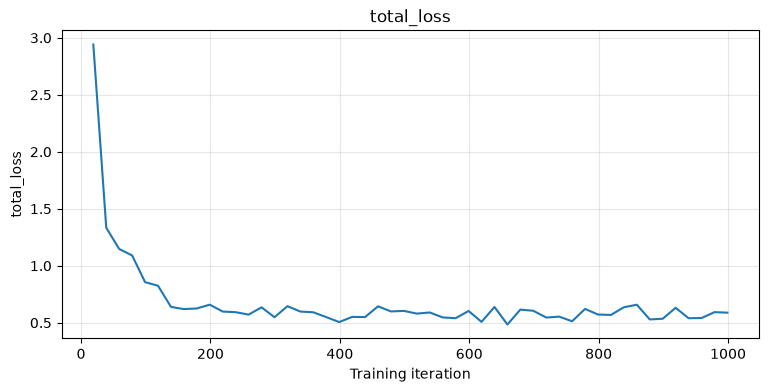

loss_cls start = 2.0728 end = 0.1636


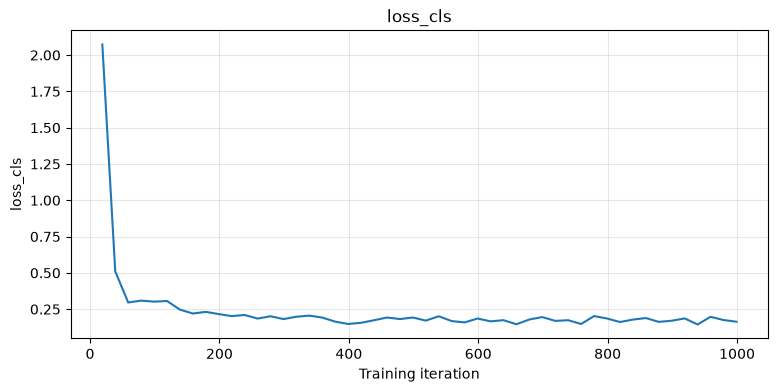

loss_box_reg start = 0.07 end = 0.2597


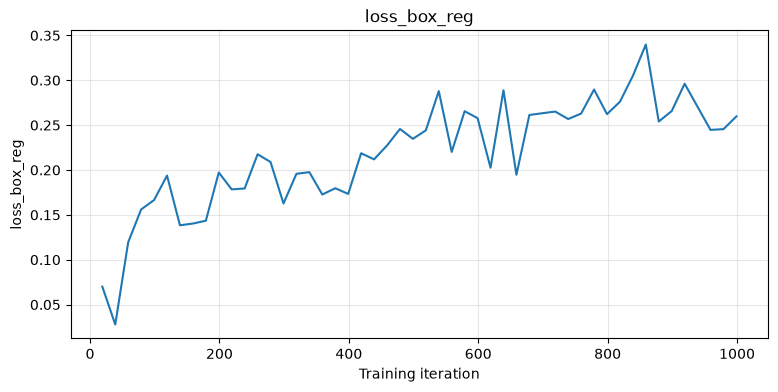

loss_rpn_cls start = 0.6922 end = 0.0759


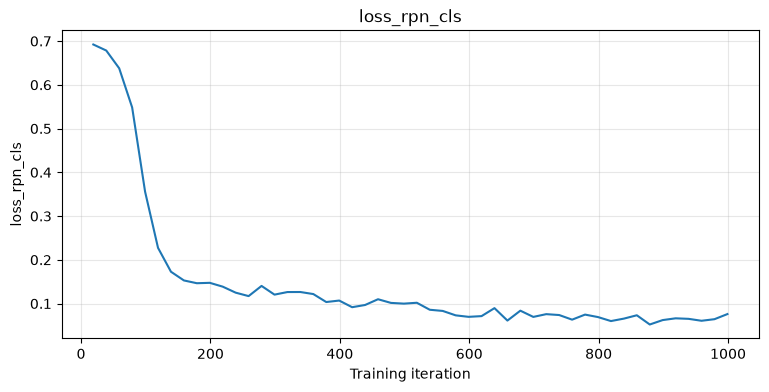

loss_rpn_loc start = 0.0672 end = 0.0582


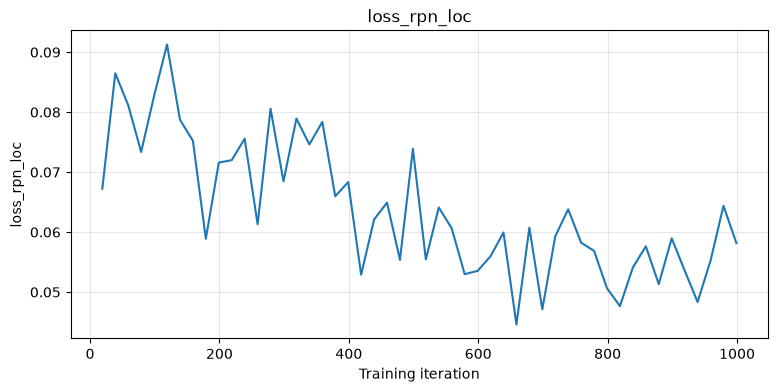

fast_rcnn/fg_cls_accuracy start = 0.0 end = 0.6873


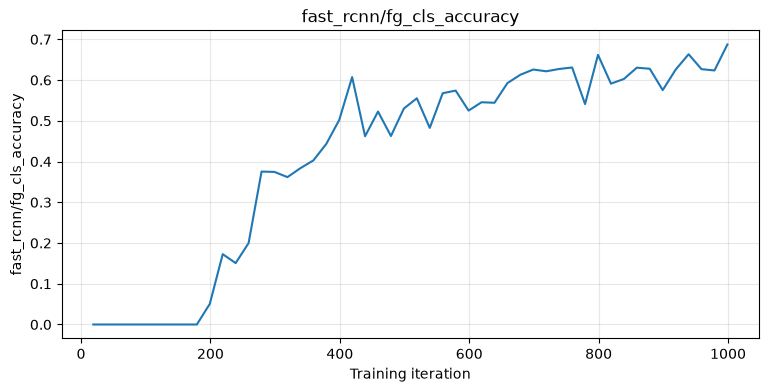

In [52]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

run = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

metrics_file = run / "metrics.json"

assert metrics_file.exists(), "Training metrics not found"

records = []

for line in metrics_file.read_text().splitlines():
    try:
        records.append(json.loads(line))
    except json.JSONDecodeError:
        pass

df = pd.DataFrame(records)

print("Metric records:", len(df))
print("Latest recorded iteration:", df["iteration"].max())

for metric in [
    "total_loss",
    "loss_cls",
    "loss_box_reg",
    "loss_rpn_cls",
    "loss_rpn_loc",
    "fast_rcnn/fg_cls_accuracy"
]:
    if metric in df.columns:
        values = df[["iteration", metric]].dropna()

        print(
            metric,
            "start =", round(values[metric].iloc[0], 4),
            "end =", round(values[metric].iloc[-1], 4)
        )

        plt.figure(figsize=(9, 4))
        plt.plot(values["iteration"], values[metric])
        plt.title(metric)
        plt.xlabel("Training iteration")
        plt.ylabel(metric)
        plt.grid(alpha=0.3)
        plt.show()


In [50]:

from pathlib import Path
import json
import statistics

run = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

metrics_file = run / "metrics.json"
assert metrics_file.exists()

records = [
    json.loads(line)
    for line in metrics_file.read_text().splitlines()
    if line.strip()
]

print("Metric records:", len(records))
print("Latest iteration:", max(r["iteration"] for r in records))

metrics = [
    "total_loss",
    "loss_cls",
    "loss_box_reg",
    "loss_rpn_cls",
    "loss_rpn_loc",
    "fast_rcnn/fg_cls_accuracy",
    "fast_rcnn/cls_accuracy"
]

for metric in metrics:
    values = [
        (r["iteration"], r[metric])
        for r in records
        if metric in r
    ]

    if not values:
        continue

    first = [v for i, v in values if i < 200]
    last = [v for i, v in values if i >= 800]

    print(f"\n{metric}")
    print("  First recorded:", round(values[0][1], 5))
    print("  Last recorded: ", round(values[-1][1], 5))

    if first and last:
        print("  Early mean:    ", round(statistics.mean(first), 5))
        print("  Late mean:     ", round(statistics.mean(last), 5))

print("\nSaved checkpoints:")
for path in sorted(run.glob("*.pth")):
    print(path.name)


Metric records: 51
Latest iteration: 1000

total_loss
  First recorded: 2.9415
  Last recorded:  0.58869
  Early mean:     1.07366
  Late mean:      0.58216

loss_cls
  First recorded: 2.07283
  Last recorded:  0.16358
  Early mean:     0.47106
  Late mean:      0.17287

loss_box_reg
  First recorded: 0.07
  Last recorded:  0.25972
  Early mean:     0.1353
  Late mean:      0.2757

loss_rpn_cls
  First recorded: 0.69218
  Last recorded:  0.07594
  Early mean:     0.37592
  Late mean:      0.06453

loss_rpn_loc
  First recorded: 0.06723
  Last recorded:  0.05816
  Early mean:     0.07667
  Late mean:      0.05494

fast_rcnn/fg_cls_accuracy
  First recorded: 0.0
  Last recorded:  0.68729
  Early mean:     0.00505
  Late mean:      0.62538

fast_rcnn/cls_accuracy
  First recorded: 0.89844
  Last recorded:  0.94238
  Early mean:     0.92612
  Late mean:      0.93711

Saved checkpoints:
model_0000499.pth
model_0000999.pth
model_final.pth


In [53]:

# ==========================================================
# EVALUATE SOURCE-ONLY PILOT ON FOGGY CITYSCAPES
# ==========================================================

import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

BASE = ROOT / "experiments/cityscapes_to_foggy"

PILOT = BASE / "source_only/pilot_1000_v1"

CONFIG = PILOT / "source_only_pilot_1000.yaml"
CHECKPOINT = PILOT / "model_final.pth"

EVAL_DIR = PILOT / "evaluation_foggy"
EVAL_DIR.mkdir(exist_ok=True)

assert CONFIG.exists(), "Pilot configuration missing"
assert CHECKPOINT.exists(), "Final checkpoint missing"

# Reuse the compatibility shim created during training
COMPAT = PILOT / "python_compat"

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONPATH"] = os.pathsep.join([
    str(COMPAT),
    str(REPO),
    env.get("PYTHONPATH", "")
])

command = [
    sys.executable,
    "-u",
    str(REPO / "train_net.py"),
    "--config-file",
    str(CONFIG),
    "--eval-only",
    "MODEL.WEIGHTS",
    str(CHECKPOINT),
    "OUTPUT_DIR",
    str(EVAL_DIR),
]

print("Evaluating checkpoint:", CHECKPOINT)
print("Validation dataset: cityscapes_foggy_val")
print("Evaluation output:", EVAL_DIR)

log_file = EVAL_DIR / "evaluation.log"

with log_file.open("w") as f:
    process = subprocess.Popen(
        command,
        cwd=str(ROOT),
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        f.write(line)
        f.flush()

        if any(s in line for s in [
            "Inference done",
            "Average Precision",
            "copypaste:",
            "Evaluation results",
            "Traceback",
            "Error",
        ]):
            print(line.rstrip(), flush=True)

    return_code = process.wait()

print("\nEvaluation return code:", return_code)

if return_code != 0:
    print("\n".join(log_file.read_text().splitlines()[-60:]))
    raise RuntimeError("Evaluation failed")

print("\nEVALUATION COMPLETED")


Evaluating checkpoint: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/model_final.pth
Validation dataset: cityscapes_foggy_val
Evaluation output: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/evaluation_foggy
[10/12 06:49:20 d2.evaluation.evaluator]: Inference done 11/1500. Dataloading: 0.3435 s/iter. Inference: 0.0407 s/iter. Eval: 0.0002 s/iter. Total: 0.3844 s/iter. ETA=0:09:32
[10/12 06:49:25 d2.evaluation.evaluator]: Inference done 23/1500. Dataloading: 0.3827 s/iter. Inference: 0.0407 s/iter. Eval: 0.0002 s/iter. Total: 0.4236 s/iter. ETA=0:10:25
[10/12 06:49:30 d2.evaluation.evaluator]: Inference done 37/1500. Dataloading: 0.3585 s/iter. Inference: 0.0424 s/iter. Eval: 0.0002 s/iter. Total: 0.4011 s/iter. ETA=0:09:46
[10/12 06:49:35 d2.evaluation.evaluator]: Inference done 52/1500. Dataloading: 0.3374 s/iter. Inference: 0.0419 s/iter. Eval: 0.0002 s/iter. Total: 0.3796 s/iter. ETA=0:09:09
[10/12 06:49:41 d2.evaluation.evaluator]: Infe

In [55]:
%pip install opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 185.9 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


Validation images: 1500
Class names: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']


/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Image 1: munster_000110_000019_leftImg8bit_foggy_beta_0.01.png | Predictions: 25


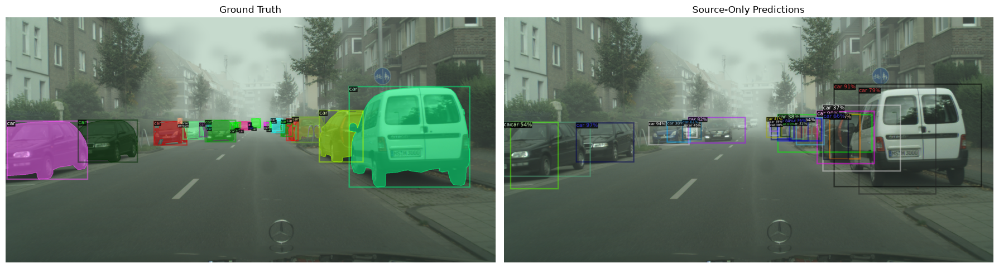

Image 2: frankfurt_000001_010600_leftImg8bit_foggy_beta_0.005.png | Predictions: 34


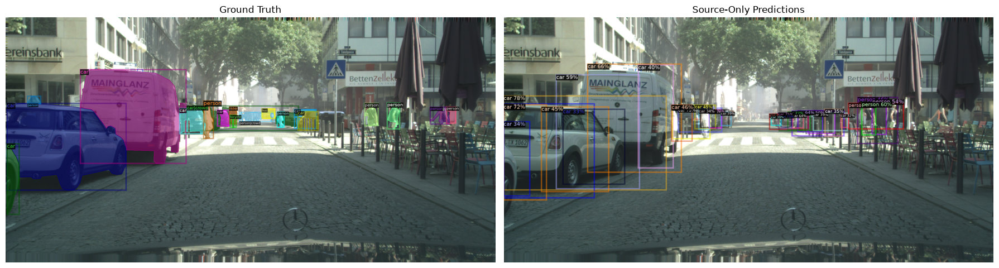

Image 3: frankfurt_000000_009291_leftImg8bit_foggy_beta_0.005.png | Predictions: 9


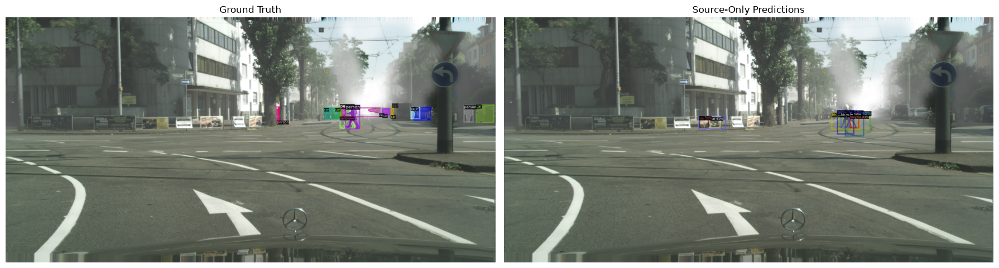

In [56]:

# ============================================================
# VISUALIZE SOURCE-ONLY DETECTION RESULTS
# ============================================================

import os
import sys
import random
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

PILOT = (
    ROOT / "experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

os.environ["DETECTRON2_DATASETS"] = str(ROOT / "datasets")

sys.path.insert(0, str(PILOT / "python_compat"))
sys.path.insert(0, str(REPO))

from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.utils.visualizer import Visualizer
from detectron2.utils.visualizer import ColorMode
from adapteacher import add_ateacher_config

# Load configuration
cfg = get_cfg()
add_ateacher_config(cfg)

cfg.merge_from_file(
    str(PILOT / "source_only_pilot_1000.yaml")
)

cfg.defrost()

cfg.MODEL.WEIGHTS = str(PILOT / "model_final.pth")
cfg.MODEL.DEVICE = "cuda"

# Show predictions with confidence >= 0.30
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.30

cfg.freeze()

# Ensure Cityscapes datasets are registered.
# Registration occurs through the repository's data package.
import adapteacher.data.datasets.builtin

dataset_name = "cityscapes_foggy_val"

dataset = DatasetCatalog.get(dataset_name)
metadata = MetadataCatalog.get(dataset_name)

print("Validation images:", len(dataset))
print("Class names:", metadata.thing_classes)

# Load model once
predictor = DefaultPredictor(cfg)

# Reproducible sample
random.seed(42)
samples = random.sample(dataset, 3)

for idx, sample in enumerate(samples, start=1):

    image = cv2.imread(sample["file_name"])

    assert image is not None, sample["file_name"]

    outputs = predictor(image)

    instances = outputs["instances"].to("cpu")

    print(
        f"Image {idx}:",
        Path(sample["file_name"]).name,
        "| Predictions:",
        len(instances)
    )

    # Ground truth visualization
    gt_visualizer = Visualizer(
        image[:, :, ::-1],
        metadata=metadata,
        scale=1.0
    )

    gt_result = gt_visualizer.draw_dataset_dict(sample)

    # Model prediction visualization
    pred_visualizer = Visualizer(
        image[:, :, ::-1],
        metadata=metadata,
        scale=1.0,
        instance_mode=ColorMode.IMAGE
    )

    pred_result = pred_visualizer.draw_instance_predictions(
        instances
    )

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    axes[0].imshow(gt_result.get_image())
    axes[0].set_title("Ground Truth")
    axes[0].axis("off")

    axes[1].imshow(pred_result.get_image())
    axes[1].set_title("Source-Only Predictions")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


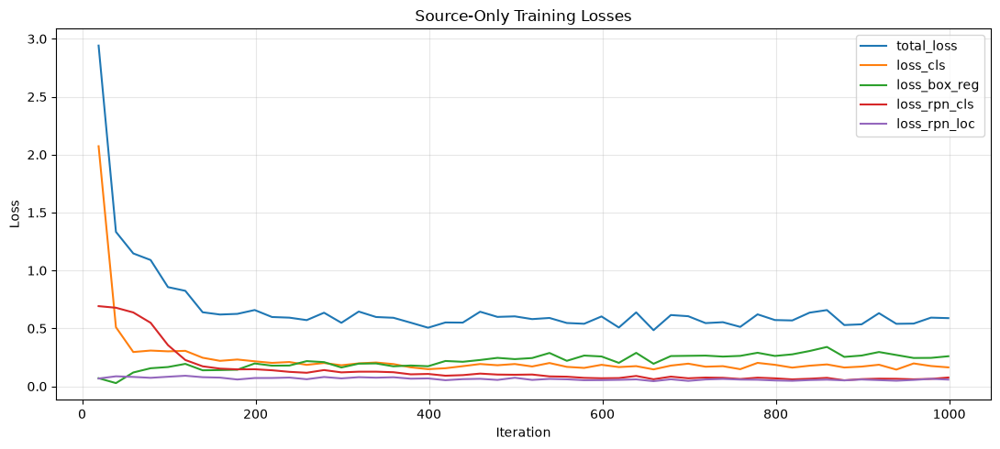

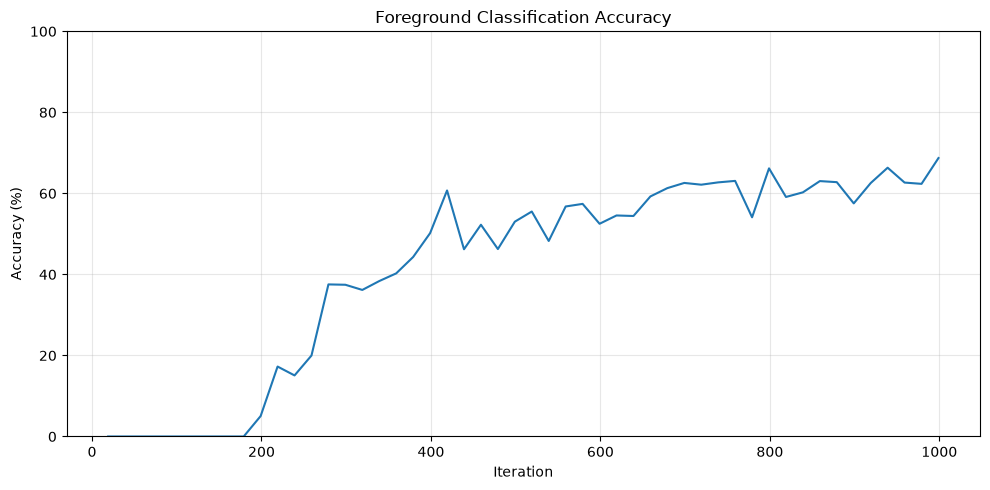

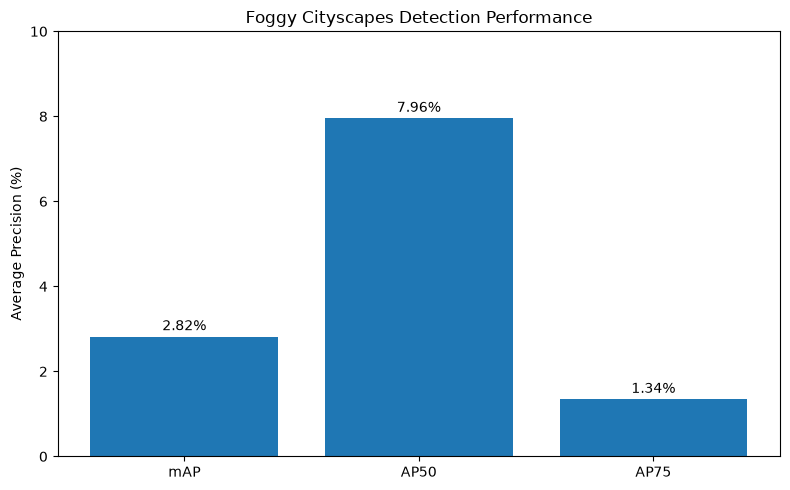

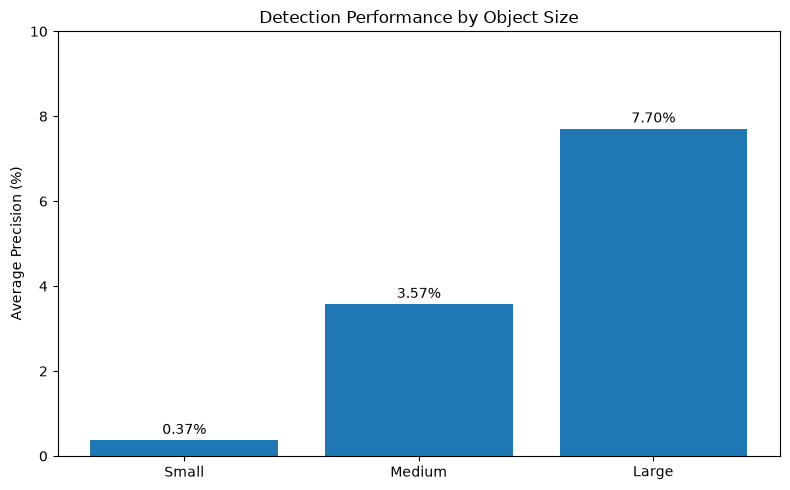

Charts saved to: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/charts


In [57]:

import json
from pathlib import Path
import matplotlib.pyplot as plt

RUN = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

OUT = RUN / "charts"
OUT.mkdir(parents=True, exist_ok=True)

with open(RUN / "metrics.json") as f:
    records = [json.loads(line) for line in f if line.strip()]

def series(metric):
    rows = [
        r for r in records
        if metric in r and "iteration" in r
    ]
    return (
        [r["iteration"] for r in rows],
        [r[metric] for r in rows]
    )

def save_chart(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

# Chart 1: Training losses
plt.figure(figsize=(11, 5))

for metric in [
    "total_loss",
    "loss_cls",
    "loss_box_reg",
    "loss_rpn_cls",
    "loss_rpn_loc"
]:
    x, y = series(metric)
    if x:
        plt.plot(x, y, label=metric)

plt.title("Source-Only Training Losses")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
save_chart("01_training_losses.png")

# Chart 2: Foreground classification accuracy
x, y = series("fast_rcnn/fg_cls_accuracy")

plt.figure(figsize=(10, 5))
plt.plot(x, [v * 100 for v in y])
plt.title("Foreground Classification Accuracy")
plt.xlabel("Iteration")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
save_chart("02_foreground_accuracy.png")

# Chart 3: Validation metrics
names = ["mAP", "AP50", "AP75"]
values = [2.8196, 7.9561, 1.3448]

plt.figure(figsize=(8, 5))
bars = plt.bar(names, values)
plt.title("Foggy Cityscapes Detection Performance")
plt.ylabel("Average Precision (%)")
plt.ylim(0, 10)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

save_chart("03_validation_metrics.png")

# Chart 4: AP by object size
sizes = ["Small", "Medium", "Large"]
ap_values = [0.3691, 3.5725, 7.7040]

plt.figure(figsize=(8, 5))
bars = plt.bar(sizes, ap_values)
plt.title("Detection Performance by Object Size")
plt.ylabel("Average Precision (%)")
plt.ylim(0, 10)

for bar, value in zip(bars, ap_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f}%",
        ha="center"
    )

save_chart("04_object_size_ap.png")

print("Charts saved to:", OUT)


FOG-DENSITY EVALUATION
Repository: /workspace/adaptive_teacher_recovered/adaptive_teacher
Checkpoint: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/model_final.pth
Output: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/fog_density_analysis
GPU: NVIDIA RTX PRO 4000 Blackwell
Dataset registration imported

Registered fog-related datasets:
  cityscapes_fine_instance_seg_train
  cityscapes_fine_sem_seg_train
  cityscapes_fine_instance_seg_val
  cityscapes_fine_sem_seg_val
  cityscapes_fine_instance_seg_test
  cityscapes_fine_sem_seg_test
  cityscapes_fine_panoptic_train
  cityscapes_fine_panoptic_val
  cityscapes_foggy_train
  cityscapes_foggy_val
  cityscapes_foggy_test

Base dataset: cityscapes_foggy_val
Number of records: 1500
Class names: ['person', 'rider', 'car', 'truck', 'bus', 'train', 'motorcycle', 'bicycle']

Sample image paths:
  datasets/cityscapes_foggy/leftImg8bit/val/frankfurt/frankfurt_000000_000294_leftImg8bit_foggy_beta_0.005.p

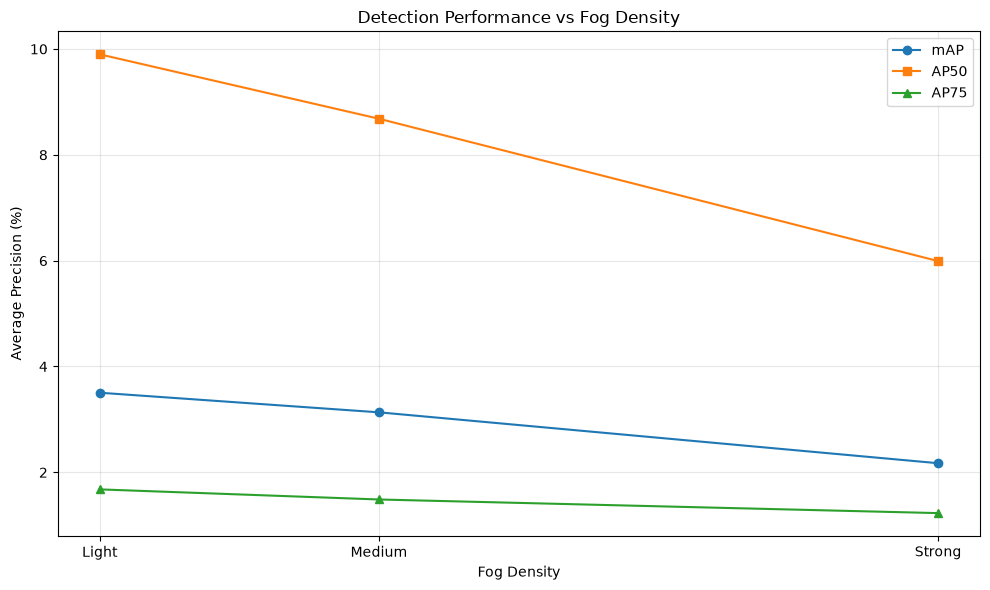

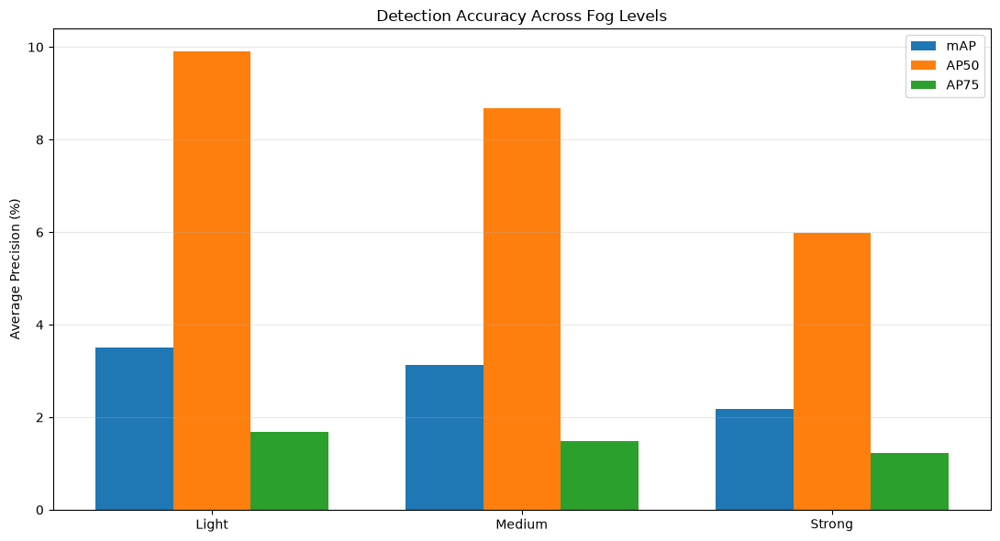

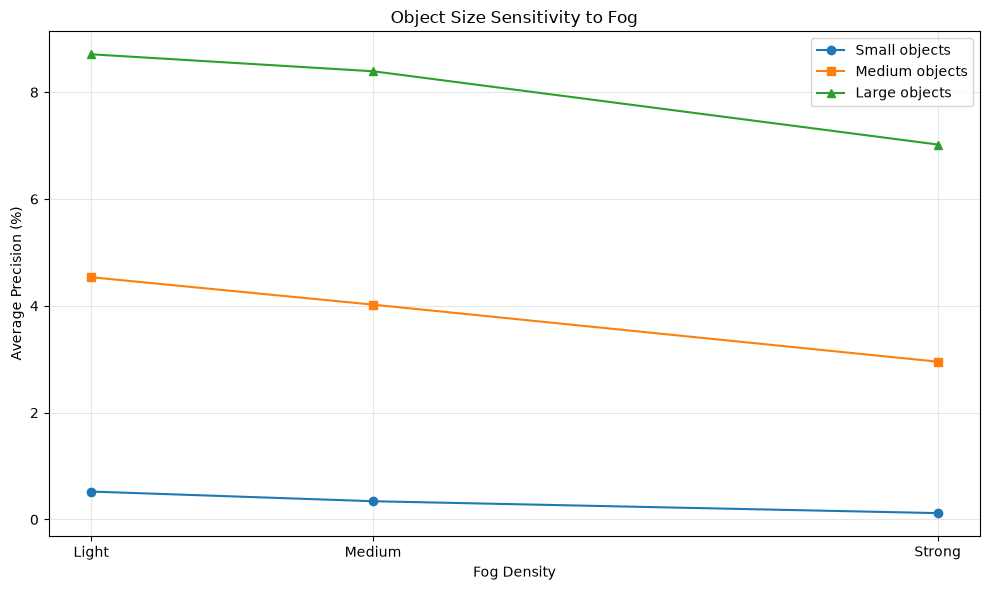

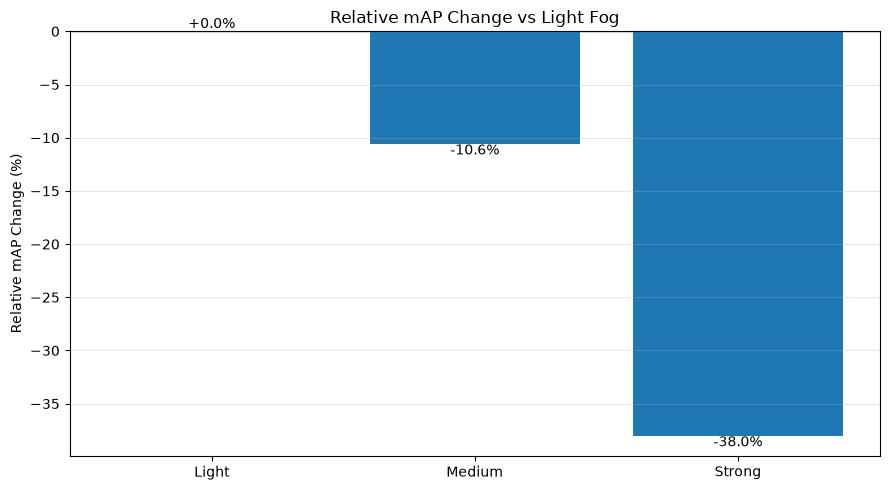

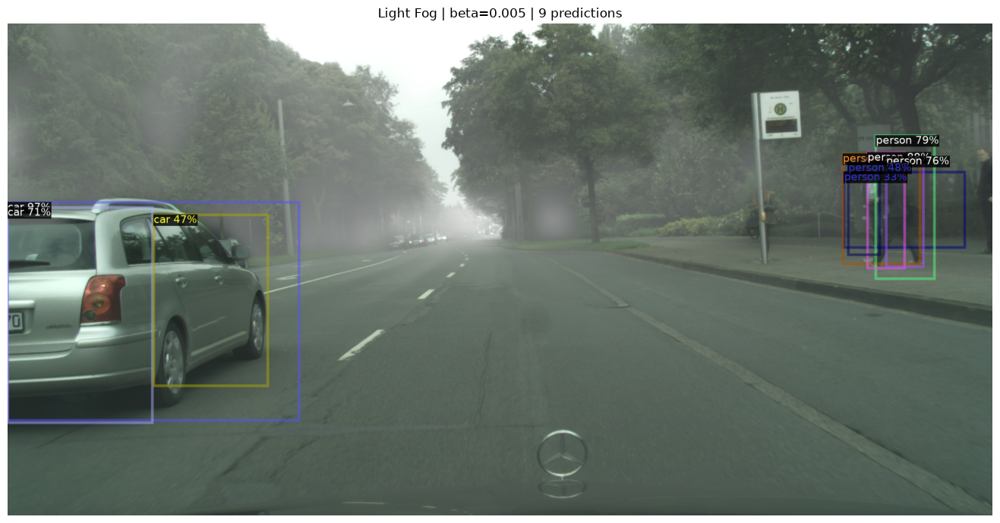

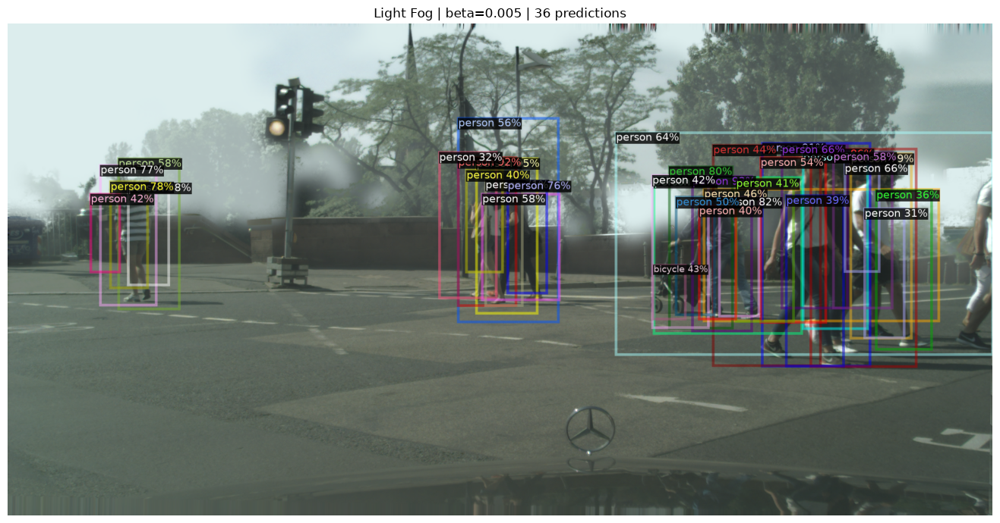

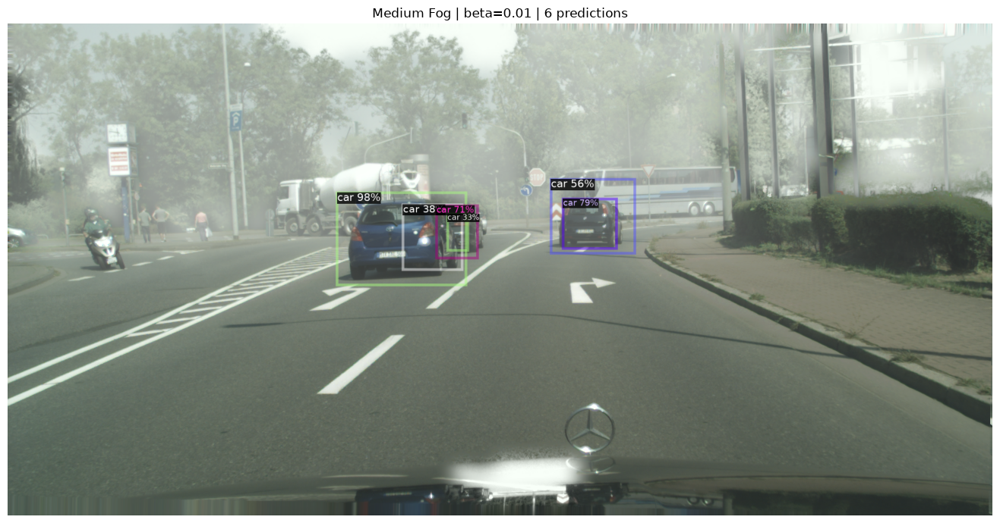

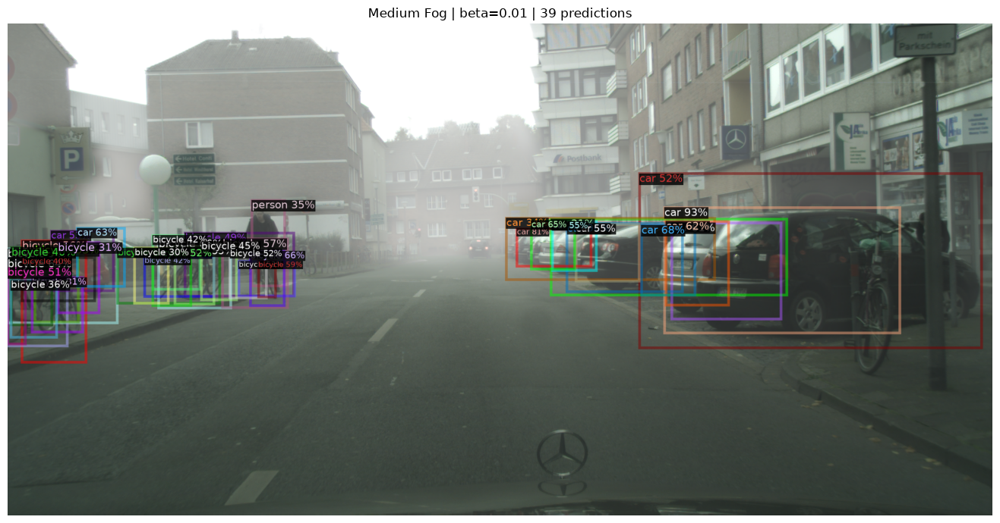

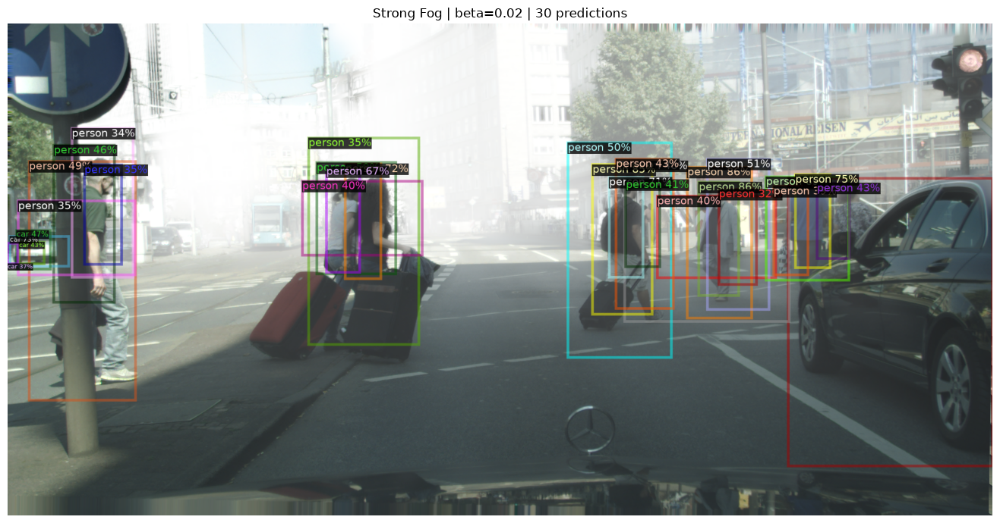

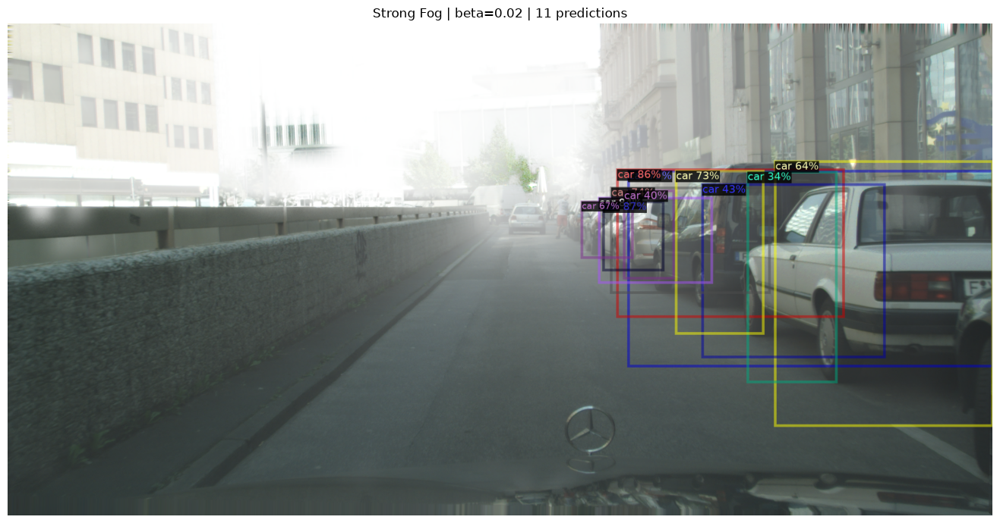


EXPERIMENT COMPLETED
Model: Source-only
Training iterations: 1000
Source domain: Cityscapes
Target domain: Foggy Cityscapes

Evaluation summary:
light    beta=0.005 mAP=3.505 AP50=9.900
medium   beta=0.010 mAP=3.134 AP50=8.682
strong   beta=0.020 mAP=2.172 AP50=5.992

All outputs: /workspace/experiments/cityscapes_to_foggy/source_only/pilot_1000_v1/fog_density_analysis
No retraining was performed.


In [58]:

# ================================================================
# PHD EXPERIMENT 03
# SOURCE-ONLY MODEL: FOG-DENSITY EVALUATION
#
# Cityscapes -> Foggy Cityscapes
#
# Performs:
# 1. Environment and checkpoint validation
# 2. Dataset-registration inspection
# 3. Identify light / medium / strong fog images
# 4. Register three separate validation subsets
# 5. Evaluate AP, AP50, AP75, APs, APm, APl
# 6. Save results to CSV and JSON
# 7. Plot fog-density performance
# 8. Plot performance degradation relative to light fog
# 9. Visualize predictions at each fog level
#
# No retraining. Uses model_final.pth.
# ================================================================

import os
import sys
import json
import csv
import copy
import random
import traceback
import importlib
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

ROOT = Path("/workspace")

REPO = (
    ROOT /
    "adaptive_teacher_recovered/adaptive_teacher"
)

PILOT = (
    ROOT /
    "experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

CONFIG_FILE = PILOT / "source_only_pilot_1000.yaml"
CHECKPOINT = PILOT / "model_final.pth"

DATASET_ROOT = ROOT / "datasets"
FOGGY_ROOT = DATASET_ROOT / "cityscapes_foggy"

OUTPUT = PILOT / "fog_density_analysis"

OUTPUT.mkdir(parents=True, exist_ok=True)

assert REPO.exists(), f"Repository missing: {REPO}"
assert CONFIG_FILE.exists(), f"Config missing: {CONFIG_FILE}"
assert CHECKPOINT.exists(), f"Checkpoint missing: {CHECKPOINT}"
assert FOGGY_ROOT.exists(), f"Foggy dataset missing: {FOGGY_ROOT}"

os.environ["DETECTRON2_DATASETS"] = str(DATASET_ROOT)

sys.path.insert(0, str(REPO))
sys.path.insert(0, str(PILOT / "python_compat"))

print("=" * 65)
print("FOG-DENSITY EVALUATION")
print("=" * 65)
print("Repository:", REPO)
print("Checkpoint:", CHECKPOINT)
print("Output:", OUTPUT)
print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

# ------------------------------------------------
# 2. IMPORT DETECTRON2 AND ADAPTIVE TEACHER
# ------------------------------------------------

from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data import build_detection_test_loader
from detectron2.engine import DefaultPredictor
from detectron2.evaluation import (
    COCOEvaluator,
    inference_on_dataset,
)
from detectron2.utils.visualizer import Visualizer
from detectron2.checkpoint import DetectionCheckpointer

from adapteacher import add_ateacher_config

# Import project-specific dataset registrations
try:
    import adapteacher.data.datasets.builtin
    print("Dataset registration imported")
except Exception as exc:
    print("Registration import warning:", exc)

# ------------------------------------------------
# 3. DISCOVER REGISTERED DATASETS
# ------------------------------------------------

registered = DatasetCatalog.list()

print("\nRegistered fog-related datasets:")
for name in registered:
    if "fog" in name.lower() or "cityscape" in name.lower():
        print(" ", name)

BASE_DATASET = "cityscapes_foggy_val"

if BASE_DATASET not in registered:
    raise RuntimeError(
        f"{BASE_DATASET} is not registered.\n"
        "Use the registration mechanism from the successful "
        "1500-image evaluation before continuing."
    )

base_records = DatasetCatalog.get(BASE_DATASET)
base_metadata = MetadataCatalog.get(BASE_DATASET)

print("\nBase dataset:", BASE_DATASET)
print("Number of records:", len(base_records))
print("Class names:",
      getattr(base_metadata, "thing_classes", None))

# ------------------------------------------------
# 4. INSPECT FILE NAMING CONVENTIONS
# ------------------------------------------------

print("\nSample image paths:")

for item in base_records[:9]:
    print(" ", item["file_name"])

print("\nFoggy directory structure:")

for path in sorted(FOGGY_ROOT.iterdir()):
    print(" ", path.name)

# ------------------------------------------------
# 5. IDENTIFY FOG LEVEL FROM FILE NAME
# ------------------------------------------------
#
# Foggy Cityscapes convention:
#
# beta_0.005 = light fog
# beta_0.01  = medium fog
# beta_0.02  = strong fog
#
# Supports several common representations.
# It deliberately rejects unrecognized names
# instead of silently assigning incorrect labels.
# ------------------------------------------------

FOG_LEVELS = {
    "light": {
        "beta": 0.005,
        "tokens": [
            "beta_0.005",
            "beta_0.0050",
        ],
    },
    "medium": {
        "beta": 0.010,
        "tokens": [
            "beta_0.01",
            "beta_0.010",
        ],
    },
    "strong": {
        "beta": 0.020,
        "tokens": [
            "beta_0.02",
            "beta_0.020",
        ],
    },
}

def detect_fog_level(path):

    name = str(path).lower()

    for level, info in FOG_LEVELS.items():

        for token in info["tokens"]:

            if token in name:
                return level

    return None


subsets = {
    "light": [],
    "medium": [],
    "strong": [],
}

unknown = []

for record in base_records:

    level = detect_fog_level(record["file_name"])

    if level is None:
        unknown.append(record["file_name"])
    else:
        subsets[level].append(record)

print("\nFog density distribution:")

for level, items in subsets.items():
    print(
        f"{level:8s} | "
        f"beta={FOG_LEVELS[level]['beta']:.3f} | "
        f"{len(items)} images"
    )

print("Unknown fog levels:", len(unknown))

if unknown:
    print("\nFirst unmatched paths:")
    for path in unknown[:10]:
        print(path)

# Safety check: do not run misleading evaluations
if unknown:
    raise RuntimeError(
        "Some images could not be assigned to a fog level. "
        "Inspect the printed paths and update detect_fog_level()."
    )

if sum(map(len, subsets.values())) != len(base_records):
    raise RuntimeError("Fog-level partition is incomplete.")

for level, items in subsets.items():
    if len(items) == 0:
        raise RuntimeError(
            f"No images identified for {level} fog."
        )

# Standard validation split should have 500 per level.
for level, items in subsets.items():
    if len(items) != 500:
        print(
            f"WARNING: {level} contains {len(items)} images, "
            "not the expected 500."
        )

# ------------------------------------------------
# 6. REGISTER INDIVIDUAL FOG-DENSITY DATASETS
# ------------------------------------------------

dataset_names = {}

for level, items in subsets.items():

    name = f"cityscapes_foggy_{level}_val_pilot"

    dataset_names[level] = name

    if name not in DatasetCatalog.list():

        # Bind current subset explicitly
        def make_loader(records=items):
            return copy.deepcopy(records)

        DatasetCatalog.register(name, make_loader)

    # Copy metadata from the existing base dataset
    source_metadata = base_metadata.as_dict()

    source_metadata.pop("name", None)

    # COCOEvaluator will convert annotations to COCO
    # if no pre-existing COCO JSON is provided.
    source_metadata.pop("json_file", None)

    # Prevent dataset-specific evaluator configuration
    # from interfering with explicit COCOEvaluator.
    source_metadata.pop("evaluator_type", None)

    MetadataCatalog.get(name).set(
        **source_metadata
    )

    print(
        f"Registered: {name} "
        f"({len(items)} images)"
    )

# ------------------------------------------------
# 7. LOAD CONFIGURATION
# ------------------------------------------------

cfg = get_cfg()
add_ateacher_config(cfg)

cfg.merge_from_file(str(CONFIG_FILE))

cfg.defrost()

cfg.MODEL.WEIGHTS = str(CHECKPOINT)
cfg.MODEL.DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

cfg.DATALOADER.NUM_WORKERS = 0
cfg.TEST.EVAL_PERIOD = 0

# Do not modify model architecture or weights.
cfg.freeze()

print("\nModel configuration loaded.")

# ------------------------------------------------
# 8. LOAD TRAINED MODEL
# ------------------------------------------------
#
# Use the repository's model-building logic so
# that the loaded architecture matches training.
# ------------------------------------------------

from adapteacher.modeling.meta_arch.rcnn import (
    DAobjTwoStagePseudoLabGeneralizedRCNN,
)

# Detectron2 build_model respects the registered
# META_ARCHITECTURE from the saved configuration.
from detectron2.modeling import build_model

model = build_model(cfg)

DetectionCheckpointer(model).load(
    str(CHECKPOINT)
)

model.eval()

print("Model checkpoint loaded successfully.")

# ------------------------------------------------
# 9. EVALUATE EACH FOG LEVEL
# ------------------------------------------------

results = []

for level in ["light", "medium", "strong"]:

    name = dataset_names[level]

    level_output = OUTPUT / level
    level_output.mkdir(exist_ok=True)

    print("\n" + "=" * 65)
    print("EVALUATING:", level.upper())
    print("Beta:", FOG_LEVELS[level]["beta"])
    print("Images:", len(subsets[level]))
    print("=" * 65)

    evaluator = COCOEvaluator(
        name,
        output_dir=str(level_output)
    )

    loader = build_detection_test_loader(
        cfg,
        name
    )

    evaluation = inference_on_dataset(
        model,
        loader,
        evaluator
    )

    print("\nEvaluation result:")
    print(evaluation)

    bbox = evaluation.get("bbox", {})

    result = {
        "fog_level": level,
        "beta": FOG_LEVELS[level]["beta"],
        "images": len(subsets[level]),
        "AP": bbox.get("AP", float("nan")),
        "AP50": bbox.get("AP50", float("nan")),
        "AP75": bbox.get("AP75", float("nan")),
        "APs": bbox.get("APs", float("nan")),
        "APm": bbox.get("APm", float("nan")),
        "APl": bbox.get("APl", float("nan")),
    }

    results.append(result)

# ------------------------------------------------
# 10. SAVE METRICS
# ------------------------------------------------

json_file = OUTPUT / "fog_density_results.json"
csv_file = OUTPUT / "fog_density_results.csv"

json_file.write_text(
    json.dumps(results, indent=2)
)

with csv_file.open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(results[0].keys())
    )

    writer.writeheader()
    writer.writerows(results)

print("\nResults saved:")
print(json_file)
print(csv_file)

# ------------------------------------------------
# 11. PRINT COMPARISON TABLE
# ------------------------------------------------

print("\n" + "=" * 78)
print("FOG-DENSITY COMPARISON")
print("=" * 78)

print(
    f"{'Fog Level':<12}"
    f"{'Beta':<10}"
    f"{'Images':<10}"
    f"{'mAP':<12}"
    f"{'AP50':<12}"
    f"{'AP75':<12}"
)

for row in results:

    print(
        f"{row['fog_level']:<12}"
        f"{row['beta']:<10.3f}"
        f"{row['images']:<10}"
        f"{row['AP']:<12.3f}"
        f"{row['AP50']:<12.3f}"
        f"{row['AP75']:<12.3f}"
    )

# ------------------------------------------------
# 12. CHART 1: mAP VS FOG DENSITY
# ------------------------------------------------

levels = [r["fog_level"].capitalize() for r in results]
betas = [r["beta"] for r in results]

ap = [r["AP"] for r in results]
ap50 = [r["AP50"] for r in results]
ap75 = [r["AP75"] for r in results]

plt.figure(figsize=(10, 6))

plt.plot(betas, ap, marker="o", label="mAP")
plt.plot(betas, ap50, marker="s", label="AP50")
plt.plot(betas, ap75, marker="^", label="AP75")

plt.xticks(betas, levels)

plt.title("Detection Performance vs Fog Density")
plt.xlabel("Fog Density")
plt.ylabel("Average Precision (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT / "01_map_vs_fog_density.png",
    dpi=200
)
plt.show()

# ------------------------------------------------
# 13. CHART 2: GROUPED AP COMPARISON
# ------------------------------------------------

x = np.arange(len(levels))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(x - width, ap, width, label="mAP")
plt.bar(x, ap50, width, label="AP50")
plt.bar(x + width, ap75, width, label="AP75")

plt.xticks(x, levels)
plt.ylabel("Average Precision (%)")
plt.title("Detection Accuracy Across Fog Levels")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT / "02_grouped_ap_comparison.png",
    dpi=200
)
plt.show()

# ------------------------------------------------
# 14. CHART 3: AP BY OBJECT SIZE
# ------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    betas,
    [r["APs"] for r in results],
    marker="o",
    label="Small objects"
)

plt.plot(
    betas,
    [r["APm"] for r in results],
    marker="s",
    label="Medium objects"
)

plt.plot(
    betas,
    [r["APl"] for r in results],
    marker="^",
    label="Large objects"
)

plt.xticks(betas, levels)

plt.title("Object Size Sensitivity to Fog")
plt.xlabel("Fog Density")
plt.ylabel("Average Precision (%)")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT / "03_object_size_vs_fog.png",
    dpi=200
)
plt.show()

# ------------------------------------------------
# 15. CHART 4: RELATIVE CHANGE FROM LIGHT FOG
# ------------------------------------------------

baseline_ap = results[0]["AP"]

if baseline_ap > 0:

    relative_change = [
        (r["AP"] - baseline_ap) / baseline_ap * 100
        for r in results
    ]

    plt.figure(figsize=(9, 5))

    bars = plt.bar(levels, relative_change)

    plt.axhline(0, linewidth=1)

    plt.title("Relative mAP Change vs Light Fog")
    plt.ylabel("Relative mAP Change (%)")
    plt.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, relative_change):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:+.1f}%",
            ha="center",
            va="bottom" if value >= 0 else "top"
        )

    plt.tight_layout()
    plt.savefig(
        OUTPUT / "04_relative_map_change.png",
        dpi=200
    )
    plt.show()

else:
    print(
        "Skipping relative change chart: "
        "light-fog AP is zero."
    )

# ------------------------------------------------
# 16. VISUALIZE PREDICTIONS
# ------------------------------------------------
#
# Use the same trained model for each fog level.
# Visualizations are qualitative and are not
# substitutes for COCO AP evaluation.
# ------------------------------------------------

try:
    import cv2

    vis_cfg = cfg.clone()
    vis_cfg.defrost()
    vis_cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.30
    vis_cfg.freeze()

    predictor = DefaultPredictor(vis_cfg)

    random.seed(42)

    for level in ["light", "medium", "strong"]:

        samples = random.sample(
            subsets[level],
            min(2, len(subsets[level]))
        )

        for index, sample in enumerate(samples, 1):

            image = cv2.imread(sample["file_name"])

            if image is None:
                print(
                    "Could not read:",
                    sample["file_name"]
                )
                continue

            prediction = predictor(image)

            instances = prediction["instances"].to("cpu")

            visualizer = Visualizer(
                image[:, :, ::-1],
                metadata=MetadataCatalog.get(
                    dataset_names[level]
                ),
                scale=1.0
            )

            rendered = (
                visualizer
                .draw_instance_predictions(instances)
                .get_image()
            )

            plt.figure(figsize=(15, 7))
            plt.imshow(rendered)
            plt.axis("off")

            plt.title(
                f"{level.capitalize()} Fog | "
                f"beta={FOG_LEVELS[level]['beta']} | "
                f"{len(instances)} predictions"
            )

            plt.tight_layout()

            plt.savefig(
                OUTPUT /
                f"prediction_{level}_{index}.png",
                dpi=180,
                bbox_inches="tight"
            )

            plt.show()

except ImportError:
    print(
        "OpenCV not installed. "
        "Skipping image visualizations."
    )

# ------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT COMPLETED")
print("=" * 65)

print("Model: Source-only")
print("Training iterations: 1000")
print("Source domain: Cityscapes")
print("Target domain: Foggy Cityscapes")

print("\nEvaluation summary:")

for r in results:
    print(
        f"{r['fog_level']:8s} "
        f"beta={r['beta']:.3f} "
        f"mAP={r['AP']:.3f} "
        f"AP50={r['AP50']:.3f}"
    )

print("\nAll outputs:", OUTPUT)
print("No retraining was performed.")


In [60]:

# ================================================================
# 8. PREPARE RESUME CHECKPOINT - RUNPOD PERMISSION FIX
# ================================================================

import shutil
from pathlib import Path

RESUME_CHECKPOINT = RUN / "model_resume_from_1000.pth"
LAST_CHECKPOINT = RUN / "last_checkpoint"

RUN.mkdir(parents=True, exist_ok=True)

# If a previous continuation has already started,
# preserve its latest checkpoint.
if LAST_CHECKPOINT.exists():

    existing_name = LAST_CHECKPOINT.read_text().strip()
    existing_path = RUN / existing_name

    if not existing_path.is_file():
        raise RuntimeError(
            f"Existing checkpoint is missing: {existing_path}"
        )

    print("Existing resume checkpoint:", existing_path)

else:

    # copyfile copies file contents only.
    # It does not try to preserve timestamps or permissions.
    if not RESUME_CHECKPOINT.exists():
        shutil.copyfile(
            PILOT_CHECKPOINT,
            RESUME_CHECKPOINT
        )

    # Verify the copied file size.
    original_size = PILOT_CHECKPOINT.stat().st_size
    copied_size = RESUME_CHECKPOINT.stat().st_size

    if original_size != copied_size:
        raise RuntimeError(
            "Checkpoint copy size mismatch."
        )

    LAST_CHECKPOINT.write_text(
        RESUME_CHECKPOINT.name
    )

    print("Resume checkpoint prepared successfully.")

print("Checkpoint:", LAST_CHECKPOINT.read_text().strip())
print(
    "Checkpoint size:",
    round(
        (RUN / LAST_CHECKPOINT.read_text().strip())
        .stat().st_size / 1024**2,
        2
    ),
    "MB"
)


Resume checkpoint prepared successfully.
Checkpoint: model_resume_from_1000.pth
Checkpoint size: 347.44 MB


In [61]:

# ============================================================
# START SOURCE-ONLY TRAINING: 1000 -> 5000 ITERATIONS
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/workspace")
REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
PILOT = ROOT / "experiments/cityscapes_to_foggy/source_only/pilot_1000_v1"
RUN = ROOT / "experiments/cityscapes_to_foggy/source_only/continuation_5000_v1"

CONFIG = RUN / "source_only_5000.yaml"
LAST_CHECKPOINT = RUN / "last_checkpoint"

assert CONFIG.exists(), f"Missing configuration: {CONFIG}"
assert LAST_CHECKPOINT.exists(), "Missing resume checkpoint pointer"

checkpoint_name = LAST_CHECKPOINT.read_text().strip()
assert (RUN / checkpoint_name).is_file(), "Resume checkpoint missing"

env = os.environ.copy()
env["DETECTRON2_DATASETS"] = str(ROOT / "datasets")
env["PYTHONUNBUFFERED"] = "1"
env["PYTHONPATH"] = os.pathsep.join([
    str(PILOT / "python_compat"),
    str(REPO),
    env.get("PYTHONPATH", "")
])

command = [
    sys.executable,
    "-u",
    str(REPO / "train_net.py"),
    "--config-file",
    str(CONFIG),
    "--resume"
]

print("=" * 65)
print("STARTING SOURCE-ONLY TRAINING")
print("=" * 65)
print("Resume checkpoint:", checkpoint_name)
print("Target: 5000 iterations")
print("Output:", RUN)
print("=" * 65, flush=True)

log_path = RUN / "training_console.log"

with log_path.open("a") as log:
    process = subprocess.Popen(
        command,
        cwd=str(ROOT),
        env=env,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()

    return_code = process.wait()

print("\nTraining return code:", return_code)
print("Training log:", log_path)

if return_code != 0:
    raise RuntimeError("Training failed. Check the log above.")


STARTING SOURCE-ONLY TRAINING
Resume checkpoint: model_resume_from_1000.pth
Target: 5000 iterations
Output: /workspace/experiments/cityscapes_to_foggy/source_only/continuation_5000_v1
Command Line Args: Namespace(config_file='/workspace/experiments/cityscapes_to_foggy/source_only/continuation_5000_v1/source_only_5000.yaml', resume=True, eval_only=False, num_gpus=1, num_machines=1, machine_rank=0, dist_url='tcp://127.0.0.1:49152', opts=[])
[10/12 07:34:40 detectron2]: Rank of current process: 0. World size: 1
[10/12 07:34:41 detectron2]: Environment info:
-------------------------------  -----------------------------------------------------------------
sys.platform                     linux
Python                           3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]
numpy                            2.1.2
detectron2                       0.6 @/usr/local/lib/python3.12/dist-packages/detectron2
Compiler                         GCC 13.3
CUDA compiler                    CUDA 12.8
detec

SOURCE-ONLY MODEL VISUALIZATION
Checkpoint: /workspace/experiments/cityscapes_to_foggy/source_only/continuation_5000_v1/model_final.pth
Output: /workspace/experiments/cityscapes_to_foggy/source_only/continuation_5000_v1/visualization_and_fog_analysis
GPU: NVIDIA RTX PRO 4000 Blackwell

Model loaded successfully.
Architecture: DAobjTwoStagePseudoLabGeneralizedRCNN
Classes: 8

Training metric records: 252
First logged iteration: 19
Last logged iteration: 5000


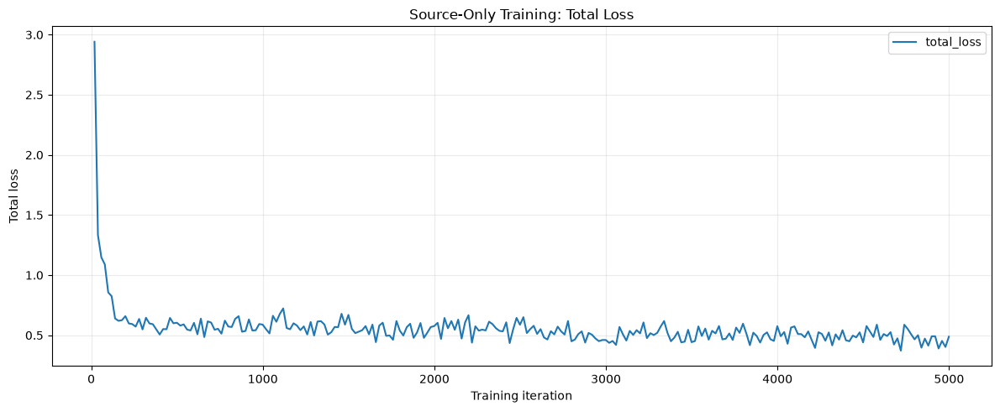

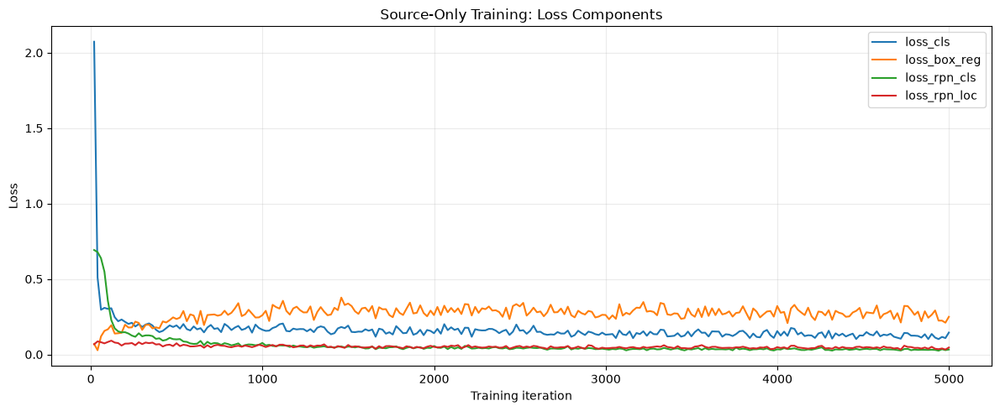

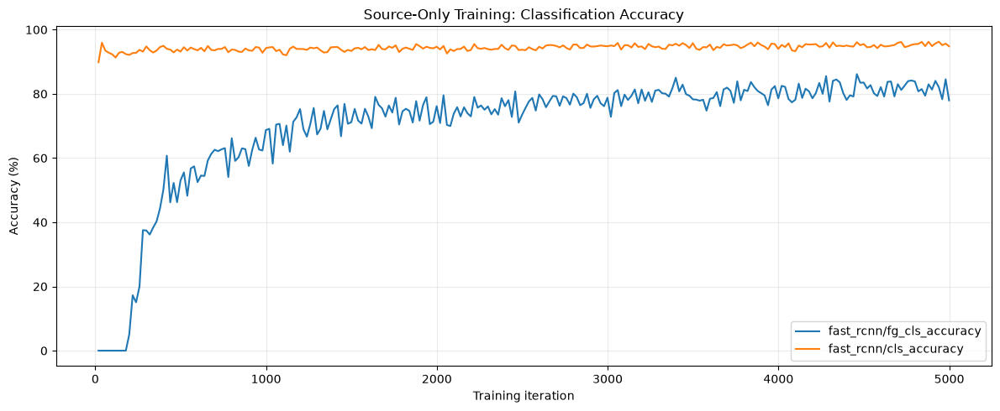

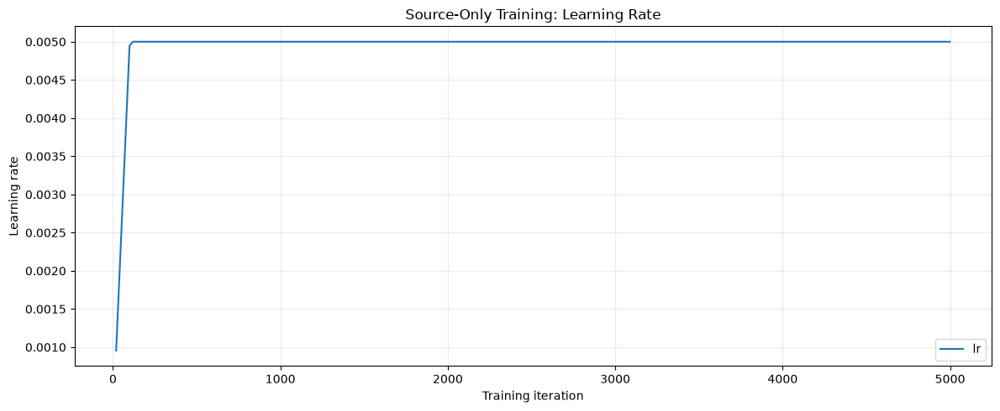

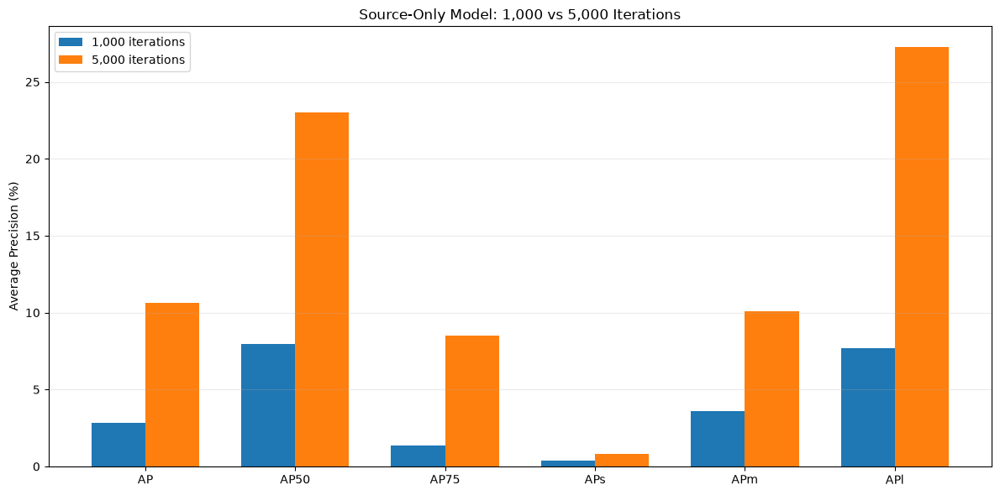


Foggy validation records: 1500
light | 500 images
medium | 500 images
strong | 500 images

EVALUATING LIGHT FOG (beta=0.005)
Loading and preparing results...
DONE (t=0.40s)
creating index...
index created!
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.133
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.283
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.109
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.011
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.130
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.312
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.200
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.214
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] =

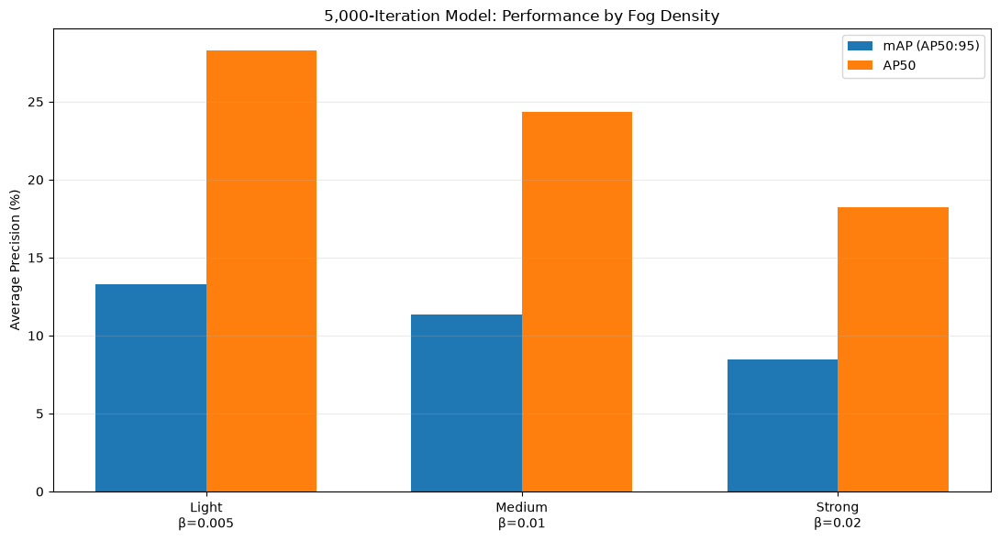

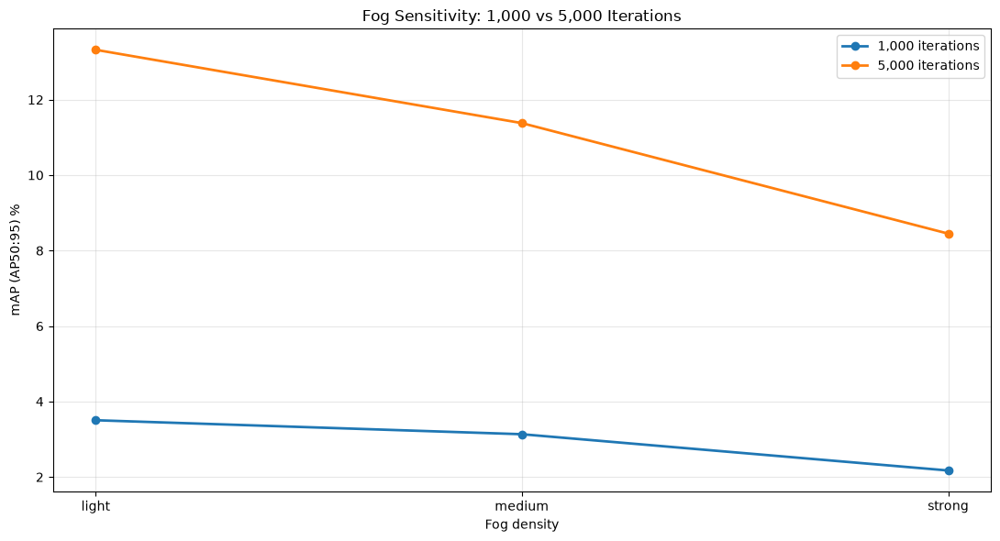

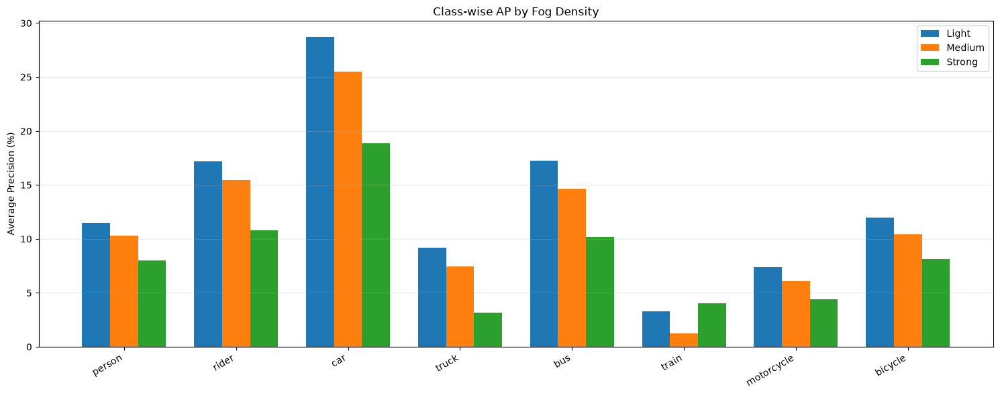

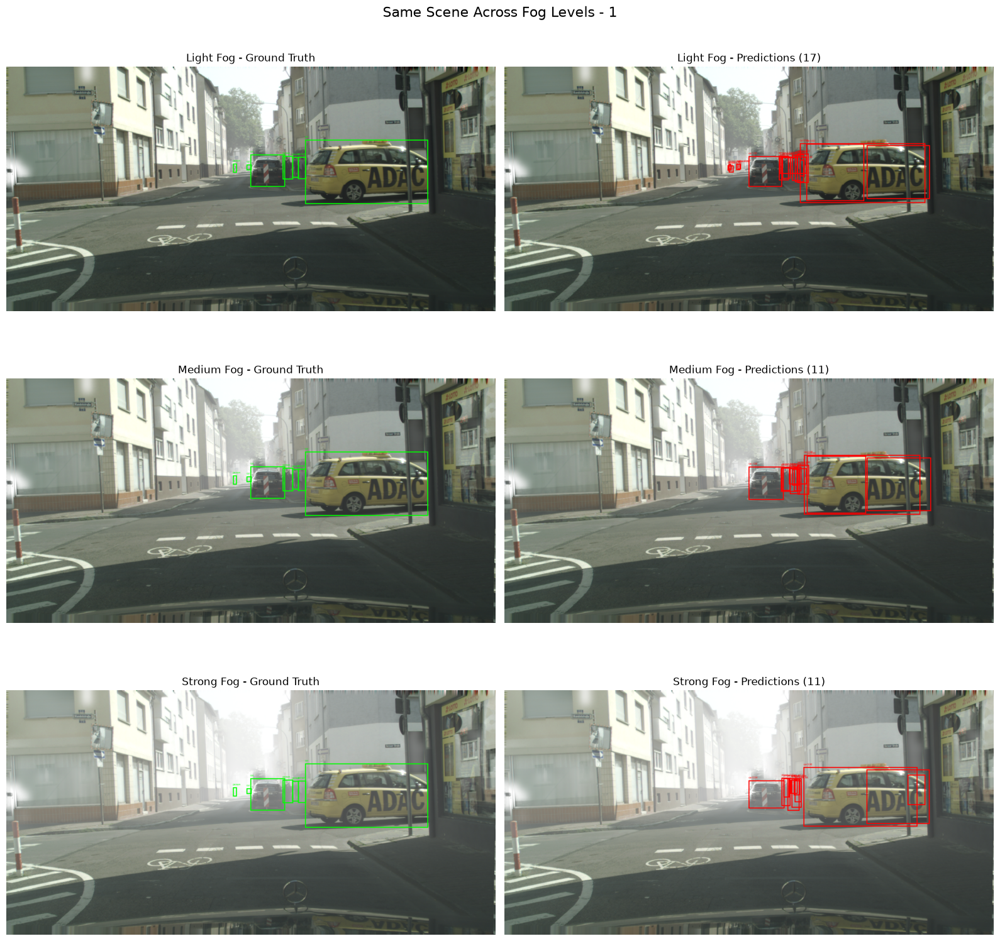

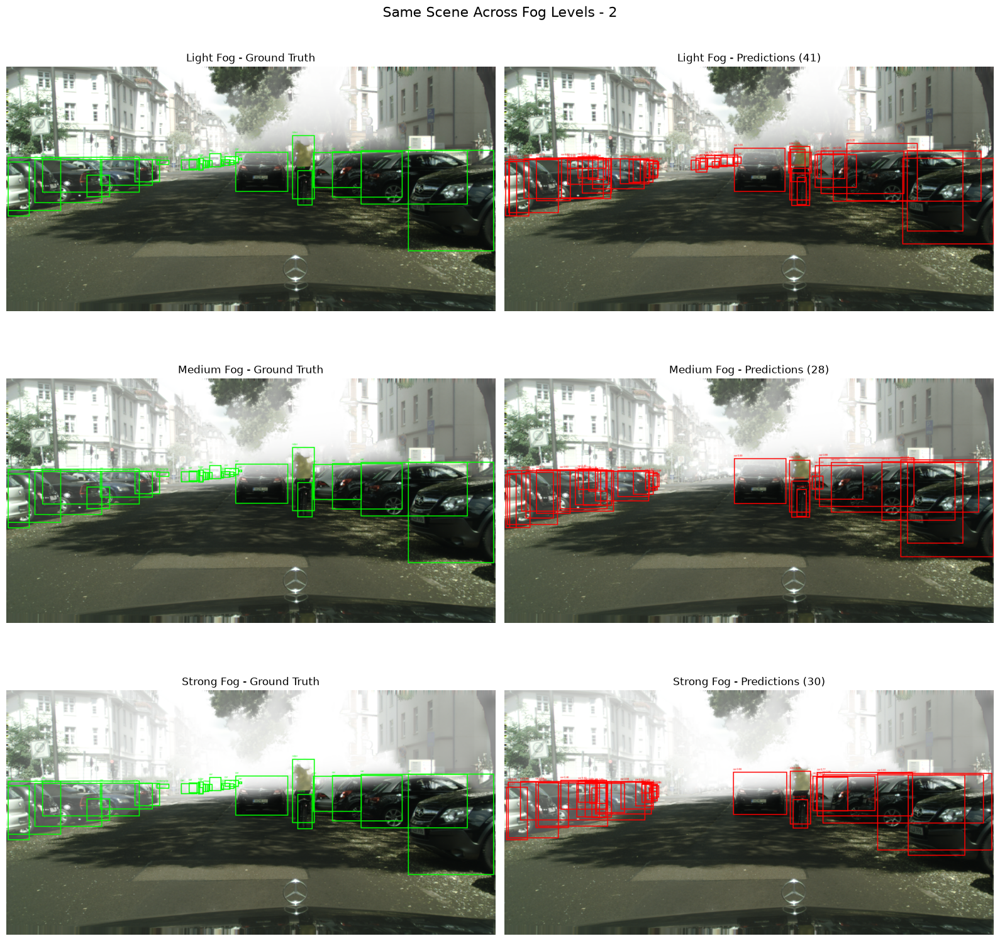

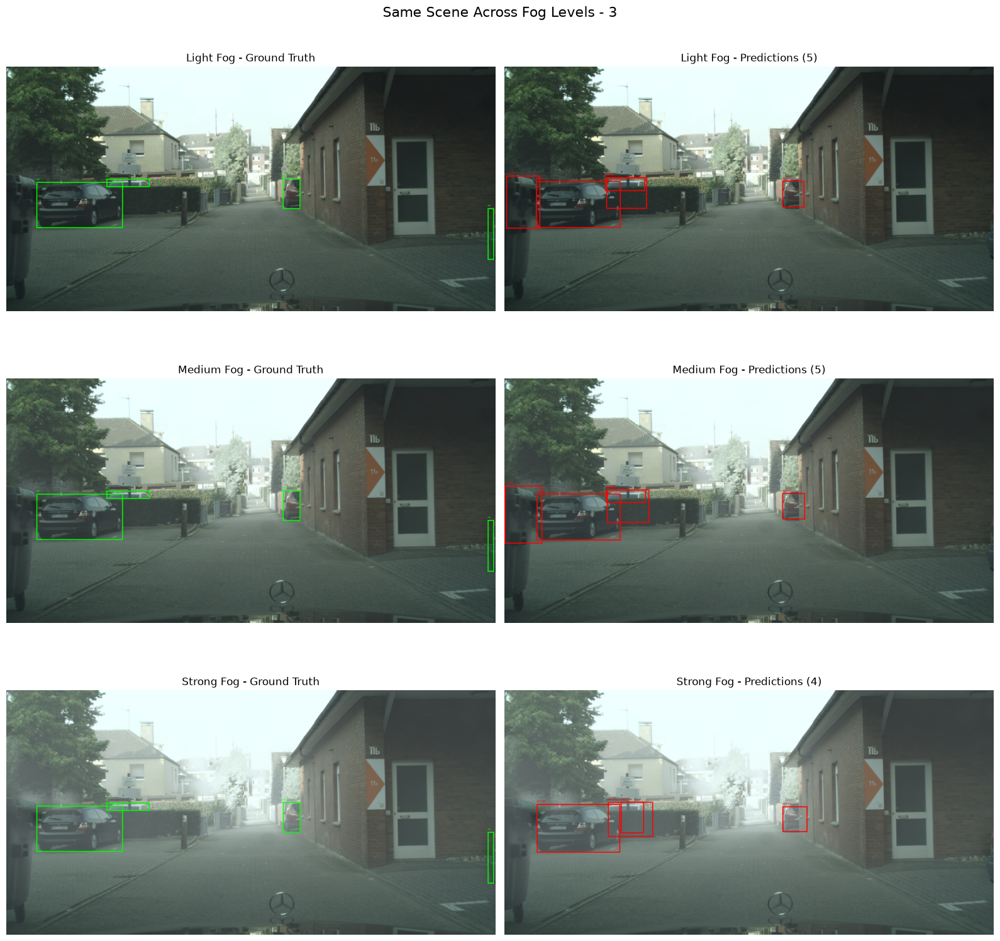


FINAL FOG-DENSITY COMPARISON
Fog         Beta      Images    mAP         AP50        AP75        
light       0.005     500       13.322      28.269      10.918      
medium      0.010     500       11.378      24.377      9.394       
strong      0.020     500       8.449       18.245      6.415       

FILES GENERATED
charts/01_total_loss.png
charts/02_loss_components.png
charts/03_classification_accuracy.png
charts/04_learning_rate.png
charts/05_overall_comparison.png
charts/06_fog_density_performance.png
charts/07_fog_density_comparison.png
charts/08_classwise_ap.png
evaluation_light/cityscapes_foggy_light_val_5000_coco_format.json
evaluation_light/cityscapes_foggy_light_val_5000_coco_format.json.lock
evaluation_light/coco_instances_results.json
evaluation_light/instances_predictions.pth
evaluation_medium/cityscapes_foggy_medium_val_5000_coco_format.json
evaluation_medium/cityscapes_foggy_medium_val_5000_coco_format.json.lock
evaluation_medium/coco_instances_results.json
evaluatio

In [62]:

# =====================================================================
# PHD EXPERIMENT: SOURCE-ONLY VISUALIZATION & FOG-DENSITY ANALYSIS
# Cityscapes -> Foggy Cityscapes
# Model: 5,000-iteration source-only checkpoint
#
# One cell:
#   - Load training metrics
#   - Generate learning curves
#   - Compare 1,000 vs 5,000 iterations
#   - Evaluate light / medium / strong fog
#   - Plot class-wise AP
#   - Visualize predictions and ground truth
#   - Save charts and result tables
#
# This cell DOES NOT perform training.
# =====================================================================

import os
import sys
import json
import csv
import math
import traceback
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# =====================================================================
# 1. PATHS
# =====================================================================

ROOT = Path("/workspace")

REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"

PILOT = (
    ROOT / "experiments/cityscapes_to_foggy/"
    "source_only/pilot_1000_v1"
)

RUN = (
    ROOT / "experiments/cityscapes_to_foggy/"
    "source_only/continuation_5000_v1"
)

CONFIG = RUN / "source_only_5000.yaml"

CHECKPOINT = RUN / "model_final.pth"

if not CHECKPOINT.exists():
    candidates = sorted(
        RUN.glob("model_*.pth"),
        key=lambda p: p.stat().st_mtime
    )
    if not candidates:
        raise FileNotFoundError(
            "No trained checkpoint found in " + str(RUN)
        )
    CHECKPOINT = candidates[-1]
    print("Using latest checkpoint:", CHECKPOINT.name)

OUTPUT = RUN / "visualization_and_fog_analysis"
CHARTS = OUTPUT / "charts"
PREDICTIONS = OUTPUT / "predictions"

for directory in [OUTPUT, CHARTS, PREDICTIONS]:
    directory.mkdir(parents=True, exist_ok=True)

assert CONFIG.exists(), CONFIG

print("=" * 72)
print("SOURCE-ONLY MODEL VISUALIZATION")
print("=" * 72)
print("Checkpoint:", CHECKPOINT)
print("Output:", OUTPUT)
print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")

# =====================================================================
# 2. IMPORT DETECTRON2 AND REGISTER DATASETS
# =====================================================================

COMPAT = PILOT / "python_compat"

sys.path.insert(0, str(REPO))
if COMPAT.exists():
    sys.path.insert(0, str(COMPAT))

os.environ["DETECTRON2_DATASETS"] = str(ROOT / "datasets")

from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data import build_detection_test_loader
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.modeling import build_model

from adapteacher import add_ateacher_config

# Import the project's model and dataset registration modules.
import adapteacher.modeling
import adapteacher.data.datasets.builtin

# =====================================================================
# 3. LOAD CONFIG AND CHECKPOINT
# =====================================================================

cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(CONFIG))

cfg.defrost()
cfg.MODEL.WEIGHTS = str(CHECKPOINT)
cfg.MODEL.DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)
cfg.DATALOADER.NUM_WORKERS = 0
cfg.freeze()

model = build_model(cfg)
DetectionCheckpointer(model).load(str(CHECKPOINT))
model.eval()

print("\nModel loaded successfully.")
print("Architecture:", cfg.MODEL.META_ARCHITECTURE)
print("Classes:", cfg.MODEL.ROI_HEADS.NUM_CLASSES)

# =====================================================================
# 4. HELPER FUNCTIONS
# =====================================================================

def load_metrics(path):
    if not path.exists():
        return []
    records = []
    for line in path.read_text().splitlines():
        try:
            item = json.loads(line)
            if isinstance(item, dict):
                records.append(item)
        except Exception:
            pass
    return records


def metric_points(records, key):
    points = [
        (int(r["iteration"]), float(r[key]))
        for r in records
        if "iteration" in r and key in r
    ]
    points.sort(key=lambda x: x[0])
    return points


def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        CHARTS / filename,
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


def plot_metric(records, keys, title, filename,
                ylabel="Value", multiplier=1):

    plt.figure(figsize=(12, 5))

    plotted = False

    for key in keys:
        points = metric_points(records, key)
        if not points:
            continue

        x = [p[0] for p in points]
        y = [p[1] * multiplier for p in points]

        plt.plot(x, y, label=key, linewidth=1.5)
        plotted = True

    if not plotted:
        plt.close()
        print("Skipped:", title, "(metric unavailable)")
        return

    plt.title(title)
    plt.xlabel("Training iteration")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    save_chart(filename)


# =====================================================================
# 5. LOAD TRAINING HISTORY
# =====================================================================

pilot_records = load_metrics(PILOT / "metrics.json")
run_records = load_metrics(RUN / "metrics.json")

# Keep pilot metrics through iteration 999 and continuation
# metrics from iteration 1000 onward.
history = {
    int(r["iteration"]): r
    for r in pilot_records + run_records
    if "iteration" in r
}

records = [history[k] for k in sorted(history)]

print("\nTraining metric records:", len(records))

if records:
    print("First logged iteration:", records[0]["iteration"])
    print("Last logged iteration:", records[-1]["iteration"])

# =====================================================================
# 6. TRAINING CHARTS
# =====================================================================

plot_metric(
    records,
    ["total_loss"],
    "Source-Only Training: Total Loss",
    "01_total_loss.png",
    ylabel="Total loss"
)

plot_metric(
    records,
    [
        "loss_cls",
        "loss_box_reg",
        "loss_rpn_cls",
        "loss_rpn_loc"
    ],
    "Source-Only Training: Loss Components",
    "02_loss_components.png",
    ylabel="Loss"
)

plot_metric(
    records,
    [
        "fast_rcnn/fg_cls_accuracy",
        "fast_rcnn/cls_accuracy"
    ],
    "Source-Only Training: Classification Accuracy",
    "03_classification_accuracy.png",
    ylabel="Accuracy (%)",
    multiplier=100
)

plot_metric(
    records,
    ["lr"],
    "Source-Only Training: Learning Rate",
    "04_learning_rate.png",
    ylabel="Learning rate"
)

# =====================================================================
# 7. OVERALL EVALUATION COMPARISON
# =====================================================================

# Existing evaluation values from the two completed runs.
# These are COCO AP values expressed as percentages.
pilot_overall = {
    "AP": 2.8196,
    "AP50": 7.9561,
    "AP75": 1.3448,
    "APs": 0.3691,
    "APm": 3.5725,
    "APl": 7.7040
}

extended_overall = {
    "AP": 10.6304,
    "AP50": 23.0012,
    "AP75": 8.4862,
    "APs": 0.82,
    "APm": 10.07,
    "APl": 27.25
}

metric_names = list(pilot_overall)

x = np.arange(len(metric_names))
width = 0.36

plt.figure(figsize=(12, 6))

plt.bar(
    x - width/2,
    [pilot_overall[k] for k in metric_names],
    width,
    label="1,000 iterations"
)

plt.bar(
    x + width/2,
    [extended_overall[k] for k in metric_names],
    width,
    label="5,000 iterations"
)

plt.xticks(x, metric_names)
plt.ylabel("Average Precision (%)")
plt.title("Source-Only Model: 1,000 vs 5,000 Iterations")
plt.legend()
plt.grid(axis="y", alpha=0.25)

save_chart("05_overall_comparison.png")

# =====================================================================
# 8. GET FOGGY VALIDATION RECORDS
# =====================================================================

BASE_DATASET = "cityscapes_foggy_val"

assert BASE_DATASET in DatasetCatalog.list(), (
    "Foggy validation dataset not registered."
)

all_records = DatasetCatalog.get(BASE_DATASET)

print("\nFoggy validation records:", len(all_records))

FOG_LEVELS = {
    "light": 0.005,
    "medium": 0.01,
    "strong": 0.02
}

fog_records = {name: [] for name in FOG_LEVELS}

for record in all_records:

    filename = record["file_name"]

    matched = False

    for level, beta in FOG_LEVELS.items():

        if f"beta_{beta}" in filename:
            fog_records[level].append(record)
            matched = True
            break

    if not matched:
        print("Unclassified fog image:", filename)

for level in FOG_LEVELS:
    print(
        level,
        "|",
        len(fog_records[level]),
        "images"
    )

assert all(len(v) == 500 for v in fog_records.values()), (
    "Expected 500 images per fog level."
)

# =====================================================================
# 9. REGISTER FOG-SPECIFIC DATASETS
# =====================================================================

base_metadata = MetadataCatalog.get(BASE_DATASET)
class_names = list(base_metadata.thing_classes)

registered_names = {}

for level, records_for_level in fog_records.items():

    dataset_name = f"cityscapes_foggy_{level}_val_5000"

    if dataset_name not in DatasetCatalog.list():

        subset = list(records_for_level)

        DatasetCatalog.register(
            dataset_name,
            lambda subset=subset: subset
        )

    # Copy essential metadata only, to avoid stale COCO JSON paths.
    MetadataCatalog.get(dataset_name).set(
        thing_classes=class_names,
        evaluator_type="coco"
    )

    registered_names[level] = dataset_name

# =====================================================================
# 10. EVALUATE EACH FOG DENSITY
# =====================================================================

RESULTS_JSON = OUTPUT / "fog_density_5000_results.json"

if RESULTS_JSON.exists():

    print("\nLoading previously saved fog-density results.")

    fog_results = json.loads(
        RESULTS_JSON.read_text()
    )

else:

    fog_results = {}

    for level, beta in FOG_LEVELS.items():

        print("\n" + "=" * 70)
        print(
            f"EVALUATING {level.upper()} FOG "
            f"(beta={beta})"
        )
        print("=" * 70)

        dataset_name = registered_names[level]

        evaluation_dir = OUTPUT / f"evaluation_{level}"
        evaluation_dir.mkdir(exist_ok=True)

        evaluator = COCOEvaluator(
            dataset_name,
            output_dir=str(evaluation_dir)
        )

        loader = build_detection_test_loader(
            cfg,
            dataset_name
        )

        result = inference_on_dataset(
            model,
            loader,
            evaluator
        )

        bbox = result.get("bbox", {})

        fog_results[level] = {
            "beta": beta,
            "images": len(fog_records[level]),
            "metrics": {
                k: float(v)
                for k, v in bbox.items()
            }
        }

        RESULTS_JSON.write_text(
            json.dumps(fog_results, indent=2)
        )

        print(
            f"{level}: "
            f"mAP={bbox.get('AP', float('nan')):.3f}, "
            f"AP50={bbox.get('AP50', float('nan')):.3f}"
        )

# =====================================================================
# 11. SAVE FOG RESULTS AS CSV
# =====================================================================

csv_path = OUTPUT / "fog_density_5000_results.csv"

with csv_path.open("w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "fog_level",
        "beta",
        "images",
        "AP",
        "AP50",
        "AP75",
        "APs",
        "APm",
        "APl"
    ])

    for level in FOG_LEVELS:

        item = fog_results[level]
        m = item["metrics"]

        writer.writerow([
            level,
            item["beta"],
            item["images"],
            m.get("AP"),
            m.get("AP50"),
            m.get("AP75"),
            m.get("APs"),
            m.get("APm"),
            m.get("APl")
        ])

# =====================================================================
# 12. FOG-DENSITY PERFORMANCE CHART
# =====================================================================

levels = list(FOG_LEVELS)

map_values = [
    fog_results[k]["metrics"]["AP"]
    for k in levels
]

ap50_values = [
    fog_results[k]["metrics"]["AP50"]
    for k in levels
]

x = np.arange(len(levels))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    map_values,
    width,
    label="mAP (AP50:95)"
)

plt.bar(
    x + width/2,
    ap50_values,
    width,
    label="AP50"
)

plt.xticks(
    x,
    [
        f"{k.title()}\nβ={FOG_LEVELS[k]}"
        for k in levels
    ]
)

plt.ylabel("Average Precision (%)")
plt.title("5,000-Iteration Model: Performance by Fog Density")
plt.legend()
plt.grid(axis="y", alpha=0.25)

save_chart("06_fog_density_performance.png")

# =====================================================================
# 13. COMPARE 1,000 VS 5,000 ACROSS FOG DENSITIES
# =====================================================================

pilot_fog = {
    "light": 3.5045632518560055,
    "medium": 3.1337770185777,
    "strong": 2.1723312212213437
}

plt.figure(figsize=(11, 6))

plt.plot(
    levels,
    [pilot_fog[k] for k in levels],
    marker="o",
    linewidth=2,
    label="1,000 iterations"
)

plt.plot(
    levels,
    map_values,
    marker="o",
    linewidth=2,
    label="5,000 iterations"
)

plt.xlabel("Fog density")
plt.ylabel("mAP (AP50:95) %")
plt.title("Fog Sensitivity: 1,000 vs 5,000 Iterations")
plt.legend()
plt.grid(alpha=0.3)

save_chart("07_fog_density_comparison.png")

# =====================================================================
# 14. CLASS-WISE AP CHART
# =====================================================================

class_metrics = [
    f"AP-{name}" for name in class_names
]

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(15, 6))

for i, level in enumerate(levels):

    values = [
        fog_results[level]["metrics"].get(
            f"AP-{name}", np.nan
        )
        for name in class_names
    ]

    plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=level.title()
    )

plt.xticks(
    x,
    class_names,
    rotation=30,
    ha="right"
)

plt.ylabel("Average Precision (%)")
plt.title("Class-wise AP by Fog Density")
plt.legend()
plt.grid(axis="y", alpha=0.25)

save_chart("08_classwise_ap.png")

# =====================================================================
# 15. PREPARE MODEL PREDICTIONS
# =====================================================================

from detectron2.data import detection_utils as utils
from detectron2.structures import BoxMode

# Direct inference avoids a second model load.
# Use the same image preprocessing as the validation mapper.

def predict_image(image_path):

    image_bgr = utils.read_image(
        str(image_path),
        format=cfg.INPUT.FORMAT
    )

    original_h, original_w = image_bgr.shape[:2]

    from detectron2.data.transforms import ResizeShortestEdge

    augmentation = ResizeShortestEdge(
        cfg.INPUT.MIN_SIZE_TEST,
        cfg.INPUT.MAX_SIZE_TEST
    )

    transform = augmentation.get_transform(image_bgr)

    resized = transform.apply_image(image_bgr)

    tensor = torch.as_tensor(
        resized.astype("float32").transpose(2, 0, 1)
    )

    inputs = [{
        "image": tensor,
        "height": original_h,
        "width": original_w
    }]

    with torch.no_grad():
        output = model(inputs)[0]

    return output["instances"].to("cpu")


def resolve_image_path(path):

    path = Path(path)

    if path.is_file():
        return path

    candidate = ROOT / path

    if candidate.is_file():
        return candidate

    # Handle dataset paths stored as datasets/...
    candidate = ROOT / str(path).lstrip("/")

    if candidate.is_file():
        return candidate

    raise FileNotFoundError(str(path))


def draw_ground_truth(image, record):

    canvas = image.copy()
    draw = ImageDraw.Draw(canvas)

    for ann in record.get("annotations", []):

        box = ann.get("bbox")
        if box is None:
            continue

        mode = ann.get("bbox_mode", BoxMode.XYWH_ABS)

        xyxy = BoxMode.convert(
            box,
            mode,
            BoxMode.XYXY_ABS
        )

        class_id = ann.get("category_id", -1)

        label = (
            class_names[class_id]
            if 0 <= class_id < len(class_names)
            else str(class_id)
        )

        draw.rectangle(
            list(map(float, xyxy)),
            outline="lime",
            width=4
        )

        draw.text(
            (float(xyxy[0]), max(0, float(xyxy[1]) - 18)),
            label,
            fill="lime"
        )

    return canvas


def draw_predictions(image, instances, threshold=0.35):

    canvas = image.copy()
    draw = ImageDraw.Draw(canvas)

    boxes = instances.pred_boxes.tensor.numpy()
    classes = instances.pred_classes.numpy()
    scores = instances.scores.numpy()

    count = 0

    for box, class_id, score in zip(
        boxes, classes, scores
    ):

        if score < threshold:
            continue

        x1, y1, x2, y2 = map(float, box)

        label = (
            class_names[int(class_id)]
            if 0 <= int(class_id) < len(class_names)
            else str(class_id)
        )

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=4
        )

        draw.text(
            (x1, max(0, y1 - 18)),
            f"{label} {score:.2f}",
            fill="red"
        )

        count += 1

    return canvas, count


# =====================================================================
# 16. VISUALIZE MATCHED SCENES ACROSS FOG LEVELS
# =====================================================================

# Select the same scene at all three fog densities.
# This makes visual comparisons more meaningful.

def scene_key(record):

    filename = Path(record["file_name"]).name

    for beta in FOG_LEVELS.values():
        filename = filename.replace(
            f"_foggy_beta_{beta}", ""
        )

    return filename


scene_lookup = defaultdict(dict)

for level, records_for_level in fog_records.items():

    for record in records_for_level:

        scene_lookup[scene_key(record)][level] = record

complete_scenes = [
    key
    for key, items in scene_lookup.items()
    if all(level in items for level in FOG_LEVELS)
]

complete_scenes.sort()

# Use three deterministic scenes spread through the dataset.
if complete_scenes:

    indices = np.linspace(
        0,
        len(complete_scenes) - 1,
        min(3, len(complete_scenes)),
        dtype=int
    )

    selected_scenes = [
        complete_scenes[i]
        for i in indices
    ]

    for scene_index, key in enumerate(selected_scenes):

        fig, axes = plt.subplots(
            3,
            2,
            figsize=(16, 16)
        )

        for row, level in enumerate(levels):

            record = scene_lookup[key][level]

            image_path = resolve_image_path(
                record["file_name"]
            )

            image = Image.open(image_path).convert("RGB")

            gt_image = draw_ground_truth(
                image,
                record
            )

            instances = predict_image(image_path)

            pred_image, count = draw_predictions(
                image,
                instances,
                threshold=0.35
            )

            axes[row, 0].imshow(gt_image)
            axes[row, 0].set_title(
                f"{level.title()} Fog - Ground Truth"
            )

            axes[row, 1].imshow(pred_image)
            axes[row, 1].set_title(
                f"{level.title()} Fog - "
                f"Predictions ({count})"
            )

            axes[row, 0].axis("off")
            axes[row, 1].axis("off")

        fig.suptitle(
            f"Same Scene Across Fog Levels - {scene_index + 1}",
            fontsize=16
        )

        plt.tight_layout()

        save_path = (
            PREDICTIONS /
            f"scene_{scene_index + 1:02d}.png"
        )

        plt.savefig(
            save_path,
            dpi=160,
            bbox_inches="tight"
        )

        plt.show()
        plt.close()

else:

    print(
        "No complete matched scenes found. "
        "Prediction visualization skipped."
    )

# =====================================================================
# 17. PRINT FINAL RESULTS
# =====================================================================

print("\n" + "=" * 76)
print("FINAL FOG-DENSITY COMPARISON")
print("=" * 76)

print(
    f"{'Fog':<12}"
    f"{'Beta':<10}"
    f"{'Images':<10}"
    f"{'mAP':<12}"
    f"{'AP50':<12}"
    f"{'AP75':<12}"
)

for level in levels:

    item = fog_results[level]
    m = item["metrics"]

    print(
        f"{level:<12}"
        f"{item['beta']:<10.3f}"
        f"{item['images']:<10}"
        f"{m.get('AP', float('nan')):<12.3f}"
        f"{m.get('AP50', float('nan')):<12.3f}"
        f"{m.get('AP75', float('nan')):<12.3f}"
    )

print("\n" + "=" * 76)
print("FILES GENERATED")
print("=" * 76)

for path in sorted(OUTPUT.rglob("*")):

    if path.is_file():
        print(path.relative_to(OUTPUT))

print("\n" + "=" * 76)
print("EXPERIMENT COMPLETED")
print("=" * 76)

print("Model checkpoint:", CHECKPOINT)
print("Results:", RESULTS_JSON)
print("CSV:", csv_path)
print("Charts:", CHARTS)
print("Prediction visualizations:", PREDICTIONS)
print("No training was performed.")
